# VeriStamp · M1 folds 2 and 3: the final experiment with a different unseen generator

**DATA 255 · Group 7.** The proposal's leave-one-generator-out evaluation has 3 folds. Fold 1 is `m1_final_n500`
(unseen Stable Diffusion v1.4), already done. This notebook runs **the same final experiment** for the other two:

| Fold | Seen (train / val / test_seen) | Unseen (test only) | Run name |
|---|---|---|---|
| 1 | ADM + VQDM | Stable Diffusion v1.4 | `m1_final_n500` (done, protected) |
| **2** | VQDM + Stable Diffusion v1.4 | **ADM** | `m1_final_n500_unseen_adm` |
| **3** | ADM + Stable Diffusion v1.4 | **VQDM** | `m1_final_n500_unseen_vqdm` |

**Identical to fold 1:** dataset folder (`Datasets/GenImage_native_n500`, read only), 500 images per class per generator,
seed 42, frozen preprocessing (native 224 crop + equal JPEG 75–95, 4:2:0), RGB baseline + M1, all training settings,
sanity checks, metrics, JPEG 65/30 test, Grad-CAM and final verification. **Only the unseen generator changes.**

> **Nothing is tuned.** Preprocessing and settings were frozen before fold 1. Fold 2 and 3 results are only reported.

### Nothing earlier is changed
- **No Section 0:** the images were extracted and the labels confirmed for fold 1. `DATASET_SETUP.json` is only read; the dataset folder is never written.
- New split, cache, manifests, experiment folder and library copy (`VeriStamp/vslib_m1_folds`) per fold.
- Section 2b records fold 1 (`m1_final_n500`: run, split, cache, manifests, library, features), the four earlier runs and **the dataset folder**. Section 27 checks that none of them changed.

> Wherever a markdown cell below still says "Stable Diffusion" for the unseen test set, read **the unseen generator of this fold**. The code uses `UNSEEN_GENERATOR` everywhere.

**How to run:** Runtime → Change runtime type → A100 GPU. Set `FOLD` in Section 1, then Runtime → Run all.
After fold 2 finishes, download the notebook (with outputs), set `FOLD = 3`, restart the runtime and run all again.

## 1 · Project configuration
**Purpose:** every setting in one place, saved as `config.yaml` with each model.

✏️ **Change only `FOLD`**: `2` (unseen ADM) or `3` (unseen VQDM). Everything else is fixed to the fold 1 values.
`RESUME = False` makes the notebook refuse to write into a run folder that already has results; set it to `True` only to continue an interrupted run of the SAME fold.

In [1]:
# ╔════════════════════════════════════════════════════════════════════════╗
# ║   VALUES YOU MUST CHECK OR CHANGE  (marked  <<< CHANGE)                 ║
# ╚════════════════════════════════════════════════════════════════════════╝
FOLD        = 2      # <<< CHANGE: 2 = unseen ADM, 3 = unseen VQDM (fold 1 = m1_final_n500, done)
DATA_ROOT   = "/content/drive/MyDrive/Datasets/GenImage_native_n500"   # the fold 1 dataset folder (read only)
PROJECT_DIR = "/content/drive/MyDrive/VeriStamp"
N_PER_CLASS = 500    # same as fold 1
EPOCHS      = 10     # maximum epochs (early stopping may stop sooner)
RESUME      = False  # True only to continue an interrupted run of the SAME experiment
REFERENCE_RUN = "m1_run_001"     # only PROTECTED here (its test images are Stable Diffusion, not this fold's unseen generator)
REFERENCE_SPLIT_DIR = f"{PROJECT_DIR}/data/splits/genimage_unseen-stable_diffusion_v_1_4_n200_seed42"
# ══════════════════════════════════════════════════════════════════════════

SEED = 42
FOLDS = {2: {"unseen": "ADM", "run": "m1_final_n500_unseen_adm"},
         3: {"unseen": "VQDM", "run": "m1_final_n500_unseen_vqdm"}}
assert FOLD in FOLDS, "FOLD must be 2 or 3 (fold 1 is m1_final_n500 and is never rerun here)"
FOLD1_RUN = "m1_final_n500"                              # fold 1 (unseen Stable Diffusion v1.4): read only
FOLD_UNSEEN = FOLDS[FOLD]["unseen"]
EXPERIMENT = FOLDS[FOLD]["run"]
EXPERIMENTS = {f["run"]: {"mode": "native", "fold": k, "unseen": f["unseen"],
                          "description": f"final setup, fold {k} (unseen {f['unseen']}): native 224x224 crops, "
                                         "no enlargement, equal JPEG (4:2:0), 500 per class"} for k, f in FOLDS.items()}
PREVIOUS_NATIVE_RUN = "m1_native_crop_equal_jpeg"       # same preprocessing, 200 per class (read only)
PROTECTED_RUNS = ["m1_run_001", "m1_random_rescale", "m1_resize_vqdm", PREVIOUS_NATIVE_RUN, FOLD1_RUN]   # read, never written
OTHER_FOLD_RUNS = [f["run"] for k, f in FOLDS.items() if k != FOLD]   # the other new fold: read only (cross-fold table)
RUN_NAME = EXPERIMENT
assert RUN_NAME not in PROTECTED_RUNS

COMMON_PRE = {"crop_size": 224, "jpeg_quality_range": [75, 95],   # 75-95 = the range m1_run_001 used
              "train_hflip": True, "train_rescale_range": None, "min_side": 224}
PRESETS = {
    "resize": {**COMMON_PRE, "mode": "resize", "resize_short_side": 256, "cache_size": 256},   # = m1_run_001
    "native": {**COMMON_PRE, "mode": "native", "tile_size": 256, "align": 8, "jpeg_subsampling": "4:2:0",
               "legacy_resize_short_side": 256},   # only used to REPORT which images the old pipeline enlarged
}

CONFIG = {
    "project": {"name": "VeriStamp", "component": "M1", "run_name": RUN_NAME},
    "experiment": {"name": RUN_NAME, **EXPERIMENTS[RUN_NAME], "reference_run": REFERENCE_RUN,
                   "fold1_run": FOLD1_RUN,
                   "note": "Same setup as m1_final_n500; only the unseen generator differs. Preprocessing frozen (chosen in m1_native_crop_equal_jpeg). Test sets are only reported, never used for tuning."},
    "seed": SEED,
    "paths": {
        "data_root": DATA_ROOT,
        "project_dir": PROJECT_DIR,
        "splits_dir": f"{PROJECT_DIR}/data/splits",
        "manifests_dir": f"{PROJECT_DIR}/data/manifests/{RUN_NAME}",    # per run: the shared reports are not overwritten
        "experiments_dir": f"{PROJECT_DIR}/experiments",
        "cache_local": "/content/cache",
        "cache_drive": f"{PROJECT_DIR}/cache",
        "lib_drive": f"{PROJECT_DIR}/vslib_m1_folds",                    # separate copy: vslib_m1_final (fold 1) stays as it is
        "reference_split_dir": REFERENCE_SPLIT_DIR,
    },
    "data": {
        "dataset": "genimage",
        "selected_generators": None, "dataset_subset_level": None,      # filled from Section 0 in Section 4
        "seen_generators": None, "replacement_generator": None,         # filled in Section 4
        "folder_rules": None, "ignore_folders": [],
        "unseen_generator": None,
        "n_per_class": N_PER_CLASS,
        "min_side": COMMON_PRE["min_side"],                             # smaller images are excluded, never enlarged
        "fractions": {"train": 0.70, "val": 0.15, "test_seen": 0.15},
        "oversample": 1.3,
        "drop_near_duplicates": True,
        "hash_workers": 16,
    },
    "preprocess": PRESETS[EXPERIMENTS[RUN_NAME]["mode"]],
    "features": {"hp_kernel": 5, "hp_sigma": 1.0, "stats_batches": 20},
    "model": {"arch": "resnet50", "pretrained": True, "weights": "IMAGENET1K_V2", "dropout": 0.3},
    "train": {
        "epochs": EPOCHS, "batch_size": 64, "cpu_batch_size": 8,
        "lr_backbone": 1e-4, "lr_new": 1e-3, "weight_decay": 1e-4,
        "warmup_epochs": 1, "early_stop_patience": 3, "num_workers": 2,
        "max_train_batches": None, "max_val_batches": None,
    },
    "sanity": {"overfit_images": 32, "overfit_steps_gpu": 80, "overfit_steps_cpu": 30,
               "shuffled_train_images": 512, "shuffled_epochs": 2},
    "runs": {"modes": ["rgb", "hp_fft"]},   # RGB baseline + M1
    "degradation": {"jpeg_qualities": [65, 30], "subsampling": "4:2:0",    # GenImage degradation track (Section 24)
                    "splits": ["test_seen", "test_unseen"]},
    "gradcam": {"layer": "backbone.layer4", "n_per_group": 4, "n_average": 64},   # Section 25
}
_p = CONFIG["preprocess"]
assert _p["crop_size"] <= (_p["cache_size"] if _p["mode"] == "resize" else _p["tile_size"])
print(f"FOLD {FOLD}: unseen {FOLD_UNSEEN} | run {RUN_NAME}")
print(f"Experiment: {RUN_NAME}  ({EXPERIMENTS[RUN_NAME]['description']})")
print(f"Images per class per generator: {N_PER_CLASS}   max epochs: {EPOCHS}   resume: {RESUME}")
print("Preprocessing:", CONFIG["preprocess"])
print("Models to train:", CONFIG["runs"]["modes"])
print("Degradation test:", CONFIG["degradation"]["jpeg_qualities"], "| Grad-CAM:", CONFIG["gradcam"])

FOLD 2: unseen ADM | run m1_final_n500_unseen_adm
Experiment: m1_final_n500_unseen_adm  (final setup, fold 2 (unseen ADM): native 224x224 crops, no enlargement, equal JPEG (4:2:0), 500 per class)
Images per class per generator: 500   max epochs: 10   resume: False
Preprocessing: {'crop_size': 224, 'jpeg_quality_range': [75, 95], 'train_hflip': True, 'train_rescale_range': None, 'min_side': 224, 'mode': 'native', 'tile_size': 256, 'align': 8, 'jpeg_subsampling': '4:2:0', 'legacy_resize_short_side': 256}
Models to train: ['rgb', 'hp_fft']
Degradation test: [65, 30] | Grad-CAM: {'layer': 'backbone.layer4', 'n_per_group': 4, 'n_average': 64}


**Expected output:** one line with your run name, `N_PER_CLASS` and epochs, then `Models to train: ['rgb', 'hp_fft']`.

## 2 · Install / import packages, and write the shared code library
**Purpose:** Colab already includes PyTorch, torchvision, scikit-learn, pandas, matplotlib, Pillow, PyYAML and tqdm, so nothing needs installing.

This section:
1. connects Google Drive
2. writes the reusable modules into `vslib/`, one cell per module, each starting with `%%writefile`
3. imports them and saves a copy to Drive, where M2, Fusion and M3 notebooks will import the same code

Each module has comments. The important functions are explained again, with pictures, in the section where they are used.

In [2]:
import os, sys, shutil, importlib, json, math, time, random
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Not running in Colab: skipping Google Drive mount.")

os.makedirs("vslib", exist_ok=True)
print("Writing the library to:", os.path.abspath("vslib"))

Mounted at /content/drive
Writing the library to: /content/vslib


**2.1 · `vs_common.py`**: shared utilities for EVERY VeriStamp model (M1, M2, Fusion, M3).

In [3]:
%%writefile vslib/vs_common.py
"""vs_common: shared utilities for EVERY VeriStamp model (M1, M2, Fusion, M3).

Seeds, device + mixed-precision choice, run folders, checkpoints,
JSON/YAML/CSV saving, environment info and the experiment log.
Nothing here is specific to one model or one dataset.
"""
from __future__ import annotations

import datetime
import inspect
import json
import math
import os
import platform
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import yaml


def now() -> str:
    return datetime.datetime.now().isoformat(timespec="seconds")


def set_seed(seed: int) -> None:
    """Make Python, NumPy and PyTorch random numbers repeatable."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)          # safe to call without a GPU
    os.environ["PYTHONHASHSEED"] = str(seed)


def get_device() -> torch.device:
    """CUDA GPU (Colab) -> Apple GPU (Mac) -> CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def amp_settings(device: torch.device) -> dict:
    """Mixed precision: bfloat16 on A100-class GPUs, float16 + GradScaler on older GPUs, off on CPU."""
    if device.type == "cuda":
        if torch.cuda.is_bf16_supported():
            return {"enabled": True, "dtype": torch.bfloat16, "use_scaler": False}
        return {"enabled": True, "dtype": torch.float16, "use_scaler": True}
    return {"enabled": False, "dtype": torch.float32, "use_scaler": False}


def clean(obj):
    """Turn Paths, NumPy numbers, dtypes and NaN into plain JSON/YAML values."""
    if isinstance(obj, dict):
        return {str(k): clean(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [clean(v) for v in obj]
    if isinstance(obj, (Path, str)):
        return str(obj)                    # also turns str subclasses (e.g. torch.__version__) into plain str
    if isinstance(obj, (bool, np.bool_)):
        return bool(obj)
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, (float, np.floating)):
        v = float(obj)
        return None if (math.isnan(v) or math.isinf(v)) else v
    if isinstance(obj, torch.dtype):
        return str(obj)
    if isinstance(obj, torch.Tensor):
        return clean(obj.tolist())
    return obj


def save_json(obj, path) -> None:
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(clean(obj), indent=2))


def load_json(path):
    return json.loads(Path(path).read_text())


def save_yaml(obj, path) -> None:
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        yaml.safe_dump(clean(obj), f, sort_keys=False)


def load_yaml(path):
    with open(path) as f:
        return yaml.safe_load(f)


def environment_info() -> dict:
    info = {"timestamp": now(), "python": platform.python_version(), "torch": torch.__version__,
            "cuda_available": torch.cuda.is_available(), "device": str(get_device())}
    if torch.cuda.is_available():
        info["gpu"] = torch.cuda.get_device_name(0)
        info["gpu_memory_gb"] = round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1)
    return info


def make_run_dir(path, resume: bool = True) -> Path:
    """Create <run>/ and <run>/plots/. Refuses to reuse a non-empty folder unless resume=True."""
    path = Path(path)
    if path.exists() and any(path.iterdir()) and not resume:
        raise FileExistsError(f"{path} already exists. Choose a new RUN_NAME, or set RESUME = True to continue it.")
    (path / "plots").mkdir(parents=True, exist_ok=True)
    return path


def save_checkpoint(path, state: dict) -> None:
    """Save to a temporary file, then rename: a crash mid-save cannot corrupt the previous checkpoint."""
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    torch.save(state, tmp)
    os.replace(tmp, path)


def load_checkpoint(path, device="cpu") -> dict:
    return torch.load(path, map_location=device, weights_only=False)


def append_csv_row(path, row: dict) -> None:
    """Append one row to a CSV log (creates it, and adds new columns when needed)."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    new = pd.DataFrame([clean(row)])
    if path.exists() and path.stat().st_size > 0:
        new = pd.concat([pd.read_csv(path), new], ignore_index=True)
    new.to_csv(path, index=False)


def df_to_markdown(df, floatfmt: str = ".4f") -> str:
    """A pandas table as a Markdown table (no extra packages needed)."""
    cols = list(df.columns)
    fmt = lambda v: format(v, floatfmt) if isinstance(v, (float, np.floating)) else str(v)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(fmt(r[c]) for c in cols) + " |" for _, r in df.iterrows()]
    return "\n".join(lines)


def show_source(fn) -> None:
    """Print a function's code (used to explain library functions inside the notebook)."""
    print(inspect.getsource(fn))

Writing vslib/vs_common.py


**2.2 · `vs_data.py`**: generic image-folder utilities (scanning, hashing, duplicate detection).

In [4]:
%%writefile vslib/vs_data.py
"""vs_data: generic image-folder utilities (scanning, hashing, duplicate detection).

Dataset-agnostic on purpose: used for GenImage now (M1, M2, Fusion) and for the
separate COCO manifest that M3 will build later.
"""
from __future__ import annotations

import hashlib
import io
import os
import random
import statistics
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".webp", ".bmp", ".tif", ".tiff"}


def _skipped(rel, skip):
    return any(rel == s or rel.startswith(s.rstrip("/") + "/") for s in skip)


def scan_image_folders(root, skip=()):
    """Walk `root` once. Returns ({relative folder: [image file names]}, Counter of non-image extensions).
    Folders listed in `skip` (relative to root) are not entered at all, e.g. generators you did not select."""
    root = Path(root)
    folders, others = {}, Counter()
    for dirpath, dirnames, filenames in os.walk(root):
        rel = Path(dirpath).relative_to(root).as_posix()  # "." means DATA_ROOT itself
        dirnames[:] = sorted(d for d in dirnames if not _skipped(d if rel == "." else f"{rel}/{d}", skip))
        imgs = sorted(f for f in filenames if Path(f).suffix.lower() in IMAGE_EXTS and not f.startswith("."))
        if imgs:
            folders[rel] = imgs
        for f in filenames:
            ext = Path(f).suffix.lower()
            if ext not in IMAGE_EXTS:
                others[ext or "(no extension)"] += 1
    return folders, others


def print_tree(folders, root_label, max_depth=4, max_lines=150):
    """Folder tree; each number includes all sub-folders."""
    below = Counter()
    for rel, files in folders.items():
        parts = () if rel == "." else tuple(rel.split("/"))
        for d in range(min(len(parts), max_depth) + 1):
            below[parts[:d]] += len(files)
    for i, parts in enumerate(sorted(below)):
        if i >= max_lines:
            print(f"... ({len(below) - max_lines} more lines; raise max_lines to see them)")
            break
        name = parts[-1] if parts else root_label
        print("    " * len(parts) + f"{name}/  {below[parts]:,} images")


def folder_stats(root, folders, per_folder=20, max_folders=40, seed=0) -> pd.DataFrame:
    """Sample a few images per folder: size, file format, colour mode (reads headers only)."""
    rng, root, rows = random.Random(seed), Path(root), []
    for rel, files in list(folders.items())[:max_folders]:
        w, h, modes, fmts, broken = [], [], Counter(), Counter(), 0
        for f in rng.sample(files, min(per_folder, len(files))):
            try:
                with Image.open(root / rel / f) as im:
                    w.append(im.size[0]); h.append(im.size[1])
                    modes[im.mode] += 1; fmts[im.format] += 1
            except Exception:
                broken += 1
        rows.append({"folder": rel, "images": len(files),
                     "width_median": statistics.median(w) if w else None,
                     "width_range": f"{min(w)}-{max(w)}" if w else "",
                     "height_median": statistics.median(h) if h else None,
                     "height_range": f"{min(h)}-{max(h)}" if h else "",
                     "formats": dict(fmts), "modes": dict(modes), "unreadable": broken})
    return pd.DataFrame(rows)


def shared_name_report(folders, top=10):
    """How many file NAMES occur in more than one folder (a hint of duplicate photos)."""
    name_to = defaultdict(set)
    for rel, files in folders.items():
        for f in files:
            name_to[f].add(rel)
    shared = [fs for fs in name_to.values() if len(fs) > 1]
    pairs = Counter()
    for fs in shared[:50_000]:
        fs = sorted(fs)
        for i in range(len(fs)):
            for j in range(i + 1, len(fs)):
                pairs[(fs[i], fs[j])] += 1
    return len(shared), pairs.most_common(top)


def _dhash(img, n: int = 16) -> str:
    """256-bit 'difference hash' (64 hex characters): does each pixel of a 17x16 grey thumbnail get
    brighter or darker to the right? Re-saved or resized copies of one picture differ in only a few
    bits; different pictures differ in many (tested: copies <= 10 bits, different photos >= 47)."""
    g = np.asarray(img.convert("L").resize((n + 1, n), Image.BILINEAR), dtype=np.int16)
    bits = (g[:, 1:] > g[:, :-1]).flatten()
    return f"{int(''.join('1' if b else '0' for b in bits), 2):0{n * n // 4}x}"


def near_duplicate_groups(df, max_distance: int = 12, hash_col: str = "dhash") -> pd.Series:
    """Group near-identical images: dHash Hamming distance <= max_distance.

    Returns a Series (same index as df) with a group number for images that have at least one
    near-copy, and NaN otherwise. Fast on large sets: the 256 bits are cut into 16 bands; two
    hashes within 12 bits of each other must share at least one band exactly, so only images
    sharing a band are compared.
    """
    h = df[hash_col].dropna()
    ids, hashes = list(h.index), [int(x, 16) for x in h]
    parent = list(range(len(ids)))

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    hexes = list(h)
    n_bands = 16
    width = len(hexes[0]) // n_bands if hexes else 0
    for band in range(n_bands):
        buckets = defaultdict(list)
        for i, x in enumerate(hexes):
            buckets[x[band * width:(band + 1) * width]].append(i)
        for members in buckets.values():
            if len(members) < 2 or len(members) > 2000:
                continue
            for a_i in range(len(members)):
                for b_i in range(a_i + 1, len(members)):
                    a, b = members[a_i], members[b_i]
                    if bin(hashes[a] ^ hashes[b]).count("1") <= max_distance:
                        parent[find(a)] = find(b)
    roots = [find(i) for i in range(len(ids))]
    sizes = Counter(roots)
    out = pd.Series(np.nan, index=df.index)
    for i, r in enumerate(roots):
        if sizes[r] > 1:
            out.at[ids[i]] = r
    return out


def file_info(path) -> dict:
    """Read a file ONCE: SHA-1 of its bytes (exact duplicates), size, format, colour mode, dHash."""
    info = {"file_hash": None, "file_bytes": None, "width": None, "height": None,
            "file_format": None, "color_mode": None, "dhash": None, "readable": False, "error": None}
    try:
        data = Path(path).read_bytes()
        info["file_hash"] = hashlib.sha1(data).hexdigest()
        info["file_bytes"] = len(data)
        with Image.open(io.BytesIO(data)) as im:
            info.update(width=im.size[0], height=im.size[1], file_format=im.format, color_mode=im.mode)
            info["dhash"] = _dhash(im)
        info["readable"] = True
    except Exception as e:
        info["error"] = f"{type(e).__name__}: {e}"[:200]
    return info


def add_file_info(df: pd.DataFrame, path_col="image_path", workers=16) -> pd.DataFrame:
    """Run file_info on every row, in parallel threads (Drive is slow; threads hide the waiting)."""
    paths = df[path_col].tolist()
    with ThreadPoolExecutor(max_workers=workers) as ex:
        infos = list(tqdm(ex.map(file_info, paths), total=len(paths), desc="Hashing + reading headers"))
    info_df = pd.DataFrame(infos, index=df.index)
    return pd.concat([df.drop(columns=[c for c in info_df.columns if c in df.columns]), info_df], axis=1)


def mark_duplicates(df: pd.DataFrame, label_col="label") -> pd.DataFrame:
    """Add `status`: ok | unreadable | duplicate | label_conflict.

    Files with identical bytes (same SHA-1) are the same image. We keep ONE copy
    (the first by image_id) and mark the rest 'duplicate', so the same image can
    never appear in two splits. If identical files carry different labels, every
    copy is 'label_conflict' and excluded.
    """
    df = df.copy()
    df["status"] = np.where(df["readable"], "ok", "unreadable")
    df["duplicate_of"] = None
    readable = df[df["readable"]]
    dup = readable[readable["file_hash"].duplicated(keep=False)].sort_values("image_id")
    for _, g in dup.groupby("file_hash"):
        if label_col in g and g[label_col].nunique() > 1:
            df.loc[g.index, "status"] = "label_conflict"
        else:
            df.loc[g.index[1:], "status"] = "duplicate"
            df.loc[g.index[1:], "duplicate_of"] = df.at[g.index[0], "image_id"]
    return df

Writing vslib/vs_data.py


**2.3 · `vs_genimage.py`**: GenImage manifest + ONE fixed leave-one-generator-out split (reused by M1, M2, Fusion).

In [5]:
%%writefile vslib/vs_genimage.py
"""vs_genimage: GenImage manifest + ONE fixed leave-one-generator-out split (reused by M1, M2, Fusion).

Folder rules -> manifest -> candidate sampling -> split -> leakage checks -> save/load.
Labels: Real = 0, AI = 1.
"""
from __future__ import annotations

import hashlib
import json
import math
import re
from pathlib import Path

import numpy as np
import pandas as pd

from vs_common import load_json, now, save_json
from vs_data import near_duplicate_groups

SHARED_REAL = "SHARED_REAL"          # generator name for a real-image folder not tied to one generator
SPLITS = ("train", "val", "test_seen", "test_unseen")
MANIFEST_COLUMNS = ["image_id", "image_path", "label", "generator", "file_hash",
                    "width", "height", "file_format", "split"]
EXTRA_COLUMNS = ["source_folder", "color_mode", "file_bytes", "dhash", "status", "duplicate_of", "sample_rank"]
AI_WORDS = {"ai", "fake", "fakes", "generated", "synthetic", "gen"}
REAL_WORDS = {"nature", "real", "natural", "authentic", "reals"}


def _label_guess(rel: str):
    """Guess 0/1 from folder words, checking the deepest folder first. Only a SUGGESTION."""
    for part in reversed(rel.split("/")):
        tokens = set(re.split(r"[^a-z0-9]+", part.lower()))
        if tokens & REAL_WORDS:
            return 0
        if tokens & AI_WORDS:
            return 1
    return None


def suggest_rules(folders: dict, depth: int = 3) -> None:
    """Print a FOLDER_RULES template. Generator names are NOT guessed; you type them."""
    groups = {}
    for rel, files in folders.items():
        parts = [] if rel == "." else rel.split("/")
        key = "/".join(parts[:depth]) if parts else "."
        groups[key] = groups.get(key, 0) + len(files)
    print("FOLDER_RULES = [")
    for key in sorted(groups):
        g = _label_guess(key)
        label = "CHANGE_ME" if g is None else g
        note = "label guessed from the folder name: CHECK it" if g is not None else "label unknown: set 0 or 1"
        lab = f'"{label}"' if label == "CHANGE_ME" else label
        print(f'    {{"folder": "{key}", "generator": "CHANGE_ME", "label": {lab}}},   # {groups[key]:,} images; {note}')
    print("]")


def _validate_rules(rules):
    if not rules:
        raise ValueError("FOLDER_RULES is empty. Copy the template printed in Section 4 and fill it in.")
    for r in rules:
        missing = {"folder", "generator", "label"} - set(r)
        if missing:
            raise ValueError(f"Rule {r} is missing {missing}.")
        if str(r["generator"]).strip() in ("", "CHANGE_ME") or r["label"] not in (0, 1):
            raise ValueError(f"Rule not filled in yet: {r}\nSet 'generator' to a name and 'label' to 0 (real) or 1 (AI).")
        if r["generator"] == SHARED_REAL and r["label"] != 0:
            raise ValueError(f"{SHARED_REAL} can only be used for real images (label 0): {r}")


def _matches(rel: str, rule_folder: str) -> bool:
    rf = rule_folder.strip("/")
    return rf in ("", ".") or rel == rf or rel.startswith(rf + "/")


def apply_rules(folders: dict, data_root, rules, ignore=()) -> pd.DataFrame:
    """One row per image: image_id (path relative to DATA_ROOT), image_path, label, generator.

    Every image folder must match a rule (the longest matching rule wins) or be listed
    in IGNORE_FOLDERS. Nothing is skipped silently.
    """
    _validate_rules(rules)
    data_root = Path(data_root)
    rows, unmatched, used = [], [], set()
    for rel, files in folders.items():
        if any(_matches(rel, ig) for ig in ignore):
            continue
        hits = [r for r in rules if _matches(rel, r["folder"])]
        if not hits:
            unmatched.append((rel, len(files)))
            continue
        r = max(hits, key=lambda r: len(r["folder"].strip("/")))
        used.add(r["folder"])
        for f in files:
            image_id = f if rel == "." else f"{rel}/{f}"
            rows.append({"image_id": image_id, "image_path": str(data_root / image_id),
                         "label": int(r["label"]), "generator": str(r["generator"]), "source_folder": rel})
    if unmatched:
        lines = "\n".join(f"  {rel}  ({n} images)" for rel, n in unmatched[:20])
        raise ValueError(f"{len(unmatched)} image folder(s) match no rule:\n{lines}\n"
                         "Add a rule for each one, or list it in IGNORE_FOLDERS on purpose.")
    for r in rules:
        if r["folder"] not in used:
            print(f"WARNING: rule matched no folder (typo?): {r}")
    df = pd.DataFrame(rows)
    if df.empty:
        raise ValueError("No images matched the rules.")
    return df


def ai_generators(df) -> list:
    return sorted(df.loc[df["label"] == 1, "generator"].unique())


def sample_candidates(df: pd.DataFrame, n_per_class: int, seed: int, oversample: float = 1.3) -> pd.DataFrame:
    """Shuffle each (generator, label) group with the fixed seed and keep a few more than needed.

    Only these candidates are hashed (hashing the whole dataset would be slow); the
    extra ~30% replaces candidates later removed as duplicates or unreadable.
    """
    gens = ai_generators(df)
    parts = []
    for (gen, label), g in df.groupby(["generator", "label"]):
        want = n_per_class * (len(gens) if gen == SHARED_REAL else 1)
        k = min(len(g), math.ceil(want * oversample))
        cand = g.sort_values("image_id").sample(n=k, random_state=seed).copy()
        cand["sample_rank"] = np.arange(k)        # the random order used to pick images later
        parts.append(cand)
    return pd.concat(parts).reset_index(drop=True)


def _assign_fractions(df, idx, fractions):
    n = len(idx)
    n_train = int(round(fractions["train"] * n))
    n_val = int(round(fractions["val"] * n))
    df.loc[idx, "split"] = ["train"] * n_train + ["val"] * n_val + ["test_seen"] * (n - n_train - n_val)


def make_logo_split(df: pd.DataFrame, unseen: str, n_per_class: int, fractions: dict) -> pd.DataFrame:
    """Leave-one-generator-out split.

    Seen generators -> train / val / test_seen (70 / 15 / 15 by default), per generator and label.
    Unseen generator -> test_unseen ONLY (never train or val).
    SHARED_REAL real images (if used): n_per_class go to test_unseen, the rest are split like the seen pool.
    """
    gens = ai_generators(df)
    if unseen not in gens:
        raise ValueError(f"UNSEEN_GENERATOR = {unseen!r} is not one of the AI generators found: {gens}")
    if len(gens) < 2:
        raise ValueError(f"Leave-one-generator-out needs at least 2 AI generators; found {gens}")
    df = df.copy()
    df["split"] = np.where(df["status"] == "ok", "unused", "excluded_" + df["status"].astype(str))
    for (gen, label), g in df[df["status"] == "ok"].groupby(["generator", "label"]):
        g = g.sort_values("sample_rank")
        if gen == SHARED_REAL:
            need = n_per_class * len(gens)
            if len(g) < need:
                raise ValueError(f"{SHARED_REAL}: {len(g)} usable images, need {need}. Lower N_PER_CLASS.")
            chosen = g.iloc[:need]
            df.loc[chosen.index[:n_per_class], "split"] = "test_unseen"
            _assign_fractions(df, chosen.index[n_per_class:], fractions)
            continue
        if gen not in gens:
            raise ValueError(f"Real images are mapped to generator {gen!r}, which has no AI images. "
                             f"Use one of {gens} or {SHARED_REAL}.")
        if len(g) < n_per_class:
            raise ValueError(f"Only {len(g)} usable (readable, non-duplicate) images for generator={gen!r}, "
                             f"label={label}; N_PER_CLASS={n_per_class}. Lower N_PER_CLASS or add images.")
        chosen = g.iloc[:n_per_class]
        if gen == unseen:
            df.loc[chosen.index, "split"] = "test_unseen"
        else:
            _assign_fractions(df, chosen.index, fractions)
    return df


def drop_cross_split_near_duplicates(df: pd.DataFrame, enabled: bool = True):
    """Near-identical pictures (256-bit dHash within 12 bits) in DIFFERENT splits: keep the copy in the
    earliest split (train < val < test_seen < test_unseen) and exclude the others. Returns (df, report)."""
    order = {s: i for i, s in enumerate(SPLITS)}
    used = df[df["split"].isin(SPLITS)]
    groups = near_duplicate_groups(used)
    rows, drop = [], []
    for gid, g in used.assign(group=groups).dropna(subset=["group"]).groupby("group"):
        if g["split"].nunique() < 2:
            continue
        keep_split = min(g["split"], key=order.get)
        drop.extend(g[g["split"] != keep_split].index)
        rows.append({"splits": sorted(g["split"].unique(), key=order.get), "n": len(g),
                     "labels": sorted(g["label"].unique()), "image_ids": list(g["image_id"])[:4], "kept_in": keep_split})
    df = df.copy()
    if enabled and drop:
        df.loc[drop, "split"] = "excluded_near_duplicate"
    return df, pd.DataFrame(rows)


def split_counts(df: pd.DataFrame) -> pd.DataFrame:
    used = df[df["split"].isin(SPLITS)].copy()
    used["class"] = used["label"].map({0: "real", 1: "ai"})
    t = used.pivot_table(index="split", columns=["generator", "class"], values="image_id",
                         aggfunc="count", fill_value=0)
    t = t.reindex([s for s in SPLITS if s in t.index])
    t["TOTAL"] = t.sum(axis=1)
    return t


def check_leakage(df: pd.DataFrame, unseen: str, near_dup_enabled: bool = True) -> pd.DataFrame:
    """Run every leakage check; raise AssertionError if any FAILS. Nothing is skipped."""
    used = df[df["split"].isin(SPLITS)]
    checks = []

    def add(name, ok, detail="", level="FAIL"):
        checks.append({"check": name, "result": "PASS" if ok else level, "detail": detail})

    bad = used[used["split"].isin(["train", "val"]) & (used["generator"] == unseen)]
    add(f"Unseen generator '{unseen}' absent from train and val", bad.empty, f"{len(bad)} offending rows")
    bad = used[(used["split"] == "test_unseen") & (used["label"] == 1) & (used["generator"] != unseen)]
    add("test_unseen AI images come only from the unseen generator", bad.empty, f"{len(bad)} offending rows")
    bad = used[used["split"] == "test_seen"]
    add("test_seen contains no unseen-generator images", (bad["generator"] != unseen).all())
    per_hash = used.groupby("file_hash")["split"].nunique()
    add("No identical file (same SHA-1) in two splits", int((per_hash > 1).sum()) == 0,
        f"{int((per_hash > 1).sum())} shared hashes")
    add("No file hash used twice inside the experiment", not used["file_hash"].duplicated().any(),
        f"{int(used['file_hash'].duplicated().sum())} repeats")
    add("No image path used twice", not used["image_path"].duplicated().any())
    for s in SPLITS:
        labs = set(used.loc[used["split"] == s, "label"])
        add(f"'{s}' contains both Real and AI", labs == {0, 1}, f"labels present: {sorted(labs)}")
    groups = near_duplicate_groups(used)
    per_group = used.assign(group=groups).dropna(subset=["group"]).groupby("group")["split"].nunique()
    n_near = int((per_group > 1).sum())
    add("No near-identical image (dHash within 12 bits) in two splits", n_near == 0,
        f"{n_near} groups" + ("" if near_dup_enabled else " (DROP_NEAR_DUPLICATES is off)"),
        level="FAIL" if near_dup_enabled else "WARNING")
    report = pd.DataFrame(checks)
    if (report["result"] == "FAIL").any():
        print(report.to_string(index=False))
        raise AssertionError("LEAKAGE CHECK FAILED. Do not train on this split; see the table above.")
    return report


def split_name(unseen: str, n_per_class: int, seed: int) -> str:
    safe = re.sub(r"[^A-Za-z0-9._-]+", "-", unseen)
    return f"genimage_unseen-{safe}_n{n_per_class}_seed{seed}"


def split_frames(manifest: pd.DataFrame) -> dict:
    """{split: DataFrame} in a FIXED order (sorted by image_id). Row i of a split CSV = cache index i."""
    return {s: manifest[manifest["split"] == s].sort_values("image_id").reset_index(drop=True) for s in SPLITS}


def _fingerprint(ids) -> str:
    return hashlib.sha256("\n".join(ids).encode()).hexdigest()[:16]


def save_split(manifest: pd.DataFrame, split_dir, info: dict) -> dict:
    split_dir = Path(split_dir)
    split_dir.mkdir(parents=True, exist_ok=True)
    cols = MANIFEST_COLUMNS + [c for c in EXTRA_COLUMNS if c in manifest.columns]
    manifest[cols].sort_values("image_id").to_csv(split_dir / "manifest.csv", index=False)
    frames = split_frames(manifest)
    for s, f in frames.items():
        f[cols].to_csv(split_dir / f"{s}.csv", index=False)
    info = {**info, "created": now(),
            "counts": {s: {"total": len(f), "real": int((f["label"] == 0).sum()), "ai": int((f["label"] == 1).sum())}
                       for s, f in frames.items()},
            "fingerprints": {s: _fingerprint(f["image_id"].tolist()) for s, f in frames.items()}}
    save_json(info, split_dir / "split_info.json")
    return info


def load_split(split_dir, data_root=None):
    """Load a saved split and verify it was not changed. If DATA_ROOT differs (e.g. a teammate's Drive),
    image paths are rebuilt from image_id."""
    split_dir = Path(split_dir)
    info = load_json(split_dir / "split_info.json")
    manifest = pd.read_csv(split_dir / "manifest.csv", dtype={"image_id": str, "generator": str, "file_hash": str,
                                                             "dhash": str, "source_folder": str})
    if data_root is not None:
        manifest["image_path"] = [str(Path(data_root) / i) for i in manifest["image_id"]]
    frames = split_frames(manifest)
    for s, f in frames.items():
        if _fingerprint(f["image_id"].tolist()) != info["fingerprints"][s]:
            raise ValueError(f"Split '{s}' in {split_dir} does not match its saved fingerprint. Was a CSV edited?")
    return manifest, frames, info

Writing vslib/vs_genimage.py


**2.4 · `vs_preprocess.py`**: the ONE shared preprocessing pipeline + cached datasets (reused by M1, M2, Fusion).

In [6]:
%%writefile vslib/vs_preprocess.py
"""vs_preprocess: the ONE shared preprocessing pipeline + cached datasets (reused by M1, M2, Fusion).

Every image, Real or AI:  RGB -> resize short side -> centre crop -> JPEG re-encode (bias control)
-> cached as uint8. Datasets return float tensors in 0..1 that are NOT normalised; each model
normalises inside itself (ImageNet stats for M1, CLIP stats for M2), so one cache serves all models.
"""
from __future__ import annotations

import hashlib
import io
import json
import os
import random
import shutil
import zlib
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm


def jpeg_quality_for(image_id: str, quality_range, seed: int) -> int:
    """A JPEG quality drawn from the range, fixed per image (same image -> same quality on every run)."""
    rng = random.Random(zlib.crc32(f"{seed}:{image_id}".encode()))
    return rng.randint(int(quality_range[0]), int(quality_range[1]))


def jpeg_reencode(img: Image.Image, quality: int) -> Image.Image:
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=int(quality))
    buf.seek(0)
    with Image.open(buf) as out:
        return out.convert("RGB")


def preprocess_base(img: Image.Image, image_id: str, pcfg: dict, seed: int):
    """Deterministic part of preprocessing. Returns (uint8 array [S, S, 3], info dict)."""
    img = img.convert("RGB")                                   # 1. RGB (drops alpha, expands greyscale)
    w, h = img.size
    target, S = pcfg["resize_short_side"], pcfg["cache_size"]
    scale = target / min(w, h)                                 # 2. shorter side -> `target` pixels
    new_w, new_h = max(S, round(w * scale)), max(S, round(h * scale))
    img = img.resize((new_w, new_h), Image.BICUBIC)
    left, top = (new_w - S) // 2, (new_h - S) // 2             # 3. centre crop S x S
    img = img.crop((left, top, left + S, top + S))
    q = jpeg_quality_for(image_id, pcfg["jpeg_quality_range"], seed)
    img = jpeg_reencode(img, q)                                # 4. JPEG bias control (same for both classes)
    return np.asarray(img, dtype=np.uint8), {"upscaled": min(w, h) < target, "jpeg_quality": q}


def _cache_fingerprint(image_ids, pcfg, seed) -> str:
    payload = json.dumps({"ids": list(image_ids), "pcfg": pcfg, "seed": seed}, sort_keys=True)
    return hashlib.sha256(payload.encode()).hexdigest()[:16]


def _cache_valid(npy: Path, fp: str) -> bool:
    meta = npy.with_suffix(".json")
    return npy.exists() and meta.exists() and json.loads(meta.read_text()).get("fingerprint") == fp


def build_cache(df, cache_file, pcfg: dict, seed: int, drive_copy=None, workers: int = 16) -> dict:
    """Preprocess every image in `df` (in row order) into one .npy file on the fast local disk.

    Reuses an existing valid cache; otherwise copies one from Drive if available; otherwise builds it
    (and saves a copy to Drive so the next Colab session can skip this step).
    """
    cache_file = Path(cache_file)
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    fp = _cache_fingerprint(df["image_id"].tolist(), pcfg, seed)
    if _cache_valid(cache_file, fp):
        print(f"  cache OK (local): {cache_file.name}")
        return json.loads(cache_file.with_suffix(".json").read_text())
    if drive_copy is not None and _cache_valid(Path(drive_copy), fp):
        shutil.copy(drive_copy, cache_file)
        shutil.copy(Path(drive_copy).with_suffix(".json"), cache_file.with_suffix(".json"))
        print(f"  cache copied from Drive: {cache_file.name}")
        return json.loads(cache_file.with_suffix(".json").read_text())

    S = pcfg["cache_size"]
    tmp = cache_file.with_name(cache_file.stem + ".tmp.npy")
    arr = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.uint8, shape=(len(df), S, S, 3))
    infos = [None] * len(df)
    ids, paths = df["image_id"].tolist(), df["image_path"].tolist()

    def work(i):
        with Image.open(paths[i]) as im:
            a, info = preprocess_base(im, ids[i], pcfg, seed)
        arr[i] = a
        infos[i] = info

    with ThreadPoolExecutor(max_workers=workers) as ex:
        list(tqdm(ex.map(work, range(len(df))), total=len(df), desc=f"Preprocessing {cache_file.stem}"))
    arr.flush()
    del arr
    os.replace(tmp, cache_file)
    meta = {"fingerprint": fp, "n": len(df), "size": S, "pcfg": pcfg, "seed": seed,
            "upscaled": [i["upscaled"] for i in infos], "jpeg_quality": [i["jpeg_quality"] for i in infos]}
    cache_file.with_suffix(".json").write_text(json.dumps(meta))
    if drive_copy is not None:
        Path(drive_copy).parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(cache_file, drive_copy)
        shutil.copy(cache_file.with_suffix(".json"), Path(drive_copy).with_suffix(".json"))
    return meta


def random_rescale(a: np.ndarray, scale_range, min_size: int, s: float | None = None) -> np.ndarray:
    """Resize a square uint8 image by a random factor s (log-uniform in scale_range), bicubic.
    If the result is smaller than min_size, it is resized up to min_size (a second resample).
    Training-only augmentation: it gives EVERY image a random resampling trace, unrelated to its label."""
    if s is None:
        lo, hi = scale_range
        s = float(np.exp(random.uniform(np.log(lo), np.log(hi))))   # log-uniform: x0.5 as likely as x2
    n = max(1, round(a.shape[0] * s))
    img = Image.fromarray(np.asarray(a)).resize((n, n), Image.BICUBIC)
    if n < min_size:
        img = img.resize((min_size, min_size), Image.BICUBIC)
    return np.array(img)                                            # writable copy (PIL arrays are read-only)


class CachedImageDataset(Dataset):
    """Item i = row i of the split CSV: {"x": float [3, crop, crop] in 0..1, "label": 0/1, "idx": i}.

    train=True : [optional random rescale] + random crop + random horizontal flip (augmentation, training only)
    train=False: centre crop, no randomness (validation / test)
    rescale_range: e.g. (0.5, 2.0) turns on random rescaling; None = off (the baseline m1_run_001)
    """

    def __init__(self, df, cache_file, crop_size: int = 224, train: bool = False, hflip: bool = True,
                 rescale_range=None):
        self.labels = df["label"].astype(int).to_numpy()
        self.cache_file, self.crop, self.train, self.hflip = str(cache_file), crop_size, train, hflip
        self.rescale_range = tuple(rescale_range) if rescale_range else None
        self._arr = None
        n = np.load(self.cache_file, mmap_mode="r").shape[0]
        if n != len(df):
            raise ValueError(f"Cache {cache_file} has {n} images but the split has {len(df)}. Rebuild the cache.")

    def _array(self):
        if self._arr is None:                      # opened lazily: each DataLoader worker opens its own view
            self._arr = np.load(self.cache_file, mmap_mode="r")
        return self._arr

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        a = self._array()[i]                        # [S, S, 3] uint8
        if self.train and self.rescale_range:       # training only; val/test never reach this line
            a = random_rescale(a, self.rescale_range, self.crop)
        S, c = a.shape[0], self.crop
        if self.train:
            top, left = random.randint(0, S - c), random.randint(0, S - c)
        else:
            top = left = (S - c) // 2
        a = a[top:top + c, left:left + c]
        if self.train and self.hflip and random.random() < 0.5:
            a = a[:, ::-1]
        x = torch.from_numpy(np.ascontiguousarray(a)).permute(2, 0, 1).float().div_(255.0)
        return {"x": x, "label": torch.tensor(self.labels[i], dtype=torch.long), "idx": i}


def seed_worker(worker_id):
    s = torch.initial_seed() % 2 ** 32
    np.random.seed(s)
    random.seed(s)


def make_loader(ds, batch_size, shuffle, num_workers, seed, drop_last=False):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=num_workers,
                      pin_memory=torch.cuda.is_available(), worker_init_fn=seed_worker, generator=g,
                      drop_last=drop_last, persistent_workers=num_workers > 0)


def cached_image(cache_file, i, crop=None) -> np.ndarray:
    """One cached image as uint8 HWC (optionally centre-cropped), for plots."""
    a = np.load(str(cache_file), mmap_mode="r")[i]
    if crop:
        o = (a.shape[0] - crop) // 2
        a = a[o:o + crop, o:o + crop]
    return np.array(a)

Writing vslib/vs_preprocess.py


**2.5 · `vs_features.py`**: input representations for the ResNet detectors.

In [7]:
%%writefile vslib/vs_features.py
"""vs_features: input representations for the ResNet detectors.

  rgb : the image, normalised with ImageNet mean/std                  (3 channels)
  hp  : high-pass residual = image - Gaussian-blurred image           (3 channels)
  fft : centred log(1 + |FFT|) of the grey image                       (1 channel)

input_mode chooses the combination: "rgb" (baseline), "hp_fft" (proposal M1), "rgb_hp_fft" (optional).
Features are computed on the GPU inside the model, in float32 (FFT is not reliable in half precision).
"""
from __future__ import annotations

import contextlib
import math

import torch
import torch.nn as nn
import torch.nn.functional as F

IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
CLIP_MEAN, CLIP_STD = (0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)  # for M2 later
INPUT_MODES = {"rgb": ["rgb"], "hp_fft": ["hp", "fft"], "rgb_hp_fft": ["rgb", "hp", "fft"]}
PART_CHANNELS = {"rgb": 3, "hp": 3, "fft": 1}


def gaussian_kernel(size: int = 5, sigma: float = 1.0) -> torch.Tensor:
    ax = torch.arange(size, dtype=torch.float32) - (size - 1) / 2
    g = torch.exp(-(ax ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    return torch.outer(g, g)                                   # [size, size], sums to 1


def high_pass(x01: torch.Tensor, kernel: torch.Tensor) -> torch.Tensor:
    """Residual = image - blurred image. x01: [B, 3, H, W] in 0..1; kernel: [3, 1, k, k].

    Blurring keeps only slow, smooth changes (shapes, colours). Subtracting the blur leaves the
    fast changes: edges, fine texture, sensor noise and generator artefacts.
    """
    pad = kernel.shape[-1] // 2
    blurred = F.conv2d(F.pad(x01, (pad, pad, pad, pad), mode="reflect"), kernel, groups=3)
    return x01 - blurred


def fft_log_magnitude(x01: torch.Tensor) -> torch.Tensor:
    """[B, 3, H, W] -> [B, 1, H, W]: centred log-magnitude spectrum of the grey image.

    fft2 rewrites the image as a sum of waves; |.| is how strong each wave is; fftshift moves the
    slow (low-frequency) waves to the centre; log1p squeezes the huge range of values.
    Periodic generator artefacts appear as bright off-centre dots.
    """
    gray = (0.299 * x01[:, 0] + 0.587 * x01[:, 1] + 0.114 * x01[:, 2]).unsqueeze(1).float()
    spec = torch.fft.fftshift(torch.fft.fft2(gray, norm="ortho"), dim=(-2, -1))
    return torch.log1p(spec.abs())


def _no_autocast(device_type: str):
    if device_type in ("cuda", "cpu"):
        return torch.autocast(device_type=device_type, enabled=False)
    return contextlib.nullcontext()


class FeatureBuilder(nn.Module):
    """Turns a 0..1 image batch into the model input for the chosen input_mode."""

    def __init__(self, input_mode: str = "hp_fft", hp_kernel: int = 5, hp_sigma: float = 1.0):
        super().__init__()
        if input_mode not in INPUT_MODES:
            raise ValueError(f"input_mode must be one of {list(INPUT_MODES)}")
        self.input_mode, self.parts = input_mode, INPUT_MODES[input_mode]
        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(IMAGENET_STD).view(1, 3, 1, 1))
        k = gaussian_kernel(hp_kernel, hp_sigma)
        self.register_buffer("hp_kernel", k.expand(3, 1, hp_kernel, hp_kernel).clone())
        # Scale statistics, measured on TRAINING images only (fit_stats) and saved inside checkpoints.
        self.register_buffer("hp_std", torch.tensor(1.0))
        self.register_buffer("fft_mean", torch.tensor(0.0))
        self.register_buffer("fft_std", torch.tensor(1.0))
        self.register_buffer("stats_fitted", torch.tensor(input_mode == "rgb"))

    @property
    def n_channels(self) -> int:
        return sum(PART_CHANNELS[p] for p in self.parts)

    def raw_parts(self, x01) -> dict:
        """Un-normalised representations, for visualisation."""
        x = x01.float()
        return {"rgb": x, "hp": high_pass(x, self.hp_kernel), "fft": fft_log_magnitude(x)}

    def forward(self, x01: torch.Tensor) -> torch.Tensor:
        with _no_autocast(x01.device.type):
            x = x01.float()
            out = []
            for p in self.parts:
                if p == "rgb":
                    out.append((x - self.mean) / self.std)
                elif p == "hp":
                    out.append(high_pass(x, self.hp_kernel) / self.hp_std)
                else:
                    out.append((fft_log_magnitude(x) - self.fft_mean) / self.fft_std)
            return torch.cat(out, dim=1)

    @torch.no_grad()
    def fit_stats(self, loader, device, max_batches: int = 20) -> dict:
        """Measure the typical size of high-pass and FFT values on TRAINING batches, so the network
        sees inputs of roughly unit scale (residuals are tiny, about +/-0.05, otherwise)."""
        if self.input_mode == "rgb":
            return {}
        hp_sq = hp_n = f_sum = f_sq = f_n = 0.0
        for i, b in enumerate(loader):
            if i >= max_batches:
                break
            x = b["x"].to(device).float()
            if "hp" in self.parts:
                r = high_pass(x, self.hp_kernel)
                hp_sq += float((r ** 2).sum()); hp_n += r.numel()
            if "fft" in self.parts:
                f = fft_log_magnitude(x)
                f_sum += float(f.sum()); f_sq += float((f ** 2).sum()); f_n += f.numel()
        stats = {}
        if hp_n:
            stats["hp_std"] = max(math.sqrt(hp_sq / hp_n), 1e-6)
            self.hp_std.fill_(stats["hp_std"])
        if f_n:
            m = f_sum / f_n
            stats["fft_mean"], stats["fft_std"] = m, max(math.sqrt(max(f_sq / f_n - m * m, 0.0)), 1e-6)
            self.fft_mean.fill_(stats["fft_mean"]); self.fft_std.fill_(stats["fft_std"])
        self.stats_fitted.fill_(True)
        return stats

Writing vslib/vs_features.py


**2.6 · `vs_models.py`**: ResNet-50 detectors. The RGB baseline and M1 are the SAME class with a different input_mode.

In [8]:
%%writefile vslib/vs_models.py
"""vs_models: ResNet-50 detectors. The RGB baseline and M1 are the SAME class with a different input_mode.

forward(x01) returns a dict:
  logits   [B]        raw score (input to BCEWithLogitsLoss)
  prob     [B]        P(AI) = sigmoid(logits)
  pred     [B]        predicted label (1 = AI if prob >= threshold, else 0 = Real)
  features [B, 2048]  pooled ResNet features, kept for the future Fusion model
"""
from __future__ import annotations

import torch
import torch.nn as nn
from torchvision.models import ResNet50_Weights, resnet50

from vs_features import INPUT_MODES, FeatureBuilder


def adapt_conv1(old: nn.Conv2d, parts) -> nn.Conv2d:
    """New first layer for 4 or 7 input channels that still starts from ImageNet knowledge.

    rgb and hp channels copy the pretrained RGB filters; the fft channel uses their average.
    Weights are scaled by 3 / channels so the layer's output starts at a similar size.
    """
    w = old.weight.detach()                                    # [64, 3, 7, 7]
    blocks = [w.clone() if p in ("rgb", "hp") else w.mean(dim=1, keepdim=True) for p in parts]
    new_w = torch.cat(blocks, dim=1)
    new_w = new_w * (3.0 / new_w.shape[1])
    conv = nn.Conv2d(new_w.shape[1], old.out_channels, kernel_size=old.kernel_size,
                     stride=old.stride, padding=old.padding, bias=False)
    with torch.no_grad():
        conv.weight.copy_(new_w)
    return conv


class ResNetDetector(nn.Module):
    def __init__(self, input_mode="hp_fft", pretrained=True, dropout=0.3, hp_kernel=5, hp_sigma=1.0):
        super().__init__()
        self.input_mode = input_mode
        self.features_in = FeatureBuilder(input_mode, hp_kernel, hp_sigma)
        net = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        self.conv1_adapted = input_mode != "rgb"
        if self.conv1_adapted:
            net.conv1 = adapt_conv1(net.conv1, INPUT_MODES[input_mode])
        net.fc = nn.Identity()                                 # remove the 1000-class ImageNet head
        self.backbone = net
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(2048, 1))   # binary Real/AI head
        self.feature_dim = 2048

    def forward(self, x01: torch.Tensor, threshold: float = 0.5) -> dict:
        z = self.features_in(x01)                             # [B, C, H, W] model input
        feats = self.backbone(z)                              # [B, 2048]
        logits = self.head(feats).squeeze(1).float()          # [B]
        prob = torch.sigmoid(logits)
        return {"logits": logits, "prob": prob, "pred": (prob >= threshold).long(), "features": feats.float()}

    def param_groups(self, lr_backbone, lr_new, weight_decay):
        """Pretrained layers learn slowly (lr_backbone); new layers (head, adapted conv1) faster (lr_new)."""
        new = list(self.head.parameters())
        if self.conv1_adapted:
            new += list(self.backbone.conv1.parameters())
        new_ids = {id(p) for p in new}
        base = [p for p in self.backbone.parameters() if id(p) not in new_ids]
        return [{"params": base, "lr": lr_backbone, "weight_decay": weight_decay},
                {"params": new, "lr": lr_new, "weight_decay": weight_decay}]


def build_detector(input_mode: str, cfg: dict) -> ResNetDetector:
    m, f = cfg["model"], cfg["features"]
    return ResNetDetector(input_mode, pretrained=m["pretrained"], dropout=m["dropout"],
                          hp_kernel=f["hp_kernel"], hp_sigma=f["hp_sigma"])


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())

Writing vslib/vs_models.py


**2.7 · `vs_metrics.py`**: classification metrics shared by M1, M2 and Fusion.

In [9]:
%%writefile vslib/vs_metrics.py
"""vs_metrics: classification metrics shared by M1, M2 and Fusion.
(M3's watermark metrics will live in their own module, vs_wm_metrics, later.)

Convention: label 1 = AI (positive class), 0 = Real. Scores are P(AI).
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)

KEYS = ["accuracy", "auroc", "precision", "recall", "f1"]


def classification_metrics(labels, probs, threshold: float = 0.5) -> dict:
    y = np.asarray(labels).astype(int)
    p = np.asarray(probs, dtype=float)
    pred = (p >= threshold).astype(int)
    cm = confusion_matrix(y, pred, labels=[0, 1])               # [[TN, FP], [FN, TP]]
    tn, fp, fn, tp = cm.ravel()
    return {
        "n": int(len(y)), "n_real": int((y == 0).sum()), "n_ai": int((y == 1).sum()), "threshold": threshold,
        "accuracy": float(accuracy_score(y, pred)),
        "auroc": float(roc_auc_score(y, p)) if len(np.unique(y)) == 2 else float("nan"),
        "precision": float(precision_score(y, pred, zero_division=0)),   # of images called AI, share truly AI
        "recall": float(recall_score(y, pred, zero_division=0)),         # of AI images, share caught
        "f1": float(f1_score(y, pred, zero_division=0)),
        "real_accuracy": float(tn / (tn + fp)) if (tn + fp) else float("nan"),
        "confusion_matrix": cm.tolist(),
    }


def metrics_by_generator(pred_df: pd.DataFrame) -> pd.DataFrame:
    """For each AI generator in the split: that generator's AI images vs ALL real images in the split."""
    rows = []
    real = pred_df[pred_df["label"] == 0]
    for g in sorted(pred_df.loc[pred_df["label"] == 1, "generator"].unique()):
        sub = pd.concat([real, pred_df[(pred_df["label"] == 1) & (pred_df["generator"] == g)]])
        m = classification_metrics(sub["label"], sub["p_ai"])
        rows.append({"ai_generator": g, "n_ai": m["n_ai"], "n_real": m["n_real"], "accuracy": m["accuracy"],
                     "auroc": m["auroc"], "ai_detection_rate": m["recall"], "real_accuracy": m["real_accuracy"]})
    return pd.DataFrame(rows)


def generalization_gap(seen: dict, unseen: dict) -> dict:
    """Seen minus unseen. Positive = performance DROPS on the unseen generator."""
    return {f"{k}_gap": seen[k] - unseen[k] for k in KEYS}

Writing vslib/vs_metrics.py


**2.8 · `vs_train.py`**: training, validation and prediction loops + sanity checks (shared by every classifier).

In [10]:
%%writefile vslib/vs_train.py
"""vs_train: training, validation and prediction loops + sanity checks (shared by every classifier)."""
from __future__ import annotations

import contextlib
import random
import math
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, Subset

from vs_common import load_checkpoint, now, save_checkpoint
from vs_metrics import classification_metrics
from vs_preprocess import make_loader


def autocast(device, amp):
    if amp["enabled"]:
        return torch.autocast(device_type=device.type, dtype=amp["dtype"])
    return contextlib.nullcontext()


def make_scaler(amp):
    return torch.amp.GradScaler("cuda", enabled=amp["use_scaler"])


def cosine_with_warmup(optimizer, total_steps, warmup_steps):
    """Learning rate rises linearly during warm-up, then follows a cosine curve down to 0."""
    def factor(step):
        if step < warmup_steps:
            return (step + 1) / max(1, warmup_steps)
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * min(1.0, progress)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, factor)


def train_one_epoch(model, loader, optimizer, scheduler, scaler, device, amp, max_batches=None):
    model.train()
    loss_fn = nn.BCEWithLogitsLoss()
    total, n, correct, t0 = 0.0, 0, 0, time.time()
    for i, batch in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        x = batch["x"].to(device, non_blocking=True)
        y = batch["label"].to(device).float()
        with autocast(device, amp):
            out = model(x)
        loss = loss_fn(out["logits"], y)
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Loss became {loss.item()} at batch {i}. Lower the learning rate.")
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()          # with the scaler disabled this is a normal backward()
        scaler.step(optimizer)
        scaler.update()
        if scheduler is not None:
            scheduler.step()
        total += loss.item() * len(y)
        n += len(y)
        correct += int((out["pred"] == y.long()).sum())
    return {"loss": total / max(n, 1), "acc": correct / max(n, 1), "n": n, "seconds": time.time() - t0}


@torch.no_grad()
def predict(model, loader, device, amp, max_batches=None):
    """Returns (DataFrame idx/label/logit/p_ai/pred sorted by idx, mean BCE loss)."""
    model.eval()
    loss_fn = nn.BCEWithLogitsLoss(reduction="sum")
    parts, loss_sum, n = [], 0.0, 0
    for i, b in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        x = b["x"].to(device, non_blocking=True)
        y = b["label"].to(device)
        with autocast(device, amp):
            out = model(x)
        loss_sum += float(loss_fn(out["logits"], y.float()))
        n += len(y)
        parts.append(pd.DataFrame({"idx": b["idx"].numpy(), "label": b["label"].numpy(),
                                   "logit": out["logits"].float().cpu().numpy(),
                                   "p_ai": out["prob"].float().cpu().numpy(),
                                   "pred": out["pred"].cpu().numpy()}))
    df = pd.concat(parts).sort_values("idx").reset_index(drop=True)
    return df, loss_sum / max(n, 1)


def predictions_with_meta(pred_df, split_df, split, model_name):
    """Attach image_id, image_path, generator to predictions (row idx of the split CSV)."""
    meta = split_df.iloc[pred_df["idx"].to_numpy()][["image_id", "image_path", "generator", "label"]].reset_index(drop=True)
    if not (meta["label"].to_numpy() == pred_df["label"].to_numpy()).all():
        raise RuntimeError("Prediction rows do not line up with the split CSV. Rebuild the cache.")
    out = pd.concat([meta, pred_df[["logit", "p_ai", "pred"]].reset_index(drop=True)], axis=1)
    out.insert(0, "split", split)
    out["model"] = model_name
    out["correct"] = out["pred"] == out["label"]
    out["cache_index"] = pred_df["idx"].to_numpy()
    return out


def fit(model, train_loader, val_loader, cfg, run_dir, device, amp, resume=True, log=print, stats_loader=None):
    """Train with validation after every epoch. best.pt = highest val AUROC; last.pt = resume point.
    stats_loader: where the feature scale statistics are measured (default: train_loader). With random
    rescaling, pass the un-augmented training loader so the statistics match what val/test images look like."""
    tc, run_dir = cfg["train"], Path(run_dir)
    last_path, best_path = run_dir / "last.pt", run_dir / "best.pt"
    optimizer = torch.optim.AdamW(model.param_groups(tc["lr_backbone"], tc["lr_new"], tc["weight_decay"]))
    steps = len(train_loader) if tc.get("max_train_batches") is None else min(len(train_loader), tc["max_train_batches"])
    scheduler = cosine_with_warmup(optimizer, tc["epochs"] * steps, tc["warmup_epochs"] * steps)
    scaler = make_scaler(amp)
    history, start, best_auroc, bad = [], 0, -1.0, 0

    if resume and last_path.exists():
        ck = load_checkpoint(last_path, device)
        model.load_state_dict(ck["model"])
        optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"])
        scaler.load_state_dict(ck["scaler"])
        history, start = ck["history"], ck["epoch"] + 1
        best_auroc, bad = ck["best_val_auroc"], ck["epochs_without_improvement"]
        if ck.get("finished"):
            log(f"Training already finished (epoch {ck['epoch'] + 1}); loaded it. Delete last.pt to retrain.")
            return pd.DataFrame(history)
        log(f"Resuming from epoch {start + 1}")
    else:
        stats = model.features_in.fit_stats(stats_loader or train_loader, device, cfg["features"]["stats_batches"])
        if stats:
            log(f"Feature scale statistics (training images only): {stats}")

    for epoch in range(start, tc["epochs"]):
        tr = train_one_epoch(model, train_loader, optimizer, scheduler, scaler, device, amp, tc.get("max_train_batches"))
        pv, vloss = predict(model, val_loader, device, amp, tc.get("max_val_batches"))
        vm = classification_metrics(pv["label"], pv["p_ai"])
        row = {"epoch": epoch + 1, "train_loss": tr["loss"], "train_acc": tr["acc"], "val_loss": vloss,
               "val_acc": vm["accuracy"], "val_auroc": vm["auroc"],
               "lr_backbone": optimizer.param_groups[0]["lr"], "lr_new": optimizer.param_groups[1]["lr"],
               "train_seconds": round(tr["seconds"], 1)}
        history.append(row)
        pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
        score = vm["auroc"] if not math.isnan(vm["auroc"]) else -1.0
        improved = score > best_auroc + 1e-6
        if improved:
            best_auroc, bad = score, 0
            save_checkpoint(best_path, {"model": model.state_dict(), "epoch": epoch + 1, "val_metrics": vm,
                                        "input_mode": model.input_mode, "config": cfg, "created": now()})
        else:
            bad += 1
        finished = bad >= tc["early_stop_patience"] or epoch + 1 == tc["epochs"]
        save_checkpoint(last_path, {"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                                    "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                                    "epoch": epoch, "history": history, "best_val_auroc": best_auroc,
                                    "epochs_without_improvement": bad, "finished": finished,
                                    "input_mode": model.input_mode, "config": cfg, "created": now()})
        log(f"epoch {epoch + 1:>2}/{tc['epochs']}  train_loss {tr['loss']:.4f}  train_acc {tr['acc']:.3f}  "
            f"val_loss {vloss:.4f}  val_acc {vm['accuracy']:.3f}  val_auroc {vm['auroc']:.4f}"
            f"{'  * best' if improved else ''}  ({tr['seconds']:.0f}s)")
        if bad >= tc["early_stop_patience"]:
            log(f"Early stopping: val AUROC has not improved for {bad} epochs.")
            break
    return pd.DataFrame(history)


# ---------------- sanity checks ----------------
class ShuffledLabels(Dataset):
    """Same images with RANDOM labels that carry exactly zero information about the true class:
    inside each true class, half the images get label 1 and half label 0 (random choice).
    mirror=True flips every random label (0 <-> 1)."""

    def __init__(self, base, seed, mirror=False):
        self.base = base
        true = base.labels if not isinstance(base, Subset) else base.dataset.labels[base.indices]
        rng = np.random.default_rng(seed)
        self.labels = np.zeros(len(true), dtype=int)
        for c in (0, 1):
            idx = np.where(true == c)[0]
            rng.shuffle(idx)
            self.labels[idx[len(idx) // 2:]] = 1
        if mirror:
            self.labels = 1 - self.labels

    def __len__(self):
        return len(self.base)

    def __getitem__(self, i):
        item = dict(self.base[i])
        item["label"] = torch.tensor(int(self.labels[i]), dtype=torch.long)
        return item


def overfit_test(make_model, dataset, device, amp, steps, batch_size, seed) -> dict:
    """Can the model memorise a tiny set? If not, something is broken (labels, inputs, optimiser)."""
    model = make_model().to(device)
    loader = make_loader(dataset, batch_size, True, 0, seed)
    model.features_in.fit_stats(loader, device, max_batches=4)
    opt = torch.optim.AdamW(model.param_groups(3e-4, 3e-3, 0.0))
    scaler, step = make_scaler(amp), 0
    while step < steps:
        for b in loader:
            model.train()
            x, y = b["x"].to(device), b["label"].to(device).float()
            with autocast(device, amp):
                out = model(x)
            loss = nn.functional.binary_cross_entropy_with_logits(out["logits"], y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            step += 1
            if step >= steps:
                break
    pv, ploss = predict(model, make_loader(dataset, batch_size, False, 0, seed), device, amp)
    acc = float((pv["pred"] == pv["label"]).mean())
    return {"images": len(dataset), "steps": steps, "final_loss": ploss, "accuracy": acc,
            "passed": acc >= 0.9}


def shuffled_label_test(make_model, train_ds, val_loader, cfg, device, amp, seed) -> dict:
    """Random-label test, done as a MIRRORED PAIR.

    Model A trains on random labels L, model B on the mirror labels 1 - L. Neither label set says anything
    about the true class. Both start from the same weights, with the final layer set to exactly zero, and
    see the same images in the same order. If the model learns ONLY from the labels we give it, B is then
    an exact mirror of A (B's logit = -A's logit), so AUROC_B = 1 - AUROC_A and their mean is 0.5.
    If the TRUE label reaches training by another route (a bug in the label path), the mirror breaks and
    the mean moves away from 0.5.
    (One random-label model alone is not enough: when classes are easy to separate, its AUROC lands near
    0 or 1 depending on its random starting weights, even with no leakage.)
    Note: duplicate images across splits are checked in Section 7, not by this test.
    """
    sc, tc = cfg["sanity"], cfg["train"]
    n = min(sc["shuffled_train_images"], len(train_ds))
    rng = np.random.default_rng(seed)
    subset = Subset(train_ds, sorted(rng.choice(len(train_ds), size=n, replace=False).tolist()))
    aurocs, m = [], None
    for mirror in (False, True):
        torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)   # identical randomness for A and B
        loader = make_loader(ShuffledLabels(subset, seed, mirror), tc["active_batch_size"], True, 0, seed)
        model = make_model().to(device)
        nn.init.zeros_(model.head[1].weight)                  # zero final layer: no starting preference
        nn.init.zeros_(model.head[1].bias)
        model.features_in.fit_stats(loader, device, max_batches=4)
        opt = torch.optim.AdamW(model.param_groups(tc["lr_backbone"], tc["lr_new"], tc["weight_decay"]))
        scaler = make_scaler(amp)
        for _ in range(sc["shuffled_epochs"]):
            train_one_epoch(model, loader, opt, None, scaler, device, amp)
        pv, _ = predict(model, val_loader, device, amp)
        m = classification_metrics(pv["label"], pv["p_ai"])
        aurocs.append(m["auroc"])
        del model, opt
    mean = float(np.mean(aurocs))
    margin = 0.10        # a clean pipeline gives ~0.5 exactly; GPU rounding can move it slightly
    return {"train_images": n, "epochs": sc["shuffled_epochs"], "auroc_A": aurocs[0], "auroc_B_mirror": aurocs[1],
            "mean_auroc": mean, "band": (0.5 - margin, 0.5 + margin), "passed": abs(mean - 0.5) <= margin}

Writing vslib/vs_train.py


**2.9 · `vs_plots.py`**: shared plots (saved as PNG and shown in the notebook).

In [11]:
%%writefile vslib/vs_plots.py
"""vs_plots: shared plots (saved as PNG and shown in the notebook)."""
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import roc_curve, roc_auc_score

from vs_preprocess import cached_image

REAL_C, AI_C = "#2b8a3e", "#1f5fbf"


def _finish(fig, path):
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def plot_history(h, title, path=None):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(h["epoch"], h["train_loss"], "o-", label="train loss")
    ax[0].plot(h["epoch"], h["val_loss"], "o-", label="validation loss")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("BCE loss"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(h["epoch"], h["val_auroc"], "o-", color="purple", label="validation AUROC")
    ax[1].plot(h["epoch"], h["val_acc"], "s--", color="gray", label="validation accuracy")
    best = h["val_auroc"].idxmax()
    ax[1].axvline(h.loc[best, "epoch"], color="purple", alpha=.3, ls=":", label=f"best epoch {int(h.loc[best, 'epoch'])}")
    ax[1].set_ylim(0, 1.02); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
    fig.suptitle(title)
    _finish(fig, path)


def plot_roc(curves: dict, title, path=None):
    fig, ax = plt.subplots(figsize=(5.2, 5))
    for name, (y, p) in curves.items():
        if len(np.unique(y)) < 2:
            continue
        fpr, tpr, _ = roc_curve(y, p)
        ax.plot(fpr, tpr, label=f"{name} (AUROC {roc_auc_score(y, p):.3f})")
    ax.plot([0, 1], [0, 1], "k:", alpha=.5, label="chance")
    ax.set_xlabel("False positive rate (real called AI)"); ax.set_ylabel("True positive rate (AI caught)")
    ax.set_title(title); ax.legend(fontsize=8); ax.grid(alpha=.3)
    _finish(fig, path)


def plot_confusion(cm, title, path=None):
    cm = np.asarray(cm)
    fig, ax = plt.subplots(figsize=(3.9, 3.5))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            pct = cm[i, j] / max(cm[i].sum(), 1) * 100
            ax.text(j, i, f"{cm[i, j]}\n({pct:.0f}%)", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["pred Real", "pred AI"]); ax.set_yticks([0, 1], ["true Real", "true AI"])
    ax.set_title(title, fontsize=10)
    _finish(fig, path)


def plot_score_hist(pred_df, title, path=None):
    fig, ax = plt.subplots(figsize=(6, 3.5))
    bins = np.linspace(0, 1, 26)
    ax.hist(pred_df.loc[pred_df.label == 0, "p_ai"], bins=bins, alpha=.6, color=REAL_C, label="true Real")
    ax.hist(pred_df.loc[pred_df.label == 1, "p_ai"], bins=bins, alpha=.6, color=AI_C, label="true AI")
    ax.axvline(0.5, color="k", ls=":", label="threshold 0.5")
    ax.set_xlabel("P(AI)"); ax.set_ylabel("images"); ax.set_title(title); ax.legend()
    _finish(fig, path)


def plot_examples(pred_df, cache_file, correct: bool, title, path=None, n=12, seed=0):
    sub = pred_df[pred_df["correct"] == correct]
    if sub.empty:
        print(f"No {'correct' if correct else 'incorrect'} predictions to show for: {title}")
        return
    if correct:
        sub = sub.sample(min(n, len(sub)), random_state=seed)
    else:                                                    # most confident mistakes first
        sub = sub.assign(conf=(sub["p_ai"] - 0.5).abs()).sort_values("conf", ascending=False).head(n)
    cols = 6
    rows = int(np.ceil(len(sub) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.1 * cols, 2.9 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, r) in zip(axes.flat, sub.iterrows()):
        ax.imshow(cached_image(cache_file, int(r["cache_index"]), crop=224))
        ax.set_title(f"true {'AI' if r['label'] == 1 else 'Real'} | P(AI) {r['p_ai']:.2f}\n{str(r['generator'])[:18]}",
                     fontsize=7, color="green" if correct else "red")
    fig.suptitle(title)
    _finish(fig, path)


def plot_before_after(rows, cache_file, path=None):
    """rows: DataFrame rows with image_path, label, generator and the cache index column 'cache_index'."""
    fig, axes = plt.subplots(2, len(rows), figsize=(2.3 * len(rows), 5), squeeze=False)
    for j, (_, r) in enumerate(rows.iterrows()):
        with Image.open(r["image_path"]) as im:
            axes[0][j].imshow(im.convert("RGB"))
            axes[0][j].set_title(f"{'AI' if r['label'] == 1 else 'Real'} | {str(r['generator'])[:14]}\n"
                                 f"original {im.size[0]}x{im.size[1]} {im.format}", fontsize=7)
        axes[1][j].imshow(cached_image(cache_file, int(r["cache_index"]), crop=224))
        axes[1][j].set_title("after: 224x224, JPEG re-encoded", fontsize=7)
        axes[0][j].axis("off"); axes[1][j].axis("off")
    fig.suptitle("Before (top) and after (bottom) shared preprocessing")
    _finish(fig, path)


def _to_img(t):
    return t.detach().cpu().permute(1, 2, 0).numpy() if t.shape[0] == 3 else t[0].detach().cpu().numpy()


def plot_representations(x01, labels, generators, feature_builder, path=None):
    """Rows = images; columns = RGB, high-pass residual (amplified), FFT log-magnitude."""
    parts = feature_builder.raw_parts(x01)
    n = len(x01)
    fig, axes = plt.subplots(n, 3, figsize=(8.4, 2.7 * n), squeeze=False)
    for i in range(n):
        hp = parts["hp"][i].abs().mean(0)
        hp = (hp / (hp.flatten().quantile(0.99) + 1e-8)).clamp(0, 1)
        axes[i][0].imshow(_to_img(parts["rgb"][i]))
        axes[i][1].imshow(hp.cpu().numpy(), cmap="magma")
        f = _to_img(parts["fft"][i])
        axes[i][2].imshow(f, cmap="viridis", vmin=np.percentile(f, 1), vmax=np.percentile(f, 99.5))
        axes[i][0].set_ylabel(f"{'AI' if labels[i] == 1 else 'Real'}\n{str(generators[i])[:16]}", fontsize=8)
        for j, t in enumerate(["RGB", "High-pass |residual|", "FFT log-magnitude"]):
            axes[i][j].set_xticks([]); axes[i][j].set_yticks([])
            if i == 0:
                axes[i][j].set_title(t)
    _finish(fig, path)


def plot_mean_spectra(spectra: dict, path=None):
    """spectra: {(generator, label): mean log-spectrum [H, W]} -> one panel each."""
    keys = sorted(spectra)
    fig, axes = plt.subplots(1, len(keys), figsize=(2.9 * len(keys), 3.2), squeeze=False)
    vmin = min(float(np.percentile(v, 1)) for v in spectra.values())
    vmax = max(float(np.percentile(v, 99.5)) for v in spectra.values())
    for ax, k in zip(axes[0], keys):
        ax.imshow(spectra[k], cmap="viridis", vmin=vmin, vmax=vmax)
        ax.set_title(f"{str(k[0])[:16]}\n{'AI' if k[1] == 1 else 'Real'}", fontsize=8)
        ax.axis("off")
    fig.suptitle("Average FFT log-magnitude per generator and class (training images)")
    _finish(fig, path)

Writing vslib/vs_plots.py


**2.10 · `vs_native.py`**: native-resolution crops with equal JPEG preprocessing, plus the checks for that experiment.

In [12]:
%%writefile vslib/vs_native.py
"""vs_native: native-resolution crops with equal JPEG preprocessing, plus the checks for that experiment.

Native mode, for every image (Real or AI):
  RGB -> JPEG encode of the WHOLE image (same quality rule and 4:2:0 subsampling for both classes) -> decode
  -> store the central region of at most tile x tile pixels, cut out (never resized) at an offset that is a
     multiple of 8, so the JPEG block grid lines up the same way for every image
  train: random crop x crop inside that region | val/test: centre crop, offset rounded to a multiple of 8
Nothing is ever enlarged: images whose shorter side is below min_side are excluded in Section 6.
"""
from __future__ import annotations

import hashlib
import io
import json
import os
import random
import shutil
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image, JpegImagePlugin
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

from vs_preprocess import CachedImageDataset, _cache_fingerprint, _cache_valid, jpeg_quality_for, preprocess_base

SUBSAMPLING = {"4:4:4": 0, "4:2:2": 1, "4:2:0": 2}
SAMPLING_NAME = {0: "4:4:4", 1: "4:2:2", 2: "4:2:0", -1: "unknown"}
# IJG standard luminance table (JPEG Annex K), used to estimate the quality an original JPEG was saved with
STD_LUMA = [16, 11, 10, 16, 24, 40, 51, 61, 12, 12, 14, 19, 26, 58, 60, 55, 14, 13, 16, 24, 40, 57, 69, 56,
            14, 17, 22, 29, 51, 87, 80, 62, 18, 22, 37, 56, 68, 109, 103, 77, 24, 35, 55, 64, 81, 104, 113, 92,
            49, 64, 78, 87, 103, 121, 120, 101, 72, 92, 95, 98, 112, 100, 103, 99]


def _aligned(offset: int, align: int) -> int:
    return (offset // align) * align


# ---------------------------------------------------------------- JPEG facts
def jpeg_facts(data: bytes) -> dict:
    """Read back what the encoder really did: chroma subsampling and a hash of the quantization tables."""
    with Image.open(io.BytesIO(data)) as im:
        sampling = SAMPLING_NAME.get(JpegImagePlugin.get_sampling(im), "unknown")
        tables = json.dumps({str(k): list(v) for k, v in sorted(im.quantization.items())})
    return {"jpeg_sampling": sampling, "qtable_hash": hashlib.sha1(tables.encode()).hexdigest()[:12]}


def estimate_jpeg_quality(im: Image.Image):
    """Approximate IJG quality (1-100) of a JPEG from its luminance table; None if not a JPEG.
    Uses the table's sum, so the result does not depend on table order. Values above ~95 are rough."""
    q = getattr(im, "quantization", None)
    if im.format != "JPEG" or not q:
        return None
    scale = 100.0 * sum(q[min(q)]) / sum(STD_LUMA)
    quality = (200.0 - scale) / 2.0 if scale <= 100 else 5000.0 / scale
    return int(round(min(100.0, max(1.0, quality))))


def original_info(df: pd.DataFrame, workers: int = 16) -> pd.DataFrame:
    """Header facts of the ORIGINAL files (before any preprocessing), one row per image, same order as df."""
    def one(path):
        try:
            with Image.open(path) as im:
                return {"orig_format": im.format, "orig_w": im.size[0], "orig_h": im.size[1],
                        "orig_mode": im.mode, "orig_jpeg_quality": estimate_jpeg_quality(im)}
        except Exception as e:
            return {"orig_format": None, "orig_w": None, "orig_h": None, "orig_mode": None,
                    "orig_jpeg_quality": None, "error": f"{type(e).__name__}: {e}"[:120]}
    with ThreadPoolExecutor(max_workers=workers) as ex:
        rows = list(tqdm(ex.map(one, df["image_path"].tolist()), total=len(df), desc="Reading original headers"))
    out = pd.DataFrame(rows)
    out.insert(0, "image_id", df["image_id"].tolist())
    return out


# ---------------------------------------------------------------- native preprocessing + cache
def encode_jpeg(img: Image.Image, quality: int, subsampling: str) -> bytes:
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=int(quality), subsampling=SUBSAMPLING[subsampling])
    return buf.getvalue()


def preprocess_native(img: Image.Image, image_id: str, pcfg: dict, seed: int):
    """Returns (uint8 tile [T, T, 3], info). The valid region is tile[:valid_h, :valid_w]; the rest is zero."""
    w, h = img.size
    if min(w, h) < pcfg["min_side"]:
        raise ValueError(f"{image_id}: {w}x{h} is smaller than min_side={pcfg['min_side']}; "
                         "it should have been excluded in Section 6")
    rgb = img.convert("RGB")                                                   # 1. RGB
    q = jpeg_quality_for(image_id, pcfg["jpeg_quality_range"], seed)           # 2. same quality rule for every image
    data = encode_jpeg(rgb, q, pcfg["jpeg_subsampling"])                       # 3. JPEG encode (whole image)
    with Image.open(io.BytesIO(data)) as im:                                   # 4. decode again
        dec = np.asarray(im.convert("RGB"), dtype=np.uint8)
    T, a = pcfg["tile_size"], pcfg["align"]
    vh, vw = min(T, h), min(T, w)
    top, left = _aligned((h - vh) // 2, a), _aligned((w - vw) // 2, a)        # 5. cut out, never resize
    tile = np.zeros((T, T, 3), dtype=np.uint8)
    tile[:vh, :vw] = dec[top:top + vh, left:left + vw]
    info = {"valid_h": vh, "valid_w": vw, "orig_w": w, "orig_h": h,
            "decoded_same_size": dec.shape[:2] == (h, w), "enlarged": False,
            "upscaled": min(w, h) < pcfg["legacy_resize_short_side"],          # would the OLD pipeline have upscaled it?
            "jpeg_quality": q, **jpeg_facts(data)}
    return tile, info


def build_native_cache(df, cache_file, pcfg: dict, seed: int, drive_copy=None, workers: int = 16) -> dict:
    """Like vs_preprocess.build_cache, but stores native tiles (no resizing) and per-image JPEG facts."""
    cache_file = Path(cache_file)
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    fp = _cache_fingerprint(df["image_id"].tolist(), pcfg, seed)
    if _cache_valid(cache_file, fp):
        print(f"  cache OK (local): {cache_file.name}")
        return json.loads(cache_file.with_suffix(".json").read_text())
    if drive_copy is not None and _cache_valid(Path(drive_copy), fp):
        shutil.copy(drive_copy, cache_file)
        shutil.copy(Path(drive_copy).with_suffix(".json"), cache_file.with_suffix(".json"))
        print(f"  cache copied from Drive: {cache_file.name}")
        return json.loads(cache_file.with_suffix(".json").read_text())

    T = pcfg["tile_size"]
    tmp = cache_file.with_name(cache_file.stem + ".tmp.npy")
    arr = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.uint8, shape=(len(df), T, T, 3))
    infos = [None] * len(df)
    ids, paths = df["image_id"].tolist(), df["image_path"].tolist()

    def work(i):
        with Image.open(paths[i]) as im:
            arr[i], infos[i] = preprocess_native(im, ids[i], pcfg, seed)

    with ThreadPoolExecutor(max_workers=workers) as ex:
        list(tqdm(ex.map(work, range(len(df))), total=len(df), desc=f"Native preprocessing {cache_file.stem}"))
    arr.flush()
    del arr
    os.replace(tmp, cache_file)
    meta = {"fingerprint": fp, "n": len(df), "size": T, "pcfg": pcfg, "seed": seed, "mode": "native",
            **{k: [inf[k] for inf in infos] for k in infos[0]}}
    cache_file.with_suffix(".json").write_text(json.dumps(meta))
    if drive_copy is not None:
        Path(drive_copy).parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(cache_file, drive_copy)
        shutil.copy(cache_file.with_suffix(".json"), Path(drive_copy).with_suffix(".json"))
    return meta


class NativeCachedDataset(CachedImageDataset):
    """Like CachedImageDataset, but crops only inside each image's valid (native) region.

    train=True : random crop anywhere in the valid region + random horizontal flip
    train=False: centre crop, offset rounded down to a multiple of `align` (deterministic)
    """

    def __init__(self, df, cache_file, crop_size: int, train: bool, hflip: bool, valid_h, valid_w, align: int = 8):
        super().__init__(df, cache_file, crop_size, train=train, hflip=hflip)
        self.valid = np.stack([np.asarray(valid_h), np.asarray(valid_w)], 1)
        self.align = align
        if (self.valid < crop_size).any():
            raise ValueError("Some cached images are smaller than the crop size; they should have been excluded.")

    def crop_offset(self, i):
        vh, vw = self.valid[i]
        c = self.crop
        if self.train:
            return random.randint(0, vh - c), random.randint(0, vw - c)
        return _aligned((vh - c) // 2, self.align), _aligned((vw - c) // 2, self.align)

    def __getitem__(self, i):
        top, left = self.crop_offset(i)
        a = self._array()[i][top:top + self.crop, left:left + self.crop]
        if self.train and self.hflip and random.random() < 0.5:
            a = a[:, ::-1]
        x = torch.from_numpy(np.ascontiguousarray(a)).permute(2, 0, 1).float().div_(255.0)
        return {"x": x, "label": torch.tensor(self.labels[i], dtype=torch.long), "idx": i}


# ---------------------------------------------------------------- JPEG audit for the RESIZE (control) pipeline
def audit_resize_jpeg(df: pd.DataFrame, pcfg: dict, seed: int) -> pd.DataFrame:
    """Repeat the resize pipeline's JPEG step for each row and read back what the encoder did.
    `faithful` checks that this repetition gives exactly the pixels of vs_preprocess.preprocess_base."""
    rows = []
    for image_id, path in zip(df["image_id"], df["image_path"]):
        with Image.open(path) as im:
            ref, info = preprocess_base(im, image_id, pcfg, seed)
            img = im.convert("RGB")
        w, h = img.size
        target, S = pcfg["resize_short_side"], pcfg["cache_size"]
        scale = target / min(w, h)
        new_w, new_h = max(S, round(w * scale)), max(S, round(h * scale))
        img = img.resize((new_w, new_h), Image.BICUBIC)
        left, top = (new_w - S) // 2, (new_h - S) // 2
        img = img.crop((left, top, left + S, top + S))
        buf = io.BytesIO()
        img.save(buf, format="JPEG", quality=int(info["jpeg_quality"]))       # exactly as vs_preprocess.jpeg_reencode
        with Image.open(io.BytesIO(buf.getvalue())) as dec:
            faithful = np.array_equal(np.asarray(dec.convert("RGB"), dtype=np.uint8), ref)
        rows.append({"image_id": image_id, "jpeg_quality": info["jpeg_quality"], "faithful": faithful,
                     **jpeg_facts(buf.getvalue())})
    return pd.DataFrame(rows)


def jpeg_checks(audit: pd.DataFrame, expected_sampling: str = "4:2:0") -> pd.DataFrame:
    """audit: one row per image with label, jpeg_quality, jpeg_sampling, qtable_hash (+ optional faithful)."""
    checks = []

    def add(name, ok, detail="", level="FAIL"):
        checks.append({"check": name, "result": "PASS" if ok else level, "detail": detail})

    by_class = audit.groupby("label")["jpeg_sampling"].agg(lambda s: sorted(set(s)))
    add(f"Every image encoded with {expected_sampling} chroma subsampling",
        (audit["jpeg_sampling"] == expected_sampling).all(),
        f"Real: {by_class.get(0, [])}, AI: {by_class.get(1, [])}")
    per_q = audit.groupby("jpeg_quality")["qtable_hash"].nunique()
    add("Same quality -> identical quantization tables for Real and AI", bool((per_q == 1).all()),
        f"{int((per_q > 1).sum())} quality values with differing tables")
    both = audit.groupby("jpeg_quality")["label"].nunique()
    add("Quality values shared by both classes", int((both == 2).sum()) > 0,
        f"{int((both == 2).sum())} of {len(both)} quality values occur in both classes", level="WARNING")
    m = audit.groupby("label")["jpeg_quality"].mean()
    diff = abs(m.get(0, np.nan) - m.get(1, np.nan))
    add("Mean JPEG quality similar for Real and AI (within 3)", bool(diff <= 3),
        f"Real {m.get(0, np.nan):.1f}, AI {m.get(1, np.nan):.1f}", level="WARNING")
    if "faithful" in audit:
        add("Audit repeats the pipeline exactly (pixels identical)", bool(audit["faithful"].all()),
            f"{int((~audit['faithful']).sum())} mismatches")
    return pd.DataFrame(checks)


# ---------------------------------------------------------------- unseen test IDs from the reference run
def pin_reference_ids(candidates: pd.DataFrame, all_images: pd.DataFrame, ref_ids, unseen: str):
    """Make the reference run's test_unseen images the FIRST picks of the unseen generator.

    They are added to the candidates if the random sample missed them, and get negative sample_rank
    values (sorted by image_id), so make_logo_split chooses them before any other image."""
    ref = sorted(set(ref_ids))
    cand = candidates.copy()
    extra = all_images[all_images["image_id"].isin(ref) & ~all_images["image_id"].isin(cand["image_id"])]
    cand = pd.concat([cand, extra], ignore_index=True)
    wrong = cand[cand["image_id"].isin(ref) & (cand["generator"] != unseen)]
    if len(wrong):
        raise ValueError(f"{len(wrong)} reference unseen images map to another generator, e.g. "
                         f"{wrong['image_id'].iloc[0]} -> {wrong['generator'].iloc[0]}")
    rank = {i: r - len(ref) for r, i in enumerate(ref)}
    is_ref = cand["image_id"].isin(rank)
    cand.loc[is_ref, "sample_rank"] = cand.loc[is_ref, "image_id"].map(rank)
    report = {"reference_ids": len(ref), "present_in_data": int(is_ref.sum()),
              "added_to_candidates": len(extra), "missing_from_data": len(ref) - int(is_ref.sum())}
    return cand.reset_index(drop=True), report


# ---------------------------------------------------------------- comparisons
def paired_bootstrap_auroc(y, p_a, p_b, n_boot: int = 2000, seed: int = 0) -> dict:
    """AUROC(b) - AUROC(a) on the SAME images, with a 95% interval from resampling images
    (Real and AI resampled separately, so every resample keeps both classes)."""
    y, p_a, p_b = np.asarray(y).astype(int), np.asarray(p_a, float), np.asarray(p_b, float)
    rng = np.random.default_rng(seed)
    i0, i1 = np.where(y == 0)[0], np.where(y == 1)[0]
    diffs = np.empty(n_boot)
    for k in range(n_boot):
        idx = np.concatenate([rng.choice(i0, len(i0)), rng.choice(i1, len(i1))])
        diffs[k] = roc_auc_score(y[idx], p_b[idx]) - roc_auc_score(y[idx], p_a[idx])
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return {"auroc_a": float(roc_auc_score(y, p_a)), "auroc_b": float(roc_auc_score(y, p_b)),
            "diff": float(roc_auc_score(y, p_b) - roc_auc_score(y, p_a)), "ci_low": float(lo), "ci_high": float(hi),
            "n": int(len(y))}


def bootstrap_auroc_ci(y, p, n_boot: int = 2000, seed: int = 0):
    y, p = np.asarray(y).astype(int), np.asarray(p, float)
    rng = np.random.default_rng(seed)
    i0, i1 = np.where(y == 0)[0], np.where(y == 1)[0]
    vals = [roc_auc_score(y[idx], p[idx]) for idx in
            (np.concatenate([rng.choice(i0, len(i0)), rng.choice(i1, len(i1))]) for _ in range(n_boot))]
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return float(lo), float(hi)


def verdict(ci_low: float, ci_high: float) -> str:
    if ci_low > 0:
        return "higher; the 95% interval excludes 0"
    if ci_high < 0:
        return "lower; the 95% interval excludes 0"
    return "no detectable difference; the 95% interval includes 0"


# ---------------------------------------------------------------- protect earlier results
def snapshot(paths) -> dict:
    """{file: (size, modification time)} for every file under the given folders (missing folders are skipped)."""
    snap = {}
    for root in paths:
        root = Path(root)
        if not root.exists():
            continue
        for dirpath, _, files in os.walk(root):
            for f in files:
                p = Path(dirpath) / f
                st = p.stat()
                snap[str(p)] = (st.st_size, int(st.st_mtime))
    return snap


def compare_snapshots(before: dict, after: dict) -> dict:
    changed = [p for p in before if p in after and after[p] != before[p]]
    return {"files_before": len(before), "removed": [p for p in before if p not in after],
            "changed": changed, "added": [p for p in after if p not in before]}

Writing vslib/vs_native.py


**2.11 · `vs_m1eval.py`**: evaluation-only extras for the final run: JPEG degradation caches and Grad-CAM.

In [13]:
%%writefile vslib/vs_m1eval.py
"""vs_m1eval: evaluation-only extras for the final M1 run (no training happens here).

JPEG degradation (GenImage degradation track): every TEST image is first compressed once at a fixed
JPEG quality (65 or 30), as a sharing platform would do, and then goes through the SAME frozen native
preprocessing as always (equal JPEG 75-95, aligned central tile). The trained checkpoints are only scored.

Grad-CAM: which regions of the 224x224 crop raise the score of the predicted class, read from the last
ResNet block (layer4, 7x7) and enlarged to the crop size.
"""
from __future__ import annotations

import io
import json
import os
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm

from vs_native import SUBSAMPLING, preprocess_native


def degrade_jpeg(img: Image.Image, quality: int, subsampling: str = "4:2:0") -> Image.Image:
    """One extra JPEG compression of the whole image at a FIXED quality, decoded again (same size)."""
    buf = io.BytesIO()
    img.convert("RGB").save(buf, format="JPEG", quality=int(quality), subsampling=SUBSAMPLING[subsampling])
    buf.seek(0)
    with Image.open(buf) as im:
        return im.convert("RGB").copy()


def build_degraded_cache(df, cache_file, pcfg: dict, seed: int, quality: int, subsampling: str = "4:2:0",
                         workers: int = 16) -> dict:
    """Like vs_native.build_native_cache, but each image is JPEG-degraded at `quality` BEFORE the frozen
    native preprocessing. Local only (rebuilt in a few minutes if the session restarts)."""
    cache_file = Path(cache_file)
    meta_file = cache_file.with_suffix(".json")
    key = {"ids": len(df), "first": str(df["image_id"].iloc[0]), "last": str(df["image_id"].iloc[-1]),
           "quality": int(quality), "subsampling": subsampling, "pcfg": pcfg, "seed": seed}
    if cache_file.exists() and meta_file.exists():
        meta = json.loads(meta_file.read_text())
        if meta.get("key") == json.loads(json.dumps(key)):
            print(f"  degraded cache OK: {cache_file.name}")
            return meta
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    T = pcfg["tile_size"]
    tmp = cache_file.with_name(cache_file.stem + ".tmp.npy")
    arr = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.uint8, shape=(len(df), T, T, 3))
    infos = [None] * len(df)
    ids, paths = df["image_id"].tolist(), df["image_path"].tolist()

    def work(i):
        with Image.open(paths[i]) as im:
            deg = degrade_jpeg(im, quality, subsampling)
        arr[i], infos[i] = preprocess_native(deg, ids[i], pcfg, seed)

    with ThreadPoolExecutor(max_workers=workers) as ex:
        list(tqdm(ex.map(work, range(len(df))), total=len(df), desc=f"JPEG {quality} + native {cache_file.stem}"))
    arr.flush()
    del arr
    os.replace(tmp, cache_file)
    meta = {"key": key, "n": len(df), "valid_h": [inf["valid_h"] for inf in infos],
            "valid_w": [inf["valid_w"] for inf in infos]}
    meta_file.write_text(json.dumps(meta))
    return meta


class GradCAM:
    """Grad-CAM on model.backbone.layer4 of a vs_models.ResNetDetector (RGB baseline or M1).

    The explained score is the predicted class: +logit for images predicted AI, -logit for images
    predicted Real. Runs in float32 without autocast, in eval mode (dropout off, BatchNorm frozen)."""

    def __init__(self, model):
        self.model = model.eval()
        self._act = None
        self._hook = model.backbone.layer4.register_forward_hook(self._save)

    def _save(self, module, inputs, output):
        self._act = output
        output.retain_grad()

    def __call__(self, x01: torch.Tensor):
        """x01: [B, 3, H, W] in 0..1 -> (cams [B, H, W] scaled 0..1 per image, p_ai [B])."""
        x = x01.detach().clone()
        with torch.enable_grad():
            self.model.zero_grad(set_to_none=True)
            out = self.model(x)
            logits = out["logits"]
            target = torch.where(logits >= 0, logits, -logits).sum()
            target.backward()
            act, grad = self._act.detach(), self._act.grad.detach()
        weights = grad.mean(dim=(2, 3), keepdim=True)                     # one weight per channel
        cam = F.relu((weights * act).sum(dim=1, keepdim=True))           # [B, 1, 7, 7]
        cam = F.interpolate(cam, size=x01.shape[-2:], mode="bilinear", align_corners=False).squeeze(1)
        flat = cam.flatten(1)
        lo, hi = flat.min(1, keepdim=True).values, flat.max(1, keepdim=True).values
        cam = ((flat - lo) / (hi - lo).clamp_min(1e-8)).view_as(cam)
        return cam.cpu().numpy(), torch.sigmoid(logits).detach().cpu().numpy()

    def remove(self):
        self._hook.remove()


def cam_centre_share(cams: np.ndarray, frac: float = 0.5) -> np.ndarray:
    """Share of each CAM's total weight that falls in the central frac x frac square (0.25 = uniform)."""
    H, W = cams.shape[-2:]
    h0, w0 = int(H * (1 - frac) / 2), int(W * (1 - frac) / 2)
    centre = cams[:, h0:H - h0, w0:W - w0].sum(axis=(1, 2))
    return centre / np.clip(cams.sum(axis=(1, 2)), 1e-8, None)


Writing vslib/vs_m1eval.py


In [14]:
# Import the library (reload makes edits take effect without restarting Colab)
sys.path.insert(0, os.path.abspath("vslib"))
import vs_common, vs_data, vs_genimage, vs_preprocess, vs_features, vs_models, vs_metrics, vs_train, vs_plots, vs_native, vs_m1eval
for m in (vs_common, vs_data, vs_genimage, vs_preprocess, vs_features, vs_models, vs_metrics, vs_train, vs_plots, vs_native, vs_m1eval):
    importlib.reload(m)

import re
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)

# A SEPARATE library copy on Drive: the vslib/ folder used by the earlier notebooks is not touched
lib_drive = Path(CONFIG["paths"]["lib_drive"])
lib_drive.mkdir(parents=True, exist_ok=True)
for f in Path("vslib").glob("*.py"):
    shutil.copy(f, lib_drive / f.name)
print("Library imported and copied to", lib_drive)

Library imported and copied to /content/drive/MyDrive/VeriStamp/vslib_m1_folds


**Expected output:** `Mounted at /content/drive`, then eleven `Writing vslib/...` lines (the last is `vs_m1eval.py`), then `Library imported and copied to .../VeriStamp/vslib_m1_final`.

### 2b · Record the earlier results (to prove later that nothing changed)
Lists every file (size and modification time) of **fold 1** (`m1_final_n500`: run, split, cache, manifests, library copy `vslib_m1_final`, features), the four earlier M1 runs with their splits, caches, manifests and code libraries, the earlier dataset folders, and **the dataset folder used here** (`GenImage_native_n500`, read only). Section 27 lists them again and compares. The list is saved once per run (`protected_snapshot.json`); a restarted session keeps the first one.

In [15]:
EXP_DIR = Path(CONFIG["paths"]["experiments_dir"])
RUN_ROOT = vs_common.make_run_dir(EXP_DIR / RUN_NAME, resume=True)        # the per-model folders are guarded by RESUME
ref_dir = Path(REFERENCE_SPLIT_DIR)
REF_INFO = vs_common.load_json(ref_dir / "split_info.json") if (ref_dir / "split_info.json").exists() else None
PROTECTED_DIRS = [EXP_DIR / r for r in PROTECTED_RUNS] + [ref_dir, Path(PROJECT_DIR) / "vslib", Path(PROJECT_DIR) / "vslib_m1_native"]
for r in ("m1_resize_vqdm", PREVIOUS_NATIVE_RUN, FOLD1_RUN):        # their splits, caches and manifests
    PROTECTED_DIRS += sorted(Path(CONFIG["paths"]["splits_dir"]).glob(f"*__{r}"))
    PROTECTED_DIRS += sorted(Path(CONFIG["paths"]["cache_drive"]).glob(f"*__{r}"))
    PROTECTED_DIRS += [Path(PROJECT_DIR) / "data" / "manifests" / r]
PREVIOUS_DATA_ROOT = Path(DATA_ROOT).parent / "GenImage_native_crop"   # dataset of the 200-per-class runs
assert PREVIOUS_DATA_ROOT.resolve() != Path(DATA_ROOT).resolve(), "DATA_ROOT must be the NEW folder GenImage_native_n500."
PROTECTED_DIRS += [PREVIOUS_DATA_ROOT]
# fold 1 extras and the dataset folder itself (this notebook only READS it)
PROTECTED_DIRS += [Path(PROJECT_DIR) / "vslib_m1_final", Path(PROJECT_DIR) / "features", Path(DATA_ROOT)]
FOLD1_INFO = None
_f1 = sorted(Path(CONFIG["paths"]["splits_dir"]).glob(f"*__{FOLD1_RUN}"))
if _f1 and (_f1[0] / "split_info.json").exists():
    FOLD1_INFO = vs_common.load_json(_f1[0] / "split_info.json")
assert FOLD1_INFO is not None, f"Fold 1 split ({FOLD1_RUN}) not found under {CONFIG['paths']['splits_dir']}."
assert Path(FOLD1_INFO["data_root"]).resolve() == Path(DATA_ROOT).resolve(), "DATA_ROOT must be the fold 1 dataset folder."
if REF_INFO:
    PROTECTED_DIRS += [Path(CONFIG["paths"]["cache_drive"]) / REF_INFO["split_name"], Path(REF_INFO["data_root"])]
    assert Path(REF_INFO["data_root"]).resolve() != Path(DATA_ROOT).resolve(), "DATA_ROOT must not be the m1_run_001 folder."
else:
    print(f"WARNING: {REFERENCE_RUN} split not found at {ref_dir} (only used for protection here).")
snap_file = RUN_ROOT / "protected_snapshot.json"
if snap_file.exists():
    PROTECTED_BEFORE = vs_common.load_json(snap_file)["files"]
    print("Using the snapshot saved on", vs_common.load_json(snap_file)["created"])
else:
    t0 = time.time()
    PROTECTED_BEFORE = vs_native.snapshot(PROTECTED_DIRS)
    vs_common.save_json({"created": vs_common.now(), "dirs": [str(d) for d in PROTECTED_DIRS], "files": PROTECTED_BEFORE}, snap_file)
    print(f"Recorded {len(PROTECTED_BEFORE):,} protected files in {time.time() - t0:.0f}s")
for d in PROTECTED_DIRS:
    print(f"  {'found  ' if d.exists() else 'MISSING'} {d}")

Recorded 14,482 protected files in 53s
  found   /content/drive/MyDrive/VeriStamp/experiments/m1_run_001
  found   /content/drive/MyDrive/VeriStamp/experiments/m1_random_rescale
  found   /content/drive/MyDrive/VeriStamp/experiments/m1_resize_vqdm
  found   /content/drive/MyDrive/VeriStamp/experiments/m1_native_crop_equal_jpeg
  found   /content/drive/MyDrive/VeriStamp/experiments/m1_final_n500
  found   /content/drive/MyDrive/VeriStamp/data/splits/genimage_unseen-stable_diffusion_v_1_4_n200_seed42
  found   /content/drive/MyDrive/VeriStamp/vslib
  found   /content/drive/MyDrive/VeriStamp/vslib_m1_native
  found   /content/drive/MyDrive/VeriStamp/data/splits/genimage_seen-ADM-VQDM_unseen-stable_diffusion_v_1_4_min224_n200_seed42__m1_resize_vqdm
  found   /content/drive/MyDrive/VeriStamp/cache/genimage_seen-ADM-VQDM_unseen-stable_diffusion_v_1_4_min224_n200_seed42__m1_resize_vqdm
  found   /content/drive/MyDrive/VeriStamp/data/manifests/m1_resize_vqdm
  found   /content/drive/MyDrive/Ve

## 3 · GPU check
**Purpose:** choose the device (GPU if available, otherwise CPU) and mixed precision.
- **A100:** bfloat16. Fast, and needs no gradient scaling.
- **Older GPUs (T4):** float16 with a GradScaler.
- **CPU:** full precision, small batches. Fine for the checks, not for training.

In [16]:
vs_common.set_seed(SEED)
DEVICE = vs_common.get_device()
AMP = vs_common.amp_settings(DEVICE)
ENV = vs_common.environment_info()
CONFIG["train"]["active_batch_size"] = CONFIG["train"]["batch_size"] if DEVICE.type == "cuda" else CONFIG["train"]["cpu_batch_size"]
if DEVICE.type != "cuda":
    CONFIG["train"]["num_workers"] = 0
for k, v in ENV.items():
    print(f"{k:>15}: {v}")
print(f"{'mixed precision':>15}: {AMP['enabled']} ({AMP['dtype']})")
print(f"{'batch size':>15}: {CONFIG['train']['active_batch_size']}")
if DEVICE.type != "cuda":
    print("\nNOTE: no CUDA GPU. Everything up to the sanity checks works on CPU, but real training needs the A100.")

      timestamp: 2026-11-22T00:52:07
         python: 3.13.16
          torch: 2.14.1+cu130
 cuda_available: True
         device: cuda
            gpu: NVIDIA A100-SXM4-40GB
  gpu_memory_gb: 42.4
mixed precision: True (torch.bfloat16)
     batch size: 64


**Expected output on an A100:** `cuda_available: True`, `gpu: NVIDIA A100-SXM4-40GB` (or 80GB), `mixed precision: True (torch.bfloat16)`, `batch size: 64`.

## 4 · Dataset inspection
**Purpose:** see what is really in `DATA_ROOT` *before* assigning any labels. Nothing is assumed about the folder structure, and nothing is changed.

First, this section checks that **Section 0 verified the dataset** (`DATASET_SETUP.json`) and that `N_PER_CLASS` is achievable. Generators you did not select in Section 0 are not scanned.

What each step shows:
- **Tree:** how folders are nested, with image counts. Each count includes sub-folders.
- **Folder stats:** file format, size and colour mode per folder. This is the bias check: if real images are JPEGs and AI images are PNGs, a model can cheat by learning the format.
- **Shared file names:** many identical names in two *real* folders suggests the same photo appears twice, which is a leakage risk.
- **Folder rules:** the folder → (generator, label) mapping you confirmed in Section 0, with image counts. Section 5 uses it as is.

In [17]:
# Section 0 is NOT run here: the fold 1 dataset (verified, labels confirmed) is only read.
assert Path(DATA_ROOT).exists(), f"DATA_ROOT not found: {DATA_ROOT}. Copy the DATA_ROOT line printed by Section 0."

# --- Gate: Section 0 must have verified this dataset ---
_setup_file = Path(DATA_ROOT) / "DATASET_SETUP.json"
assert _setup_file.exists(), ("DATASET_SETUP.json not found in DATA_ROOT. Run Section 0 (Dataset Acquisition and Setup) "
                              "until its last cell says DATASET SETUP VERIFIED.")
DATASET_SETUP = json.loads(_setup_file.read_text())
assert DATASET_SETUP.get("verified") is True, "Section 0 did not verify this dataset. Rerun Section 0."
assert N_PER_CLASS <= DATASET_SETUP["max_n_per_class"], (
    f"N_PER_CLASS = {N_PER_CLASS}, but Section 0 found only {DATASET_SETUP['max_n_per_class']} images for the smallest "
    "generator/class. Lower N_PER_CLASS in Section 1, or extract more images and rerun Section 0.")
CONFIG["data"]["selected_generators"] = DATASET_SETUP["selected_generators"]
CONFIG["data"]["dataset_subset_level"] = DATASET_SETUP["subset_level"]
print("Section 0 verified this dataset on", DATASET_SETUP["created"])
print("Selected generators:", DATASET_SETUP["selected_generators"], "| subset level:", DATASET_SETUP["subset_level"])
print("Folders not scanned (not selected / left out on purpose):", DATASET_SETUP["ignore_folders"], "\n")

t0 = time.time()
FOLDERS, OTHER_FILES = vs_data.scan_image_folders(DATA_ROOT, skip=DATASET_SETUP["ignore_folders"])
n_total = sum(len(v) for v in FOLDERS.values())
print(f"Scanned in {time.time() - t0:.0f}s: {n_total:,} images in {len(FOLDERS)} folders")
print("Non-image files:", dict(OTHER_FILES.most_common(10)) or "none")

Section 0 verified this dataset on 2026-11-14T20:52:34
Selected generators: ['ADM', 'VQDM', 'stable_diffusion_v_1_4'] | subset level: interim
Folders not scanned (not selected / left out on purpose): ['_veristamp_setup'] 

Scanned in 0s: 7,800 images in 12 folders
Non-image files: {'.csv': 1, '.md': 1, '.json': 1}


In [18]:
# Generator roles for THIS fold (fold 1 roles in DATASET_SETUP.json are only read, never rewritten)
ROLES1 = DATASET_SETUP.get("roles")
assert ROLES1, "DATASET_SETUP.json has no 'roles': is DATA_ROOT the fold 1 dataset folder?"
assert Path(DATASET_SETUP["data_root"]).resolve() == Path(DATA_ROOT).resolve(), "DATA_ROOT differs from the fold 1 folder."
GENS = DATASET_SETUP["selected_generators"]
assert not any("biggan" in g.lower() for g in GENS), "BigGAN must not be used here."
assert FOLD_UNSEEN in GENS, f"{FOLD_UNSEEN!r} is not among the dataset's generators {GENS}"
UNSEEN_GENERATOR, REPLACEMENT = FOLD_UNSEEN, ROLES1["replacement"]          # REPLACEMENT: VQDM replaced BigGAN (fold 1 choice)
ROLES = {"seen": [g for g in GENS if g != UNSEEN_GENERATOR], "unseen": UNSEEN_GENERATOR, "replacement": REPLACEMENT}
CONFIG["data"].update(unseen_generator=UNSEEN_GENERATOR, replacement_generator=REPLACEMENT, seen_generators=ROLES["seen"], fold=FOLD)
print(f"FOLD {FOLD} | seen (train/val/test_seen): {ROLES['seen']} | unseen (test only): {UNSEEN_GENERATOR}")
print(f"(fold 1 roles, unchanged: seen {ROLES1['seen']}, unseen {ROLES1['unseen']})")

FOLD 2 | seen (train/val/test_seen): ['VQDM', 'stable_diffusion_v_1_4'] | unseen (test only): ADM
(fold 1 roles, unchanged: seen ['ADM', 'VQDM'], unseen stable_diffusion_v_1_4)


In [19]:
vs_data.print_tree(FOLDERS, root_label=Path(DATA_ROOT).name, max_depth=4)

GenImage_native_n500/  7,800 images
    ADM/  2,600 images
        imagenet_ai_0508_adm/  2,600 images
            train/  1,300 images
                ai/  650 images
                nature/  650 images
            val/  1,300 images
                ai/  650 images
                nature/  650 images
    VQDM/  2,600 images
        imagenet_ai_0419_vqdm/  2,600 images
            train/  1,300 images
                ai/  650 images
                nature/  650 images
            val/  1,300 images
                ai/  650 images
                nature/  650 images
    stable_diffusion_v_1_4/  2,600 images
        imagenet_ai_0419_sdv4/  2,600 images
            train/  1,300 images
                ai/  650 images
                nature/  650 images
            val/  1,300 images
                ai/  650 images
                nature/  650 images


In [20]:
FOLDER_STATS = vs_data.folder_stats(DATA_ROOT, FOLDERS, per_folder=20)
print(FOLDER_STATS.to_string(index=False))

                                                   folder  images  width_median width_range  height_median height_range      formats               modes  unreadable
                        ADM/imagenet_ai_0508_adm/train/ai     650         256.0     256-256          256.0      256-256  {'PNG': 20}        {'RGBA': 20}           0
                    ADM/imagenet_ai_0508_adm/train/nature     650         500.0     180-512          375.0      135-512 {'JPEG': 20}         {'RGB': 20}           0
                          ADM/imagenet_ai_0508_adm/val/ai     650         256.0     256-256          256.0      256-256  {'PNG': 20}        {'RGBA': 20}           0
                      ADM/imagenet_ai_0508_adm/val/nature     650         500.0     180-500          375.0      240-640 {'JPEG': 20} {'RGB': 19, 'L': 1}           0
                      VQDM/imagenet_ai_0419_vqdm/train/ai     650         256.0     256-256          256.0      256-256  {'PNG': 20}         {'RGB': 20}           0
          

In [21]:
n_shared, top_pairs = vs_data.shared_name_report(FOLDERS)
print(f"File names that appear in more than one folder: {n_shared:,}")
for (a, b), n in top_pairs:
    print(f"{n:>8,}  {a}   <->   {b}")
print("\n(Generic names such as 0001.png repeat by chance. Section 6 checks real duplicates by file CONTENT.)")

File names that appear in more than one folder: 0

(Generic names such as 0001.png repeat by chance. Section 6 checks real duplicates by file CONTENT.)


In [22]:
# The folder -> (generator, label) rules were confirmed in Section 0; Section 5 loads them automatically.
print("Folder rules confirmed in Section 0 (Section 5 uses these; nothing to paste):\n")
_lab = {0: "Real", 1: "AI"}
for r in DATASET_SETUP["folder_rules"]:
    n = sum(len(v) for k, v in FOLDERS.items() if k == r["folder"] or k.startswith(r["folder"] + "/"))
    print(f'  {r["folder"]:<60} -> generator {r["generator"]!r:<26} label {r["label"]} ({_lab[r["label"]]}), {n:,} images')
_unmatched = [k for k in FOLDERS if not any(k == r["folder"] or k.startswith(r["folder"] + "/")
                                            for r in DATASET_SETUP["folder_rules"])]
print("\nImage folders without a rule:", _unmatched or "none")
inspection = {"created": vs_common.now(), "data_root": DATA_ROOT, "total_images": n_total,
              "non_image_files": dict(OTHER_FILES), "image_counts": {k: len(v) for k, v in FOLDERS.items()},
              "folder_stats": FOLDER_STATS.to_dict("records")}
vs_common.save_json(inspection, Path(CONFIG["paths"]["manifests_dir"]) / "inspection_report.json")
print("\nSaved inspection_report.json")

Folder rules confirmed in Section 0 (Section 5 uses these; nothing to paste):

  ADM/imagenet_ai_0508_adm/train/ai                            -> generator 'ADM'                      label 1 (AI), 650 images
  ADM/imagenet_ai_0508_adm/train/nature                        -> generator 'ADM'                      label 0 (Real), 650 images
  ADM/imagenet_ai_0508_adm/val/ai                              -> generator 'ADM'                      label 1 (AI), 650 images
  ADM/imagenet_ai_0508_adm/val/nature                          -> generator 'ADM'                      label 0 (Real), 650 images
  VQDM/imagenet_ai_0419_vqdm/train/ai                          -> generator 'VQDM'                     label 1 (AI), 650 images
  VQDM/imagenet_ai_0419_vqdm/train/nature                      -> generator 'VQDM'                     label 0 (Real), 650 images
  VQDM/imagenet_ai_0419_vqdm/val/ai                            -> generator 'VQDM'                     label 1 (AI), 650 images
  VQDM/imagenet_ai_

**Expected output:**
- a total image count and folder count
- a tree such as `<generator folder>/ ... ai/ 4,000 images`, `nature/ 4,000 images` (your names will differ)
- a stats table per folder
- the shared-name report
- the Section 0 folder rules, every `.../ai` folder with label 1 (AI) and every `.../nature` folder with label 0 (Real), and "Image folders without a rule: none"

## 5 · Manifest creation
**Purpose:** build the project-wide manifest, one row per image: `image_id, image_path, label (Real = 0, AI = 1), generator, file_hash, width, height, file_format, split`, plus a few extra columns.

✏️ **Usually nothing to edit here:** if `FOLDER_RULES` is left empty, the mapping you confirmed in **Section 0** is loaded automatically, along with the folders it leaves out. Fill it in only to override Section 0. The format is:
- `folder`: a folder path relative to `DATA_ROOT`. It covers that folder and everything inside it. If two rules match, the longer (more specific) one wins.
- `generator`: **your** name for the generator, for example the folder name. Real images that belong to a generator's folder get **that generator's name**, so they follow it into the right split. If there is one real-image folder shared by all generators, use `"SHARED_REAL"`.
- `label`: `0` = Real, `1` = AI.
- Any image folder without a rule causes an **error**, so nothing is skipped silently. Put folders you deliberately don't want in `IGNORE_FOLDERS`.

To keep this fast, only a seeded random **sample** of each (generator, label) group is hashed: `N_PER_CLASS` images plus 30% spares.

In [23]:
# ╔═══════════════════════════  <<< CHANGE  ═════════════════════════════╗
# ║ Leave EMPTY to use the rules confirmed in Section 0 (recommended).    ║
# ╚══════════════════════════════════════════════════════════════════════╝
FOLDER_RULES = [
    # {"folder": "path/relative/to/DATA_ROOT", "generator": "name_you_choose", "label": 1},   # AI images
    # {"folder": "path/relative/to/DATA_ROOT", "generator": "name_you_choose", "label": 0},   # real images
]
IGNORE_FOLDERS = []   # folders to leave out ON PURPOSE (each one is printed below)

# If you leave FOLDER_RULES empty, the mapping you confirmed in Section 0 is used:
if not FOLDER_RULES:
    FOLDER_RULES = DATASET_SETUP["folder_rules"]
    IGNORE_FOLDERS = sorted(set(IGNORE_FOLDERS) | set(DATASET_SETUP["ignore_folders"]))
    print(f"Using the {len(FOLDER_RULES)} folder rules confirmed in Section 0 (DATASET_SETUP.json).")

CONFIG["data"]["folder_rules"] = FOLDER_RULES
CONFIG["data"]["ignore_folders"] = IGNORE_FOLDERS
ALL_IMAGES = vs_genimage.apply_rules(FOLDERS, DATA_ROOT, FOLDER_RULES, IGNORE_FOLDERS)
for ig in IGNORE_FOLDERS:
    print("Ignored on purpose:", ig)
print(f"{len(ALL_IMAGES):,} images labelled by the rules\n")
print(ALL_IMAGES.pivot_table(index="generator", columns="label", values="image_id", aggfunc="count", fill_value=0)
      .rename(columns={0: "real (0)", 1: "ai (1)"}))

Using the 12 folder rules confirmed in Section 0 (DATASET_SETUP.json).
Ignored on purpose: _veristamp_setup
7,800 images labelled by the rules

label                   real (0)  ai (1)
generator                               
ADM                         1300    1300
VQDM                        1300    1300
stable_diffusion_v_1_4      1300    1300


In [24]:
CANDIDATES = vs_genimage.sample_candidates(ALL_IMAGES, N_PER_CLASS, SEED, CONFIG["data"]["oversample"])

# No pinning: m1_run_001's test images are Stable Diffusion, which is a SEEN generator in this fold.
REF_UNSEEN_IDS = None
print(f"Unseen generator {UNSEEN_GENERATOR}: its {N_PER_CLASS} per class are sampled with seed {SEED} (no reference run to match).")

print(f"Hashing {len(CANDIDATES):,} sampled candidates (reads each file once from Drive)...")
CANDIDATES = vs_data.add_file_info(CANDIDATES, workers=CONFIG["data"]["hash_workers"])
bad = CANDIDATES[~CANDIDATES["readable"]]
print(f"Unreadable files: {len(bad)}")
if len(bad):
    print(bad[["image_id", "error"]].head(10).to_string(index=False))

Unseen generator ADM: its 500 per class are sampled with seed 42 (no reference run to match).
Hashing 3,900 sampled candidates (reads each file once from Drive)...


Hashing + reading headers:   0%|          | 0/3900 [00:00<?, ?it/s]

Unreadable files: 0


In [25]:
# Bias evidence BEFORE preprocessing: do Real and AI files differ in format or size?
CANDIDATES["class"] = CANDIDATES["label"].map({0: "real", 1: "ai"})
print("File formats by generator and class:")
print(CANDIDATES.pivot_table(index=["generator", "class"], columns="file_format", values="image_id",
                             aggfunc="count", fill_value=0))
print("\nMedian width x height by generator and class:")
print(CANDIDATES.groupby(["generator", "class"])[["width", "height"]].median())
print("\nManifest preview:")
print(CANDIDATES[["image_id", "label", "generator", "file_hash", "width", "height", "file_format"]].head(5).to_string(index=False))

File formats by generator and class:
file_format                   JPEG  PNG
generator              class           
ADM                    ai        0  650
                       real    650    0
VQDM                   ai        0  650
                       real    650    0
stable_diffusion_v_1_4 ai        0  650
                       real    650    0

Median width x height by generator and class:
                              width  height
generator              class               
ADM                    ai     256.0   256.0
                       real   500.0   375.0
VQDM                   ai     256.0   256.0
                       real   500.0   375.0
stable_diffusion_v_1_4 ai     512.0   512.0
                       real   500.0   375.0

Manifest preview:
                                                        image_id  label generator                                file_hash  width  height file_format
       ADM/imagenet_ai_0508_adm/train/nature/n03976467_7893.JPEG      0    

**Expected output:**
- a table of image counts per generator and class
- a hashing progress bar
- `Unreadable files: 0` (ideally)
- a format table and a size table
- a short manifest preview

**What to look for:** if one class is all PNG and the other all JPEG, or the sizes differ a lot, that is exactly the shortcut the JPEG step in Section 8 removes. Note it for the report.

## 6 · Duplicate checking
**Purpose:** make sure the *same picture* can never be in two splits.
- **Exact duplicates:** identical bytes, so an identical SHA-1 `file_hash`. One copy is kept (the first by `image_id`); the others become `duplicate`. If identical files have *different* labels, every copy becomes `label_conflict` and is excluded.
- **Near duplicates:** the same picture re-saved, recompressed or resized has different bytes but an almost identical 256-bit perceptual hash (`dhash`, at most 12 bits different). These are reported here, and removed across splits in Section 7.

GenImage's real images come from ImageNet, so the same real photo may sit in two generator folders. This is the main leakage risk for the unseen-generator test.

In [26]:
CANDIDATES = vs_data.mark_duplicates(CANDIDATES)
print("Status of sampled candidates:")
print(CANDIDATES["status"].value_counts().to_string())
dups = CANDIDATES[CANDIDATES["status"] == "duplicate"]
if len(dups):
    print("\nExamples of exact duplicates (removed copy -> kept copy):")
    print(dups[["image_id", "duplicate_of"]].head(10).to_string(index=False))
conf = CANDIDATES[CANDIDATES["status"] == "label_conflict"]
if len(conf):
    print(f"\nWARNING: {len(conf)} files have identical bytes but DIFFERENT labels (all excluded):")
    print(conf[["image_id", "label", "generator"]].head(10).to_string(index=False))

ok = CANDIDATES[CANDIDATES["status"] == "ok"]
near = vs_data.near_duplicate_groups(ok)
print(f"\nNear-identical groups among usable candidates (dHash within 12 of 256 bits): {near.nunique()} groups, "
      f"{int(near.notna().sum())} images. Only copies that land in DIFFERENT splits matter; Section 7 removes those.")
if near.notna().any():
    show = ok.assign(group=near).dropna(subset=["group"]).sort_values("group")
    print(show[["group", "image_id", "label", "generator"]].head(12).to_string(index=False))

Status of sampled candidates:
status
ok    3900

Near-identical groups among usable candidates (dHash within 12 of 256 bits): 0 groups, 0 images. Only copies that land in DIFFERENT splits matter; Section 7 removes those.


### 6b · Images smaller than 224 px, and duplicates across generator archives
- **Too small:** an image whose shorter side is below 224 px cannot give a native 224 crop without enlarging it, so it is **excluded** (status `too_small`) for **both** runs. Counts are printed by generator and class.
- **Across archives:** every GenImage generator archive has its own `nature` folder of ImageNet photos, so the same real photo can appear in two archives. The table counts exact (same bytes) and near-identical (dHash) copies whose members come from **different** generator archives. Exact copies are already reduced to one in 6; near copies in different splits are removed in Section 7.

Only the sampled candidates are checked: hashing every file of every archive is not practical.

In [27]:
MIN_SIDE = CONFIG["data"]["min_side"]
CANDIDATES["class"] = CANDIDATES["label"].map({0: "real", 1: "ai"})
small = (CANDIDATES["status"] == "ok") & (CANDIDATES[["width", "height"]].min(axis=1) < MIN_SIDE)
CANDIDATES.loc[small, "status"] = "too_small"
DROPPED_SMALL = (CANDIDATES.assign(too_small=small).groupby(["generator", "class"])
                 .agg(candidates=("image_id", "size"), too_small=("too_small", "sum")).reset_index())
print(f"Excluded because the shorter side is below {MIN_SIDE} px (never enlarged):")
print(DROPPED_SMALL.to_string(index=False))

readable = CANDIDATES[CANDIDATES["readable"]].copy()
exact = readable.groupby("file_hash").filter(lambda g: g["generator"].nunique() > 1)
readable["near_group"] = vs_data.near_duplicate_groups(readable)
near = readable.dropna(subset=["near_group"]).groupby("near_group").filter(lambda g: g["generator"].nunique() > 1)
CROSS_ARCHIVE = pd.concat([
    exact.assign(kind="exact", group=exact["file_hash"]),
    near.assign(kind="near", group=near["near_group"].astype(int).astype(str))])[["kind", "group", "image_id", "generator", "label", "status"]]
print(f"\nCopies shared by DIFFERENT generator archives: exact {exact['file_hash'].nunique()} groups "
      f"({len(exact)} files), near-identical {near['near_group'].nunique()} groups ({len(near)} files)")
if len(CROSS_ARCHIVE):
    print(CROSS_ARCHIVE.head(12).to_string(index=False))
mdir = Path(CONFIG["paths"]["manifests_dir"]); mdir.mkdir(parents=True, exist_ok=True)
DROPPED_SMALL.to_csv(mdir / "dropped_too_small.csv", index=False)
CROSS_ARCHIVE.to_csv(mdir / "cross_archive_duplicates.csv", index=False)
print("\nStatus after this step:", CANDIDATES["status"].value_counts().to_dict())

Excluded because the shorter side is below 224 px (never enlarged):
             generator class  candidates  too_small
                   ADM    ai         650          0
                   ADM  real         650         25
                  VQDM    ai         650          0
                  VQDM  real         650         29
stable_diffusion_v_1_4    ai         650          0
stable_diffusion_v_1_4  real         650         42

Copies shared by DIFFERENT generator archives: exact 0 groups (0 files), near-identical 0 groups (0 files)

Status after this step: {'ok': 3804, 'too_small': 96}


**Expected output:** a status count such as `ok 1530 / duplicate 12`, examples of any duplicates, and the number of near-identical groups.

A few duplicates are normal for GenImage real images. A large number of `label_conflict` rows means a folder rule is wrong.

## 7 · Dataset splitting (one fixed leave-one-generator-out split)
```
 seen generators (the other two) ──► train 70% │ val 15% │ test_seen 15%   (per generator and class)
 unseen generator of this fold ────► test_unseen only
```
- The unseen generator comes from `FOLD` (Section 1). Nothing to edit here.
- The split is saved as `data/splits/<name>__<run name>/` (a new name per fold).
- If a split with this name already exists, it is loaded instead of rebuilt.
- Every leakage check is run and saved (`leakage_checks.csv`). Any FAIL stops the notebook.

In [28]:
FORCE_REBUILD_SPLIT = False        # leave False

gens = vs_genimage.ai_generators(CANDIDATES)
print("AI generators found:", gens)
assert UNSEEN_GENERATOR in gens, f"The unseen generator {UNSEEN_GENERATOR!r} is not among {gens}"
assert not any("biggan" in g.lower() for g in gens), "BigGAN must not be used."
SEEN = [g for g in gens if g != UNSEEN_GENERATOR]
_safe = lambda s: re.sub(r"[^A-Za-z0-9._-]+", "-", s)
BASE_SPLIT_NAME = (f"genimage_seen-{'-'.join(_safe(g) for g in SEEN)}_unseen-{_safe(UNSEEN_GENERATOR)}"
                   f"_min{MIN_SIDE}_n{N_PER_CLASS}_seed{SEED}")
SPLIT_NAME = f"{BASE_SPLIT_NAME}__{RUN_NAME}"
SPLIT_DIR = Path(CONFIG["paths"]["splits_dir"]) / SPLIT_NAME
assert SPLIT_DIR.resolve() != Path(REFERENCE_SPLIT_DIR).resolve()
CONFIG["data"]["split_name"] = SPLIT_NAME
print("Seen generators:", SEEN, "| unseen:", UNSEEN_GENERATOR)
print("Split folder:", SPLIT_DIR)

AI generators found: ['ADM', 'VQDM', 'stable_diffusion_v_1_4']
Seen generators: ['VQDM', 'stable_diffusion_v_1_4'] | unseen: ADM
Split folder: /content/drive/MyDrive/VeriStamp/data/splits/genimage_seen-VQDM-stable_diffusion_v_1_4_unseen-ADM_min224_n500_seed42__m1_final_n500_unseen_adm


In [29]:
if SPLIT_DIR.exists() and (SPLIT_DIR / "split_info.json").exists() and not FORCE_REBUILD_SPLIT:
    MANIFEST, SPLITS, SPLIT_INFO = vs_genimage.load_split(SPLIT_DIR, data_root=DATA_ROOT)
    same = (SPLIT_INFO["folder_rules"] == FOLDER_RULES and SPLIT_INFO["seed"] == SEED
            and SPLIT_INFO["n_per_class"] == N_PER_CLASS and SPLIT_INFO["unseen_generator"] == UNSEEN_GENERATOR
            and SPLIT_INFO.get("min_side") == MIN_SIDE)
    assert same, "A saved split with this name was made with different settings."
    print("Loaded the EXISTING split (fingerprints verified):", SPLIT_INFO["fingerprints"])
else:
    MANIFEST = vs_genimage.make_logo_split(CANDIDATES, UNSEEN_GENERATOR, N_PER_CLASS, CONFIG["data"]["fractions"])
    MANIFEST, NEAR_REPORT = vs_genimage.drop_cross_split_near_duplicates(MANIFEST, CONFIG["data"]["drop_near_duplicates"])
    print(f"Near-identical images found across splits: {len(NEAR_REPORT)} groups (excluded from the later split)")
    if len(NEAR_REPORT):
        print(NEAR_REPORT.head(10).to_string(index=False))
    SPLIT_INFO = vs_genimage.save_split(MANIFEST, SPLIT_DIR, {
        "split_name": SPLIT_NAME, "base_split_name": BASE_SPLIT_NAME, "experiment": RUN_NAME,
        "dataset": "genimage", "seed": SEED, "n_per_class": N_PER_CLASS, "min_side": MIN_SIDE,
        "unseen_generator": UNSEEN_GENERATOR, "seen_generators": SEEN, "replacement_generator": REPLACEMENT,
        "reference_split_dir": None, "fold": FOLD, "fold1_run": FOLD1_RUN, "preprocess_mode": CONFIG["preprocess"]["mode"],
        "folder_rules": FOLDER_RULES, "ignore_folders": IGNORE_FOLDERS, "data_root": DATA_ROOT,
        "fractions": CONFIG["data"]["fractions"], "drop_near_duplicates": CONFIG["data"]["drop_near_duplicates"]})
    MANIFEST, SPLITS, SPLIT_INFO = vs_genimage.load_split(SPLIT_DIR, data_root=DATA_ROOT)
    print("Saved NEW split to", SPLIT_DIR)

Near-identical images found across splits: 0 groups (excluded from the later split)
Saved NEW split to /content/drive/MyDrive/VeriStamp/data/splits/genimage_seen-VQDM-stable_diffusion_v_1_4_unseen-ADM_min224_n500_seed42__m1_final_n500_unseen_adm


In [30]:
LEAKAGE = vs_genimage.check_leakage(MANIFEST, UNSEEN_GENERATOR, CONFIG["data"]["drop_near_duplicates"])
print(LEAKAGE.to_string(index=False))
print("\nImages per split, generator and class:")
print(vs_genimage.split_counts(MANIFEST))
print("\nExcluded / unused candidates:", MANIFEST["split"].value_counts().drop(list(vs_genimage.SPLITS), errors="ignore").to_dict())
print("\nFiles saved:", sorted(p.name for p in SPLIT_DIR.iterdir()))

                                                       check result                 detail
            Unseen generator 'ADM' absent from train and val   PASS       0 offending rows
   test_unseen AI images come only from the unseen generator   PASS       0 offending rows
               test_seen contains no unseen-generator images   PASS                       
                No identical file (same SHA-1) in two splits   PASS        0 shared hashes
               No file hash used twice inside the experiment   PASS              0 repeats
                                    No image path used twice   PASS                       
                           'train' contains both Real and AI   PASS labels present: [0, 1]
                             'val' contains both Real and AI   PASS labels present: [0, 1]
                       'test_seen' contains both Real and AI   PASS labels present: [0, 1]
                     'test_unseen' contains both Real and AI   PASS labels present: [0, 1]

### 7b · Extra checks for this experiment (saved with the leakage table)
- no image under 224 px in any split, and no BigGAN
- **label balance:** Real = AI for every generator in every split (a WARNING, not a stop: near-duplicate removal can cost an image or two)
- **fold check:** the unseen generator is the one set by `FOLD`, and this split's settings equal fold 1's (dataset, seed, images per class, minimum size, folder rules)

In [31]:
extra = []
def add(name, ok, detail="", level="FAIL"):
    extra.append({"check": name, "result": "PASS" if ok else level, "detail": detail})

used = MANIFEST[MANIFEST["split"].isin(vs_genimage.SPLITS)]
n_small = int((used[["width", "height"]].min(axis=1) < MIN_SIDE).sum())
add(f"No image smaller than {MIN_SIDE} px in any split", n_small == 0, f"{n_small} images")
add("BigGAN not used", not used["generator"].str.lower().str.contains("biggan").any(), str(sorted(used["generator"].unique())))
bal = used.groupby(["split", "generator", "label"]).size().unstack(fill_value=0).reindex(columns=[0, 1], fill_value=0)
off = bal[bal[0] != bal[1]]
add("Label balance: Real = AI per generator and split", off.empty,
    "; ".join(f"{s}/{g}: real {r[0]} ai {r[1]}" for (s, g), r in off.iterrows()) or "balanced", level="WARNING")

new_ids = set(SPLITS["test_unseen"]["image_id"])
if REF_UNSEEN_IDS:
    ref = set(REF_UNSEEN_IDS)
    add(f"test_unseen contains every {REFERENCE_RUN} unseen image", ref <= new_ids,
        f"{len(ref & new_ids)} of {len(ref)} present", level="WARNING")
    add(f"test_unseen IDENTICAL to {REFERENCE_RUN}'s", new_ids == ref,
        f"new {len(new_ids)}, reference {len(ref)}, shared {len(ref & new_ids)}", level="WARNING")
    status = MANIFEST.set_index("image_id")["split"]
    MISSING_REF = pd.DataFrame({"image_id": sorted(ref - new_ids)})
    MISSING_REF["reason"] = [status.get(i, "not in this dataset's candidates") for i in MISSING_REF["image_id"]]
    MISSING_REF.to_csv(SPLIT_DIR / "reference_unseen_missing.csv", index=False)
    if len(MISSING_REF):
        print(f"{REFERENCE_RUN} unseen images NOT in the new test_unseen, by reason "
              "(excluded_too_small = shorter side < 224 px, cannot be cropped without enlarging):")
        print(MISSING_REF["reason"].value_counts().to_string())
    print(f"New unseen images that replace them: {len(new_ids - ref)} (next in the fixed random order)\n")

if REF_UNSEEN_IDS:
    usable_missing = MISSING_REF[MISSING_REF["reason"] != "excluded_too_small"]
    add(f"Every usable {REFERENCE_RUN} unseen image is in test_unseen", usable_missing.empty,
        f"{len(usable_missing)} missing for another reason than excluded_too_small")

add(f"Unseen generator is the FOLD {FOLD} choice", UNSEEN_GENERATOR == FOLD_UNSEEN
    and set(SPLITS["test_unseen"].loc[SPLITS["test_unseen"]["label"] == 1, "generator"]) == {FOLD_UNSEEN}, UNSEEN_GENERATOR)
same1 = {k: (FOLD1_INFO.get(k), SPLIT_INFO.get(k)) for k in ("data_root", "seed", "n_per_class", "min_side", "folder_rules")}
add("Same settings as fold 1 (dataset, seed, n per class, min size, folder rules)",
    all(str(a) == str(b) for a, b in same1.values()), "; ".join(k for k, (a, b) in same1.items() if str(a) != str(b)) or "identical")

LEAKAGE_ALL = pd.concat([LEAKAGE, pd.DataFrame(extra)], ignore_index=True)
LEAKAGE_ALL.to_csv(SPLIT_DIR / "leakage_checks.csv", index=False)
print(pd.DataFrame(extra).to_string(index=False))
print("\nSaved", SPLIT_DIR / "leakage_checks.csv")
assert not (LEAKAGE_ALL["result"] == "FAIL").any(), "A check FAILED: do not train on this split."

                                                                       check result                                    detail
                                   No image smaller than 224 px in any split   PASS                                  0 images
                                                             BigGAN not used   PASS ['ADM', 'VQDM', 'stable_diffusion_v_1_4']
                            Label balance: Real = AI per generator and split   PASS                                  balanced
                                       Unseen generator is the FOLD 2 choice   PASS                                       ADM
Same settings as fold 1 (dataset, seed, n per class, min size, folder rules)   PASS                                 identical

Saved /content/drive/MyDrive/VeriStamp/data/splits/genimage_seen-VQDM-stable_diffusion_v_1_4_unseen-ADM_min224_n500_seed42__m1_final_n500_unseen_adm/leakage_checks.csv


**Expected output:**
- `Saved NEW split` (first run) or `Loaded the EXISTING split`
- the leakage table, **every row PASS**
- a counts table: about 350 / 75 / 75 per class for each seen generator, and 500 per class in `test_unseen` (the unseen generator of this fold)
- the 7b table, every row PASS (label balance may be a WARNING if a near-duplicate was removed)

## 8 · Preprocessing (frozen: the native pipeline of `m1_native_crop_equal_jpeg`)
This run uses only the **main** pipeline below. The control pipeline is shown for reference.
**Control (`m1_resize_vqdm`)**: exactly the `m1_run_001` pipeline:
```
open → RGB → resize shorter side to 256 → centre-crop 256 → JPEG (quality 75–95 per image) → cache
train: random 224 crop + flip      val/test: centre 224 crop
```
**Main (`m1_native_crop_equal_jpeg`)**: no resizing at all:
```
open → RGB → JPEG of the WHOLE image (quality 75–95 per image, 4:2:0, same rule for Real and AI) → decode
     → cut out the central ≤256×256 region at an offset that is a multiple of 8 (never resized) → cache
train: random 224 crop anywhere in that region + flip
val/test: centre 224 crop, offset rounded to a multiple of 8 (deterministic)
```
**Why multiples of 8?** JPEG works in 8×8 blocks. Aligned crops put the block grid in the same place for every image, so grid position can't become a new Real-vs-AI clue.

**Why keep quality 75–95?** `m1_run_001` already used it. Keeping it means the control and main runs differ **only** in resize vs native crop.

**Why only the central 256×256?** Storing whole 512 px images would make the final-size cache about 4× larger. Training crops therefore vary inside a 256 window.

In [32]:
PCFG = CONFIG["preprocess"]
NATIVE = PCFG["mode"] == "native"
size = PCFG["tile_size"] if NATIVE else PCFG["cache_size"]
builder = vs_native.build_native_cache if NATIVE else vs_preprocess.build_cache
CACHE, CACHE_META = {}, {}
for s in vs_genimage.SPLITS:
    fname = f"{s}_{PCFG['mode']}{size}.npy"
    local = Path(CONFIG["paths"]["cache_local"]) / SPLIT_NAME / fname
    on_drive = Path(CONFIG["paths"]["cache_drive"]) / SPLIT_NAME / fname
    CACHE_META[s] = builder(SPLITS[s], local, PCFG, SEED, drive_copy=on_drive, workers=CONFIG["data"]["hash_workers"])
    CACHE[s] = local
print("Preprocessing mode:", PCFG["mode"])
print("Caches ready:", {s: str(p) for s, p in CACHE.items()})

Native preprocessing train_native256:   0%|          | 0/1400 [00:00<?, ?it/s]

Native preprocessing val_native256:   0%|          | 0/300 [00:00<?, ?it/s]

Native preprocessing test_seen_native256:   0%|          | 0/300 [00:00<?, ?it/s]

Native preprocessing test_unseen_native256:   0%|          | 0/1000 [00:00<?, ?it/s]

Preprocessing mode: native
Caches ready: {'train': '/content/cache/genimage_seen-VQDM-stable_diffusion_v_1_4_unseen-ADM_min224_n500_seed42__m1_final_n500_unseen_adm/train_native256.npy', 'val': '/content/cache/genimage_seen-VQDM-stable_diffusion_v_1_4_unseen-ADM_min224_n500_seed42__m1_final_n500_unseen_adm/val_native256.npy', 'test_seen': '/content/cache/genimage_seen-VQDM-stable_diffusion_v_1_4_unseen-ADM_min224_n500_seed42__m1_final_n500_unseen_adm/test_seen_native256.npy', 'test_unseen': '/content/cache/genimage_seen-VQDM-stable_diffusion_v_1_4_unseen-ADM_min224_n500_seed42__m1_final_n500_unseen_adm/test_unseen_native256.npy'}


In [33]:
crop, hflip = PCFG["crop_size"], PCFG["train_hflip"]

def make_dataset(s, train):
    if NATIVE:
        return vs_native.NativeCachedDataset(SPLITS[s], CACHE[s], crop, train, hflip, CACHE_META[s]["valid_h"],
                                             CACHE_META[s]["valid_w"], PCFG["align"])
    return vs_preprocess.CachedImageDataset(SPLITS[s], CACHE[s], crop, train=train, hflip=hflip)

DATASETS = {"train": make_dataset("train", True),            # augmented
            "train_eval": make_dataset("train", False)}      # no augmentation (feature statistics, plots)
for s in ("val", "test_seen", "test_unseen"):
    DATASETS[s] = make_dataset(s, False)
BS, NW = CONFIG["train"]["active_batch_size"], CONFIG["train"]["num_workers"]
LOADERS = {s: vs_preprocess.make_loader(d, BS, s == "train", NW, SEED) for s, d in DATASETS.items()}
batch = next(iter(LOADERS["train"]))
print("One training batch:", tuple(batch["x"].shape), batch["x"].dtype,
      f"values {batch['x'].min():.2f}..{batch['x'].max():.2f}", "labels", batch["label"][:8].tolist())
for s, d in DATASETS.items():
    print(f"{s:>12}: {len(d):>6} images")

One training batch: (64, 3, 224, 224) torch.float32 values 0.00..1.00 labels [0, 0, 1, 1, 0, 0, 0, 1]
       train:   1400 images
  train_eval:   1400 images
         val:    300 images
   test_seen:    300 images
 test_unseen:   1000 images


### 8b · Check the crops
**Main run:**
1. training crops are 3 × 224 × 224, values 0..1, and random (two reads of the same image differ)
2. val/test crops are deterministic, and their offsets are multiples of 8
3. **no image was enlarged**: every decoded image has its original size, and every stored region is at least 224 px
4. a picture: the stored region of one image per (generator, class), with the evaluation crop (white) and three random training crops (dashed)

**Control run:** checks that the preprocessing settings equal those saved with `m1_run_001`.

1. train crops: {(3, 224, 224)} values 0.00..1.00 | two reads differ for 100% of images
2.         val: deterministic PASS | offsets multiple of 8 PASS
2.   test_seen: deterministic PASS | offsets multiple of 8 PASS
2. test_unseen: deterministic PASS | offsets multiple of 8 PASS
3. no image enlarged, decoded at original size, stored region >= 224 px: PASS


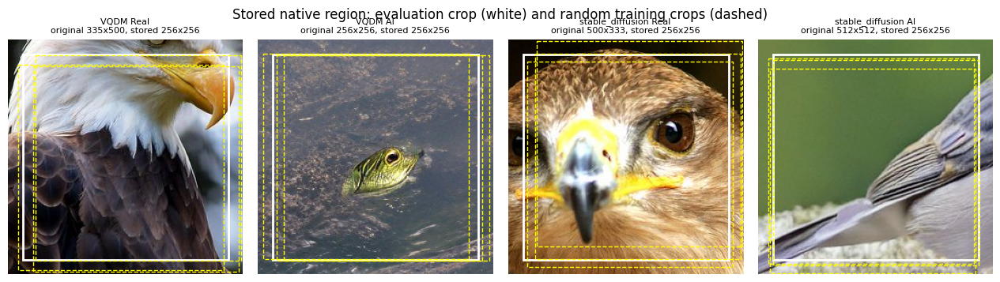

In [34]:
if NATIVE:
    random.seed(SEED)
    tr = DATASETS["train"]
    xs = [tr[i]["x"] for i in range(min(64, len(tr)))]
    differ = np.mean([not torch.equal(tr[i]["x"], tr[i]["x"]) for i in range(min(64, len(tr)))])
    print("1. train crops:", {tuple(x.shape) for x in xs}, f"values {min(float(x.min()) for x in xs):.2f}.."
          f"{max(float(x.max()) for x in xs):.2f} | two reads differ for {differ:.0%} of images")
    for s in ("val", "test_seen", "test_unseen"):
        d = DATASETS[s]
        det = all(torch.equal(d[i]["x"], d[i]["x"]) for i in range(len(d)))
        aligned = all(o % PCFG["align"] == 0 for i in range(len(d)) for o in d.crop_offset(i))
        print(f"2. {s:>11}: deterministic {'PASS' if det else 'FAIL'} | offsets multiple of {PCFG['align']} "
              f"{'PASS' if aligned else 'FAIL'}")
    m = {k: sum((CACHE_META[s][k] for s in vs_genimage.SPLITS), []) for k in ("enlarged", "decoded_same_size", "valid_h", "valid_w")}
    ok3 = not any(m["enlarged"]) and all(m["decoded_same_size"]) and min(m["valid_h"] + m["valid_w"]) >= crop
    print(f"3. no image enlarged, decoded at original size, stored region >= {crop} px: {'PASS' if ok3 else 'FAIL'}")

    import matplotlib.patches as patches
    t = SPLITS["train"].reset_index(drop=True)
    pick = [g.index[0] for _, g in t.groupby(["generator", "label"])]
    fig, axes = plt.subplots(1, len(pick), figsize=(3.2 * len(pick), 3.6), squeeze=False)
    arr = np.load(str(CACHE["train"]), mmap_mode="r")
    for ax, i in zip(axes[0], pick):
        vh, vw = CACHE_META["train"]["valid_h"][i], CACHE_META["train"]["valid_w"][i]
        ax.imshow(arr[i][:vh, :vw]); ax.axis("off")
        top, left = DATASETS["train_eval"].crop_offset(i)
        ax.add_patch(patches.Rectangle((left, top), crop, crop, fill=False, ec="white", lw=2))
        for _ in range(3):
            t0, l0 = DATASETS["train"].crop_offset(i)
            ax.add_patch(patches.Rectangle((l0, t0), crop, crop, fill=False, ec="yellow", lw=1, ls="--"))
        ax.set_title(f"{t.generator[i][:16]} {'AI' if t.label[i] else 'Real'}\n"
                     f"original {CACHE_META['train']['orig_w'][i]}x{CACHE_META['train']['orig_h'][i]}, stored {vw}x{vh}", fontsize=8)
    fig.suptitle("Stored native region: evaluation crop (white) and random training crops (dashed)")
    plt.tight_layout(); plt.show()
else:
    ref_cfg = Path(CONFIG["paths"]["experiments_dir"]) / REFERENCE_RUN / "hp_fft" / "config.yaml"
    if ref_cfg.exists():
        old = vs_common.load_yaml(ref_cfg)["preprocess"]
        keys = ["resize_short_side", "cache_size", "crop_size", "jpeg_quality_range", "train_hflip"]
        same = all(old.get(k) == PCFG.get(k) for k in keys) and not old.get("train_rescale_range")
        print(f"Control preprocessing identical to {REFERENCE_RUN}: {'PASS' if same else 'FAIL'}")
        print("  ", {k: (old.get(k), PCFG.get(k)) for k in keys})
    else:
        print(f"WARNING: {ref_cfg} not found; cannot compare with {REFERENCE_RUN}.")

In [35]:
# Bias-control evidence AFTER preprocessing
rows = []
for s in vs_genimage.SPLITS:
    df = SPLITS[s].assign(upscaled=CACHE_META[s]["upscaled"], jpeg_q=CACHE_META[s]["jpeg_quality"])
    for (g, lab), d in df.groupby(["generator", "label"]):
        rows.append({"split": s, "generator": g, "class": "ai" if lab else "real", "n": len(d),
                     "upscaled_%": round(100 * d["upscaled"].mean(), 1), "jpeg_q_mean": round(d["jpeg_q"].mean(), 1)})
BIAS = pd.DataFrame(rows)
print(BIAS.to_string(index=False))
if NATIVE:
    print("\nupscaled_% = share the OLD pipeline would have enlarged. Here NOTHING is resized (see 8b, check 3).")
else:
    print("\nupscaled_% = share enlarged by this (old) resize pipeline. It should be about 0 now that BigGAN is gone.")

      split              generator class   n  upscaled_%  jpeg_q_mean
      train                   VQDM  real 350         1.1         84.9
      train                   VQDM    ai 350         0.0         84.8
      train stable_diffusion_v_1_4  real 350         1.7         85.3
      train stable_diffusion_v_1_4    ai 350         0.0         85.2
        val                   VQDM  real  75         2.7         83.7
        val                   VQDM    ai  75         0.0         83.9
        val stable_diffusion_v_1_4  real  75         2.7         83.1
        val stable_diffusion_v_1_4    ai  75         0.0         84.6
  test_seen                   VQDM  real  75         1.3         85.3
  test_seen                   VQDM    ai  75         0.0         84.3
  test_seen stable_diffusion_v_1_4  real  75         1.3         86.2
  test_seen stable_diffusion_v_1_4    ai  75         0.0         85.3
test_unseen                    ADM  real 500         1.4         85.2
test_unseen         

**Expected output:**
- progress bars, then `Caches ready`
- `One training batch: (64, 3, 224, 224) ...` and the dataset sizes
- 8b: every line PASS (main run), or `Control preprocessing identical to m1_run_001: PASS` (control)
- the bias table: `jpeg_q_mean` about 85 for **both** classes

### 8c · JPEG verification, original files, and crop coverage
1. **Original files:** format, size and, for JPEGs, an estimate of the quality they were saved with (from the file's quantization table). Read from the headers only; used by the diagnostics in 17c.
2. **Equal JPEG preprocessing, verified:** reads back what the encoder actually did. **Main run:** for every image, from the cache build. **Control run:** for 25 images per generator and class, by repeating the pipeline's JPEG step and confirming it reproduces the cached pixels exactly.
   - every image 4:2:0
   - the same quality gives identical quantization tables for Real and AI
   - similar mean quality for both classes

   This proves the **code path** is identical. It cannot remove traces of the compression a real photo had **before** we got it; 17c measures whether those matter.
3. **Crop coverage:** the share of the original image a 224 crop covers.

> **Known limitation: crop coverage.** A 224×224 crop covers about 77% of a 256×256 ADM or VQDM image, about 19% of a 512×512 Stable Diffusion image, and roughly a quarter of a typical real photo. Objects therefore appear at different scales in different sources. This is a content-scale difference, not a pixel artefact, and it is **not** corrected here.

In [36]:
DATA_CHECKS = RUN_ROOT / "data_checks"; DATA_CHECKS.mkdir(exist_ok=True)
ORIG = {s: vs_native.original_info(SPLITS[s], workers=CONFIG["data"]["hash_workers"]) for s in vs_genimage.SPLITS}
for s, o in ORIG.items():
    o.to_csv(DATA_CHECKS / f"original_info_{s}.csv", index=False)

if NATIVE:
    AUDIT = pd.concat([SPLITS[s][["image_id", "generator", "label"]].assign(
        split=s, **{k: CACHE_META[s][k] for k in ("jpeg_quality", "jpeg_sampling", "qtable_hash")})
        for s in vs_genimage.SPLITS], ignore_index=True)
else:
    pool = pd.concat([SPLITS[s].assign(split=s) for s in vs_genimage.SPLITS], ignore_index=True)
    sample = pool.sample(frac=1, random_state=SEED).groupby(["generator", "label"]).head(25)   # 25 per generator and class
    AUDIT = sample[["image_id", "generator", "label", "split", "image_path"]].merge(
        vs_native.audit_resize_jpeg(sample, PCFG, SEED), on="image_id")
JPEG_CHECKS = vs_native.jpeg_checks(AUDIT)
print(f"JPEG verification ({len(AUDIT)} images):")
print(JPEG_CHECKS.to_string(index=False))
AUDIT.drop(columns=["image_path"], errors="ignore").to_csv(DATA_CHECKS / "jpeg_audit.csv", index=False)
JPEG_CHECKS.to_csv(DATA_CHECKS / "jpeg_checks.csv", index=False)

allo = pd.concat([SPLITS[s][["image_id", "generator", "label"]].merge(ORIG[s], on="image_id") for s in vs_genimage.SPLITS])
allo["class"] = allo["label"].map({0: "real", 1: "ai"})
allo["crop_coverage_%"] = 100 * crop * crop / (allo["orig_w"] * allo["orig_h"])
COVERAGE = (allo.groupby(["generator", "class"])
            .agg(n=("image_id", "size"), median_w=("orig_w", "median"), median_h=("orig_h", "median"),
                 formats=("orig_format", lambda s: dict(s.value_counts())),
                 median_coverage_pct=("crop_coverage_%", "median"),
                 min_coverage_pct=("crop_coverage_%", "min"), max_coverage_pct=("crop_coverage_%", "max"))
            .round(1).reset_index())
print(f"\nShare of the ORIGINAL image covered by one {crop}x{crop} crop:")
print(COVERAGE.to_string(index=False))
COVERAGE.to_csv(DATA_CHECKS / "crop_coverage.csv", index=False)
print("\nKNOWN LIMITATION: crop coverage differs by source (see the table). Objects appear at different scales; "
      "this is not corrected in this experiment.")

Reading original headers:   0%|          | 0/1400 [00:00<?, ?it/s]

Reading original headers:   0%|          | 0/300 [00:00<?, ?it/s]

Reading original headers:   0%|          | 0/300 [00:00<?, ?it/s]

Reading original headers:   0%|          | 0/1000 [00:00<?, ?it/s]

JPEG verification (3000 images):
                                                        check result                                        detail
            Every image encoded with 4:2:0 chroma subsampling   PASS                Real: ['4:2:0'], AI: ['4:2:0']
Same quality -> identical quantization tables for Real and AI   PASS        0 quality values with differing tables
                        Quality values shared by both classes   PASS 21 of 21 quality values occur in both classes
         Mean JPEG quality similar for Real and AI (within 3)   PASS                            Real 85.0, AI 84.9

Share of the ORIGINAL image covered by one 224x224 crop:
             generator class   n  median_w  median_h       formats  median_coverage_pct  min_coverage_pct  max_coverage_pct
                   ADM    ai 500     256.0     256.0  {'PNG': 500}                 76.6              76.6              76.6
                   ADM  real 500     500.0     375.0 {'JPEG': 500}                 26.

## 9 · Data visualisation
**Purpose:** check with your own eyes:
1. that labels look right
2. what preprocessing does: before (original file) versus after (224×224, JPEG re-encoded)
3. what a training batch looks like after augmentation

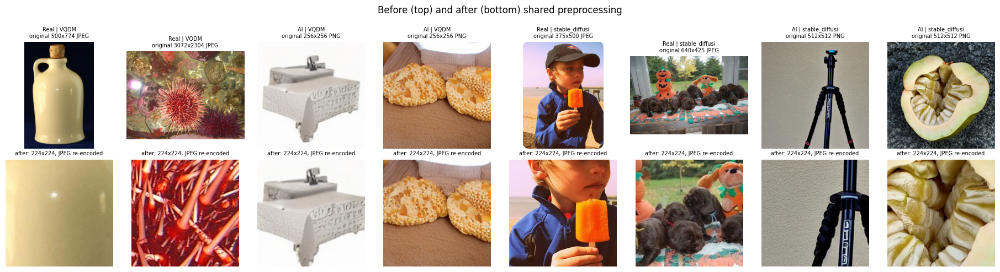

In [37]:
RUN_ROOT = vs_common.make_run_dir(Path(CONFIG["paths"]["experiments_dir"]) / RUN_NAME, resume=True)
DATA_PLOTS = RUN_ROOT / "data_plots"
DATA_PLOTS.mkdir(exist_ok=True)

tr = SPLITS["train"].reset_index().rename(columns={"index": "cache_index"})
pick = pd.concat([g.sample(min(2, len(g)), random_state=SEED) for _, g in tr.groupby(["generator", "label"])])
vs_plots.plot_before_after(pick.head(8), CACHE["train"], DATA_PLOTS / "before_after_preprocessing.png")

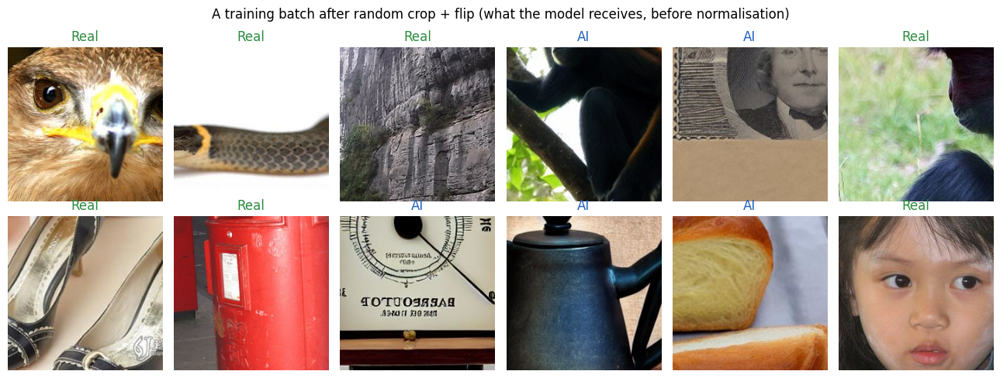

In [38]:
b = next(iter(LOADERS["train"]))
n = min(12, len(b["x"]))
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax, i in zip(axes.flat, range(n)):
    ax.imshow(b["x"][i].permute(1, 2, 0).numpy())
    ax.set_title("AI" if b["label"][i] == 1 else "Real", color="#1f5fbf" if b["label"][i] == 1 else "#2b8a3e")
    ax.axis("off")
fig.suptitle("A training batch after random crop + flip (what the model receives, before normalisation)")
plt.tight_layout(); plt.savefig(DATA_PLOTS / "training_batch.png", dpi=110); plt.show()

**Expected output:** two image grids, saved under `experiments/<RUN_NAME>/data_plots/`.

**Check:** do images labelled **AI** look generated, and images labelled **Real** look like photos? If not, a folder rule is wrong. Fix it in Section 5 and rebuild the split with a new `N_PER_CLASS` or `SEED`.

## 10 · RGB baseline
**Purpose:** a standard ResNet-50 that looks at ordinary colour images. It is trained on the **same split, preprocessing and settings** as M1, so any difference comes from the *input features*. ⬜ addition: a controlled comparison.

```
x (0..1) → ImageNet normalisation → ResNet-50 (ImageNet weights, unchanged first layer)
         → 2048-d feature → Dropout → Linear(2048 → 1) → logit → sigmoid → P(AI)
```

The **same class** (`ResNetDetector`) builds both models. Only `input_mode` changes: `"rgb"` here, `"hp_fft"` for M1.

In [39]:
vs_common.show_source(vs_models.ResNetDetector.forward)
rgb_model = vs_models.build_detector("rgb", CONFIG).to(DEVICE)
print("first layer:", rgb_model.backbone.conv1)
print("head:", rgb_model.head)
print(f"parameters: {vs_models.count_parameters(rgb_model):,}")
with torch.no_grad():
    out = rgb_model.eval()(batch["x"][:4].to(DEVICE))
print({k: tuple(v.shape) for k, v in out.items()})
del rgb_model

    def forward(self, x01: torch.Tensor, threshold: float = 0.5) -> dict:
        z = self.features_in(x01)                             # [B, C, H, W] model input
        feats = self.backbone(z)                              # [B, 2048]
        logits = self.head(feats).squeeze(1).float()          # [B]
        prob = torch.sigmoid(logits)
        return {"logits": logits, "prob": prob, "pred": (prob >= threshold).long(), "features": feats.float()}

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 198MB/s]


first layer: Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
head: Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=2048, out_features=1, bias=True)
)
parameters: 23,510,081
{'logits': (4,), 'prob': (4,), 'pred': (4,), 'features': (4, 2048)}


**Expected output:** the `forward` code, then `first layer: Conv2d(3, 64, kernel_size=(7, 7), ...)`, the head, about **23.5 million parameters**, and the output shapes `{'logits': (4,), 'prob': (4,), 'pred': (4,), 'features': (4, 2048)}`. (The ImageNet weights download, about 100 MB, the first time.)

## 11 · High-pass feature extraction
**How it is made:** `residual = image − GaussianBlur(image)`, using a 5×5 kernel with σ = 1, separately for each colour channel.

```
image ──► blur (keeps smooth shapes and colours) ──┐
  │                                                ▼
  └──────────────────────────────────────────► subtract ──► residual: edges, fine texture, noise
```

**Why it helps:** the residual removes most of the *picture content* and keeps fine detail and noise, where generators leave fingerprints. Residual values are tiny (about ±0.05), so M1 divides them by their typical size, `hp_std`, measured on **training images only**.

def high_pass(x01: torch.Tensor, kernel: torch.Tensor) -> torch.Tensor:
    """Residual = image - blurred image. x01: [B, 3, H, W] in 0..1; kernel: [3, 1, k, k].

    Blurring keeps only slow, smooth changes (shapes, colours). Subtracting the blur leaves the
    fast changes: edges, fine texture, sensor noise and generator artefacts.
    """
    pad = kernel.shape[-1] // 2
    blurred = F.conv2d(F.pad(x01, (pad, pad, pad, pad), mode="reflect"), kernel, groups=3)
    return x01 - blurred



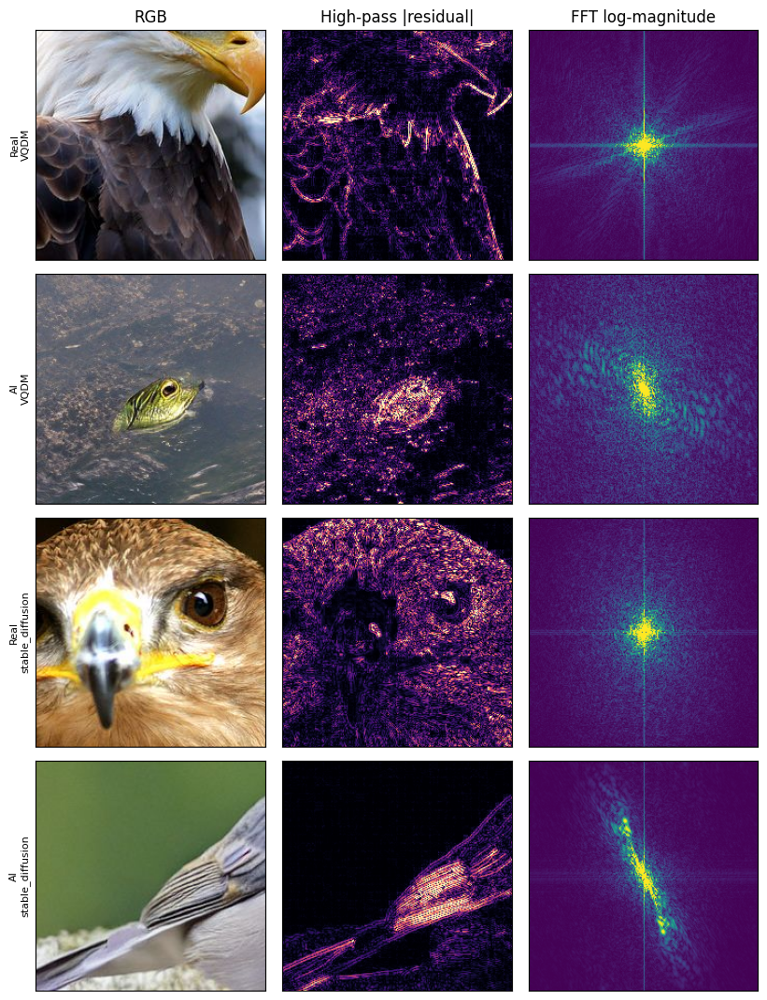

In [40]:
vs_common.show_source(vs_features.high_pass)
fb_vis = vs_features.FeatureBuilder("rgb_hp_fft", CONFIG["features"]["hp_kernel"], CONFIG["features"]["hp_sigma"])
vis = pd.concat([g.head(1) for _, g in tr.groupby(["generator", "label"])]).head(6)
xs = torch.stack([DATASETS["train_eval"][int(i)]["x"] for i in vis["cache_index"]])
vs_plots.plot_representations(xs, vis["label"].tolist(), vis["generator"].tolist(), fb_vis,
                              DATA_PLOTS / "rgb_highpass_fft.png")

**Expected output:** the `high_pass` code, then a grid with one row per (generator, class) and three columns: **RGB**, **high-pass |residual|** (bright = strong fine detail) and **FFT log-magnitude**.

Don't expect differences you can see by eye. The model looks for statistical patterns across thousands of images.

## 12 · FFT feature extraction
**How it is made:**

```
image → grey → 2D FFT (image as a sum of waves) → |·| (strength of each wave)
      → fftshift (slow waves to the centre) → log(1 + ·) (squeeze the huge range) → 1 channel, 224×224
```

**Why it helps:** natural photos have energy that fades smoothly from the centre. Upsampling layers in many generators leave **periodic** patterns, which show up as bright **off-centre dots or lines**. The average spectrum over many images makes these easier to see than any single image.

The FFT is computed in float32 even under mixed precision, because half-precision FFTs are unreliable at size 224. Values are standardised with a mean and std measured on training images only.

def fft_log_magnitude(x01: torch.Tensor) -> torch.Tensor:
    """[B, 3, H, W] -> [B, 1, H, W]: centred log-magnitude spectrum of the grey image.

    fft2 rewrites the image as a sum of waves; |.| is how strong each wave is; fftshift moves the
    slow (low-frequency) waves to the centre; log1p squeezes the huge range of values.
    Periodic generator artefacts appear as bright off-centre dots.
    """
    gray = (0.299 * x01[:, 0] + 0.587 * x01[:, 1] + 0.114 * x01[:, 2]).unsqueeze(1).float()
    spec = torch.fft.fftshift(torch.fft.fft2(gray, norm="ortho"), dim=(-2, -1))
    return torch.log1p(spec.abs())



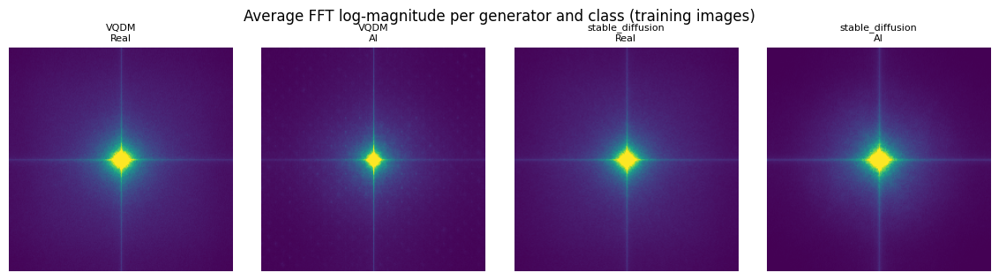

In [41]:
vs_common.show_source(vs_features.fft_log_magnitude)
spectra = {}
for (g, lab), d in tr.groupby(["generator", "label"]):
    idx = d["cache_index"].head(64).tolist()
    x = torch.stack([DATASETS["train_eval"][int(i)]["x"] for i in idx])
    spectra[(g, lab)] = vs_features.fft_log_magnitude(x).mean(0)[0].numpy()
vs_plots.plot_mean_spectra(spectra, DATA_PLOTS / "mean_fft_spectra.png")

**Expected output:** the `fft_log_magnitude` code, then one average spectrum per (generator, class) from up to 64 training images each.

**What to look for:** bright dots or grid lines in the **AI** panels that are absent from the **Real** ones. Their presence or absence is an observation for the report, not a result.

The bright **centre** and the thin **cross** through it appear in *every* panel. The centre is the image's average brightness and smooth shading. The cross comes from the image edges, which don't wrap around. Neither one is a generator artefact.

## 13 · M1 model (proposal: high-pass + FFT ResNet-50)
**Input:** 3 high-pass channels + 1 FFT channel = **4 channels**. ImageNet ResNet-50 expects 3, so the **first convolution is replaced**:
- the high-pass channels **copy** the pretrained RGB filters (they still respond to edges and texture)
- the FFT channel uses their **average**
- the weights are scaled by 3/4 so activations start at a familiar size

Everything after the first layer keeps its ImageNet weights. The 1000-class head is replaced by `Dropout → Linear(2048 → 1)`.

```
x (0..1) ─┬─ high-pass ÷ hp_std ─────────────┐
          └─ FFT log-mag, standardised ───────┴─► 4-channel input ─► new conv1 ─► ResNet-50 body
             ─► 2048-d FEATURE (kept for Fusion) ─► Dropout ─► Linear ─► logit ─► P(AI) ─► label (≥ 0.5 = AI)
```

The **forward method returns** `logits`, `prob` (P(AI)), `pred` (0 = Real, 1 = AI) and `features` (2048-d). That is the interface the future Fusion model will use.

In [42]:
vs_common.show_source(vs_models.adapt_conv1)
m1 = vs_models.build_detector("hp_fft", CONFIG).to(DEVICE)
print("first layer:", m1.backbone.conv1)
stats = m1.features_in.fit_stats(LOADERS["train"], DEVICE, max_batches=5)
print("feature scale statistics (from training images):", {k: round(v, 5) for k, v in stats.items()})
with torch.no_grad():
    z = m1.features_in(batch["x"][:4].to(DEVICE))
    out = m1.eval()(batch["x"][:4].to(DEVICE))
print("model input:", tuple(z.shape), f"mean {z.mean():.2f} std {z.std():.2f}")
print({k: tuple(v.shape) for k, v in out.items()}, "| P(AI) before training:", out["prob"].cpu().numpy().round(3))
del m1

def adapt_conv1(old: nn.Conv2d, parts) -> nn.Conv2d:
    """New first layer for 4 or 7 input channels that still starts from ImageNet knowledge.

    rgb and hp channels copy the pretrained RGB filters; the fft channel uses their average.
    Weights are scaled by 3 / channels so the layer's output starts at a similar size.
    """
    w = old.weight.detach()                                    # [64, 3, 7, 7]
    blocks = [w.clone() if p in ("rgb", "hp") else w.mean(dim=1, keepdim=True) for p in parts]
    new_w = torch.cat(blocks, dim=1)
    new_w = new_w * (3.0 / new_w.shape[1])
    conv = nn.Conv2d(new_w.shape[1], old.out_channels, kernel_size=old.kernel_size,
                     stride=old.stride, padding=old.padding, bias=False)
    with torch.no_grad():
        conv.weight.copy_(new_w)
    return conv

first layer: Conv2d(4, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
feature scale statistics (from training images): {'hp_std': 0.05176, 'fft_mean': 0.05785,

**Expected output:**
- `first layer: Conv2d(4, 64, kernel_size=(7, 7), ...)`
- the fitted `hp_std`, `fft_mean` and `fft_std`
- `model input: (4, 4, 224, 224)`, with mean near 0 and std near 1
- output shapes `(4,) (4,) (4,) (4, 2048)`
- P(AI) values near 0.5, because the model is untrained

## 14 · Sanity checks (must pass before training)
These cheap checks catch most beginner bugs before you spend A100 hours.

| Check | What it does | Pass if | If it fails |
|---|---|---|---|
| **Smoke test** | 2 training steps + 1 validation batch for each model | runs, outputs have the right shapes, no NaN | shape or device bug |
| **Overfit 32 images** | train repeatedly on 32 images (no augmentation) | accuracy on those 32 ≥ 0.9 | the model cannot learn even when it should: a label, input or optimiser bug |
| **Random labels (mirrored pair)** | model A trains on random labels that carry *zero* information about the true class; model B trains on the exact mirror labels (every 0↔1). Both start identically, with the last layer set to zero. Then score both on the real validation labels | the **average** of the two validation AUROCs is 0.5 ± 0.10 | the model is learning the true label from somewhere other than the labels we give it: a bug in the label path |

All three use the hp_fft M1 model. The smoke test covers both models.

**Why a mirrored pair?** When the classes are easy to separate, a *single* random-label model can land near AUROC 0 or 1 just because of its random starting weights, even with no leakage. With a zero last layer and identical randomness, model B is an exact mirror of model A whenever the pipeline learns only from the labels it is given. So AUROC_B = 1 − AUROC_A and the average is 0.5. Individual A and B values far from 0.5 are therefore normal; only the **average** matters.

This test checks the **label path**. Duplicate images across splits are checked separately, in Section 7.

In [43]:
SANITY = {}
make = lambda mode: (lambda: vs_models.build_detector(mode, CONFIG))
for mode in CONFIG["runs"]["modes"]:
    vs_common.set_seed(SEED)
    model = make(mode)().to(DEVICE)
    model.features_in.fit_stats(LOADERS["train"], DEVICE, max_batches=2)
    opt = torch.optim.AdamW(model.param_groups(1e-4, 1e-3, 1e-4))
    t0 = time.time()
    tr_out = vs_train.train_one_epoch(model, LOADERS["train"], opt, None, vs_train.make_scaler(AMP), DEVICE, AMP, max_batches=2)
    pv, vloss = vs_train.predict(model, LOADERS["val"], DEVICE, AMP, max_batches=1)
    with torch.no_grad():
        o = model.eval()(batch["x"][:2].to(DEVICE))
    ok = (o["logits"].shape == (2,) and o["features"].shape == (2, 2048)
          and math.isfinite(tr_out["loss"]) and math.isfinite(vloss))
    SANITY[f"smoke_{mode}"] = ok
    print(f"[smoke {mode:>6}] {'PASS' if ok else 'FAIL'}  train_loss {tr_out['loss']:.3f}  val_loss {vloss:.3f}  "
          f"{(time.time() - t0) / 3:.2f}s per batch")
    del model, opt

[smoke    rgb] PASS  train_loss 0.691  val_loss 0.681  0.42s per batch
[smoke hp_fft] PASS  train_loss 0.682  val_loss 0.683  0.15s per batch


In [44]:
vs_common.set_seed(SEED)
n32 = min(CONFIG["sanity"]["overfit_images"], len(DATASETS["train_eval"]))
rng = np.random.default_rng(SEED)
idx32 = sorted(rng.choice(len(DATASETS["train_eval"]), size=n32, replace=False).tolist())
steps = CONFIG["sanity"]["overfit_steps_gpu"] if DEVICE.type == "cuda" else CONFIG["sanity"]["overfit_steps_cpu"]
res = vs_train.overfit_test(make("hp_fft"), torch.utils.data.Subset(DATASETS["train_eval"], idx32), DEVICE, AMP,
                            steps=steps, batch_size=min(16, n32), seed=SEED)
SANITY["overfit_32"] = res["passed"]
print(f"[overfit {n32} images] {'PASS' if res['passed'] else 'FAIL'}  accuracy {res['accuracy']:.3f}  loss {res['final_loss']:.3f}  ({steps} steps)")

[overfit 32 images] PASS  accuracy 1.000  loss 0.000  (80 steps)


In [45]:
vs_common.set_seed(SEED)
res = vs_train.shuffled_label_test(make("hp_fft"), DATASETS["train"], LOADERS["val"], CONFIG, DEVICE, AMP, SEED)
SANITY["shuffled_labels"] = res["passed"]
lo, hi = res["band"]
print(f"[shuffled labels] {'PASS' if res['passed'] else 'FAIL'}  mean val AUROC {res['mean_auroc']:.3f} "
      f"(pass band {lo:.2f}-{hi:.2f})  | model A {res['auroc_A']:.3f}, mirror model B {res['auroc_B_mirror']:.3f}"
      f"  | {res['train_images']} images, {res['epochs']} epochs each")
print("\nSanity summary:", SANITY)
SANITY_PASSED = all(SANITY.values())
print("ALL SANITY CHECKS PASSED" if SANITY_PASSED else "SOME CHECKS FAILED: do not train until they pass.")

[shuffled labels] PASS  mean val AUROC 0.500 (pass band 0.40-0.60)  | model A 0.459, mirror model B 0.541  | 512 images, 2 epochs each

Sanity summary: {'smoke_rgb': True, 'smoke_hp_fft': True, 'overfit_32': True, 'shuffled_labels': True}
ALL SANITY CHECKS PASSED


**Expected output:**
- `[smoke rgb] PASS` and `[smoke hp_fft] PASS`, with time per batch
- `[overfit 32 images] PASS  accuracy 1.000` or close to it
- `[shuffled labels] PASS  mean val AUROC ≈ 0.5 (pass band ...) | model A ..., mirror model B ...`
- `ALL SANITY CHECKS PASSED`

Model A and B can each be far from 0.5. Only their mean is tested. If the overfit check fails on CPU, it may simply need more steps; on the A100 it should pass.

## 15 · Training
**Purpose:** train the **RGB baseline** and **M1** one after the other, with identical settings:
- **Loss:** `BCEWithLogitsLoss`, the standard loss for one yes/no output. It combines the sigmoid and the log-loss in one numerically stable step.
- **Optimiser:** AdamW. Pretrained layers use lr 1e-4; the new layers (head, adapted conv1) use lr 1e-3. Weight decay 1e-4.
- **Learning rate:** 1 warm-up epoch, then a cosine decay.
- **Mixed precision:** on CUDA (bfloat16 on the A100).
- **After every epoch:** validation loss, accuracy and AUROC, all on **seen** generators only.
- **`best.pt`:** saved whenever validation AUROC improves.
- **`last.pt`:** saved every epoch, so you can resume after a disconnect.
- **Early stopping:** after 3 epochs without improvement.

The test sets are **not used here at all**.

Each model gets its own folder, `experiments/<RUN_NAME>/<mode>/`.

In [46]:
assert "SANITY_PASSED" in dir() and SANITY_PASSED, "Run Section 14 first; all sanity checks must pass before training."
if DEVICE.type != "cuda":
    print("CPU detected: limiting training to a tiny smoke run (2 epochs x 3 batches). Use the A100 for real training.")
    CONFIG["train"].update(epochs=min(2, CONFIG["train"]["epochs"]), max_train_batches=3, max_val_batches=3)

RUN_DIRS, HISTORIES = {}, {}
for mode in CONFIG["runs"]["modes"]:
    print(f"\n{'=' * 22} training: {mode} {'(RGB baseline)' if mode == 'rgb' else '(M1)'} {'=' * 22}")
    run_dir = vs_common.make_run_dir(RUN_ROOT / mode, resume=RESUME)
    run_cfg = {**CONFIG, "model": {**CONFIG["model"], "input_mode": mode},
               "environment": ENV, "split_fingerprints": SPLIT_INFO["fingerprints"]}
    vs_common.save_yaml(run_cfg, run_dir / "config.yaml")
    vs_common.set_seed(SEED)
    model = vs_models.build_detector(mode, CONFIG).to(DEVICE)
    t0 = time.time()
    stats_loader = LOADERS["train_eval"] if PCFG.get("train_rescale_range") else None   # un-augmented train images
    HISTORIES[mode] = vs_train.fit(model, LOADERS["train"], LOADERS["val"], run_cfg, run_dir, DEVICE, AMP, resume=RESUME,
                                   stats_loader=stats_loader)
    RUN_DIRS[mode] = run_dir
    print(f"{mode}: finished in {(time.time() - t0) / 60:.1f} min -> {run_dir}")
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


====================== training: rgb (RGB baseline) ======================
epoch  1/10  train_loss 0.6798  train_acc 0.551  val_loss 0.6183  val_acc 0.717  val_auroc 0.7914  * best  (1s)
epoch  2/10  train_loss 0.5029  train_acc 0.803  val_loss 0.4324  val_acc 0.803  val_auroc 0.9059  * best  (2s)
epoch  3/10  train_loss 0.2555  train_acc 0.929  val_loss 0.3097  val_acc 0.873  val_auroc 0.9458  * best  (1s)
epoch  4/10  train_loss 0.0985  train_acc 0.986  val_loss 0.2679  val_acc 0.900  val_auroc 0.9580  * best  (1s)
epoch  5/10  train_loss 0.0504  train_acc 0.996  val_loss 0.2675  val_acc 0.900  val_auroc 0.9572  (1s)
epoch  6/10  train_loss 0.0245  train_acc 0.999  val_loss 0.2623  val_acc 0.890  val_auroc 0.9583  * best  (1s)
epoch  7/10  train_loss 0.0197  train_acc 0.999  val_loss 0.2622  val_acc 0.903  val_auroc 0.9613  * best  (1s)
epoch  8/10  train_loss 0.0156  train_acc 1.000  val_loss 0.2390  val_acc 0.910  val_auroc 0.9662  * best  (1s)
epoch  9/10  train_loss 0.0127  trai

**Expected output:** for each model, the feature statistics (M1 only), then one line per epoch:

`epoch  1/10  train_loss 0.6xx  train_acc 0.6xx  val_loss ...  val_acc ...  val_auroc ...  * best  (NNs)`

**How to read it while it trains:**
- `train_loss` should go **down**.
- `val_auroc` should go **up**, then level off.
- `train_loss` still falling while `val_loss` rises is **overfitting**. Early stopping and `best.pt` protect you from it.

## 16 · Validation
**Purpose:** reload the **frozen best checkpoint** (highest validation AUROC) of each model and score the validation set again. This confirms the saved file reproduces the number seen during training, and saves `predictions_val.csv`.

From here on, models are **frozen**: nothing is trained or tuned.

In [47]:
RUN_DIRS = {m: RUN_ROOT / m for m in CONFIG["runs"]["modes"]}

def load_best(mode):
    ck = vs_common.load_checkpoint(RUN_DIRS[mode] / "best.pt", DEVICE)
    model = vs_models.build_detector(mode, CONFIG).to(DEVICE)
    model.load_state_dict(ck["model"])
    model.eval()
    return model, ck

def evaluate_split(mode, split):
    model, ck = load_best(mode)
    pv, loss = vs_train.predict(model, LOADERS[split], DEVICE, AMP)
    preds = vs_train.predictions_with_meta(pv, SPLITS[split], split, f"{RUN_NAME}/{mode}")
    preds.to_csv(RUN_DIRS[mode] / f"predictions_{split}.csv", index=False)
    del model
    return preds, loss, ck

PREDS = {m: {} for m in CONFIG["runs"]["modes"]}
for mode in CONFIG["runs"]["modes"]:
    preds, loss, ck = evaluate_split(mode, "val")
    PREDS[mode]["val"] = preds
    m = vs_metrics.classification_metrics(preds["label"], preds["p_ai"])
    print(f"{mode:>7}: best epoch {ck['epoch']}  val AUROC {m['auroc']:.4f} (during training: {ck['val_metrics']['auroc']:.4f})  "
          f"val acc {m['accuracy']:.4f}  loss {loss:.4f}")

    rgb: best epoch 8  val AUROC 0.9662 (during training: 0.9662)  val acc 0.9100  loss 0.2390
 hp_fft: best epoch 9  val AUROC 0.9296 (during training: 0.9296)  val acc 0.8333  loss 0.4225


**Expected output:** one line per model. The reloaded val AUROC should equal the training-time value to about 3 decimals; tiny GPU rounding differences are fine.

## 17 · Seen-generator testing (in-distribution)
**Purpose:** score `test_seen`: images from the **same generators** the model trained on, but never seen during training. This is the "familiar generators" number. Comparing it with Section 18 measures generalisation.

In [48]:
for mode in CONFIG["runs"]["modes"]:
    preds, loss, _ = evaluate_split(mode, "test_seen")
    PREDS[mode]["test_seen"] = preds
    m = vs_metrics.classification_metrics(preds["label"], preds["p_ai"])
    print(f"{mode:>7}: test_seen  n={m['n']}  acc {m['accuracy']:.4f}  AUROC {m['auroc']:.4f}")
    print(vs_metrics.metrics_by_generator(preds).round(4).to_string(index=False), "\n")

    rgb: test_seen  n=300  acc 0.8400  AUROC 0.9277
          ai_generator  n_ai  n_real  accuracy  auroc  ai_detection_rate  real_accuracy
                  VQDM    75     150    0.8311 0.9112             0.8133           0.84
stable_diffusion_v_1_4    75     150    0.8489 0.9442             0.8667           0.84 

 hp_fft: test_seen  n=300  acc 0.8433  AUROC 0.9188
          ai_generator  n_ai  n_real  accuracy  auroc  ai_detection_rate  real_accuracy
                  VQDM    75     150    0.8089 0.8972             0.8533         0.7867
stable_diffusion_v_1_4    75     150    0.8400 0.9403             0.9467         0.7867 



**Expected output:** overall accuracy and AUROC per model, plus a per-generator table (each seen AI generator against all real test images).

### 17b · Shortcut diagnostic: does resizing history drive the score? (seen data only)
GenImage AI images have fixed sizes (for example BigGAN 128², ADM 256², SD 512²); real photos vary. Resizing everything to 256 therefore leaves **different resampling traces per class**. This cell asks whether real photos that had to be **upscaled** get a higher P(AI) than other real photos. It uses only val and test_seen, never test_unseen.

**How to read it:** if upscaled real photos score clearly higher than non-upscaled ones, the model is using resize history as a shortcut.

In [49]:
# Do Real photos that were UPSCALED in preprocessing look "more AI" to the models? (val + test_seen only)
SHORTCUT_DIAG = {}
for mode in PREDS:
    p = pd.concat([PREDS[mode][s].assign(upscaled=np.asarray(CACHE_META[s]["upscaled"], dtype=bool)[PREDS[mode][s]["cache_index"]])
                   for s in ("val", "test_seen")])
    r = p[p["label"] == 0]                                     # Real images only
    print(f"{mode:>6}: Real upscaled     n={int(r.upscaled.sum()):>3}  mean P(AI) {r[r.upscaled].p_ai.mean():.2f}")
    print(f"{'':>6}  Real not upscaled n={int((~r.upscaled).sum()):>3}  mean P(AI) {r[~r.upscaled].p_ai.mean():.2f}")
    for g, d in p[p["label"] == 1].groupby("generator"):      # AI images per generator
        print(f"{'':>6}  AI {g:<7} n={len(d):>3}  mean P(AI) {d.p_ai.mean():.2f}")
    SHORTCUT_DIAG[mode] = {"real_upscaled_mean_p_ai": float(r[r.upscaled].p_ai.mean()), "real_upscaled_n": int(r.upscaled.sum()),
                           "real_not_upscaled_mean_p_ai": float(r[~r.upscaled].p_ai.mean()),
                           "ai_mean_p_ai": {g: float(d.p_ai.mean()) for g, d in p[p["label"] == 1].groupby("generator")}}
    vs_common.save_json(SHORTCUT_DIAG[mode], RUN_DIRS[mode] / "shortcut_diagnostic.json")

   rgb: Real upscaled     n=  6  mean P(AI) 0.41
        Real not upscaled n=294  mean P(AI) 0.15
        AI VQDM    n=150  mean P(AI) 0.83
        AI stable_diffusion_v_1_4 n=150  mean P(AI) 0.86
hp_fft: Real upscaled     n=  6  mean P(AI) 0.65
        Real not upscaled n=294  mean P(AI) 0.25
        AI VQDM    n=150  mean P(AI) 0.85
        AI stable_diffusion_v_1_4 n=150  mean P(AI) 0.92


### 17c · More shortcut diagnostics (seen data only: val + test_seen)
For each model:
1. **By original file format:** mean P(AI) and accuracy per generator, class and original format (PNG / JPEG).
2. **Original JPEG quality of real photos:** do real photos that were saved at a **lower** quality before we got them look more or less "AI"? A clear dependence (|Spearman ρ| ≥ 0.2 with p < 0.05) means the model still reads old compression traces: the format shortcut has not fully gone.
3. **Per generator and class:** AI detection rate (AI rows) and real-image accuracy (Real rows).

17b above also applies here: in the main run, "upscaled" means *would have been* enlarged by the old pipeline, since nothing is resized now.

Never computed on `test_unseen`.

In [50]:
from scipy.stats import spearmanr
EXT_DIAG = {}
for mode in PREDS:
    p = pd.concat([PREDS[mode][s].assign(upscaled=np.asarray(CACHE_META[s]["upscaled"], dtype=bool)[PREDS[mode][s]["cache_index"]])
                   .merge(ORIG[s], on="image_id", how="left") for s in ("val", "test_seen")], ignore_index=True)
    p["class"] = p["label"].map({0: "Real", 1: "AI"})
    by_fmt = (p.groupby(["generator", "class", "orig_format"])
              .agg(n=("p_ai", "size"), mean_p_ai=("p_ai", "mean"), accuracy=("correct", "mean")).round(3).reset_index())
    real = p[(p["label"] == 0) & p["orig_jpeg_quality"].notna()]
    rho, pval = spearmanr(real["orig_jpeg_quality"], real["p_ai"]) if len(real) > 2 else (float("nan"), float("nan"))
    by_q = (real.groupby(pd.cut(real["orig_jpeg_quality"], [0, 75, 85, 92, 100]), observed=False)
            .agg(n=("p_ai", "size"), mean_p_ai=("p_ai", "mean")).round(3).reset_index())
    by_q["orig_jpeg_quality"] = by_q["orig_jpeg_quality"].astype(str)
    by_gc = (p.groupby(["generator", "class"])
             .agg(n=("p_ai", "size"), mean_p_ai=("p_ai", "mean"), rate_correct=("correct", "mean")).round(3).reset_index())
    print(f"\n==================== {mode} ====================")
    print("1. By original format:\n" + by_fmt.to_string(index=False))
    print(f"\n2. Real photos, original JPEG quality vs P(AI): Spearman rho {rho:.3f} (p = {pval:.3g}, n = {len(real)})")
    print(by_q.to_string(index=False))
    flag = abs(rho) >= 0.2 and pval < 0.05
    print("   ->", "P(AI) DEPENDS on the original JPEG quality: a format shortcut may remain." if flag
          else "no clear dependence detected at this sample size.")
    print("\n3. Per generator and class (rate_correct = AI detection rate for AI, real accuracy for Real):")
    print(by_gc.to_string(index=False))
    out = RUN_DIRS[mode] / "diagnostics"; out.mkdir(exist_ok=True)
    by_fmt.to_csv(out / "by_original_format.csv", index=False)
    by_q.to_csv(out / "real_by_original_jpeg_quality.csv", index=False)
    by_gc.to_csv(out / "by_generator_class.csv", index=False)
    EXT_DIAG[mode] = {"spearman_rho_real_origq_vs_pai": float(rho), "p_value": float(pval), "n_real_jpeg": int(len(real)),
                      "format_shortcut_flag": bool(flag)}
    vs_common.save_json(EXT_DIAG[mode], out / "extended_diagnostic.json")


==================== rgb ====================
1. By original format:
             generator class orig_format   n  mean_p_ai  accuracy
                  VQDM    AI         PNG 150      0.830     0.873
                  VQDM  Real        JPEG 150      0.133     0.907
stable_diffusion_v_1_4    AI         PNG 150      0.863     0.873
stable_diffusion_v_1_4  Real        JPEG 150      0.179     0.847

2. Real photos, original JPEG quality vs P(AI): Spearman rho -0.040 (p = 0.495, n = 300)
orig_jpeg_quality   n  mean_p_ai
          (0, 75]  21      0.208
         (75, 85]   9      0.151
         (85, 92]  14      0.284
        (92, 100] 256      0.145
   -> no clear dependence detected at this sample size.

3. Per generator and class (rate_correct = AI detection rate for AI, real accuracy for Real):
             generator class   n  mean_p_ai  rate_correct
                  VQDM    AI 150      0.830         0.873
                  VQDM  Real 150      0.133         0.907
stable_diffusion_v_1

## 18 · Unseen-generator testing
**Purpose:** score `test_unseen`, the images of this fold's unseen generator, never used for training or validation.

> **The preprocessing was frozen before fold 1. This run only reports the unseen results; no model or preprocessing decision is made from them.**

Every evaluation is logged with a timestamp in `unseen_test_log.json`.

In [51]:
for mode in CONFIG["runs"]["modes"]:
    log_path = RUN_DIRS[mode] / "unseen_test_log.json"
    log = vs_common.load_json(log_path) if log_path.exists() else []
    if log:
        print(f"NOTE ({mode}): the unseen test was already run {len(log)} time(s), first at {log[0]['time']}. "
              "Re-running the same frozen checkpoint gives the same numbers. Do not tune on them.")
    preds, loss, ck = evaluate_split(mode, "test_unseen")
    PREDS[mode]["test_unseen"] = preds
    log.append({"time": vs_common.now(), "checkpoint_epoch": ck["epoch"]})
    vs_common.save_json(log, log_path)
    m = vs_metrics.classification_metrics(preds["label"], preds["p_ai"])
    print(f"{mode:>7}: test_unseen ({UNSEEN_GENERATOR})  n={m['n']}  acc {m['accuracy']:.4f}  AUROC {m['auroc']:.4f}")

    rgb: test_unseen (ADM)  n=1000  acc 0.6840  AUROC 0.8156
 hp_fft: test_unseen (ADM)  n=1000  acc 0.7940  AUROC 0.8656


**Expected output:** one line per model with accuracy and AUROC on the unseen generator.

## 19 · Metrics
**Purpose:** compute every metric for val, test_seen and test_unseen, plus the **generalisation gap**, and save them to `metrics.json` for each model.

| Metric | Meaning (AI = positive class) |
|---|---|
| Accuracy | share of all images classified correctly at P(AI) ≥ 0.5 |
| AUROC | chance that a random AI image scores higher than a random real image. Needs no threshold; 0.5 = guessing |
| Precision | of the images called AI, the share that really are AI |
| Recall | of the AI images, the share that were caught |
| F1 | balance of precision and recall |
| Confusion matrix | `[[TN, FP], [FN, TP]]`: real→real, real→AI / AI→real, AI→AI |
| **Generalisation gap** | seen − unseen. **Positive = performance drops** on the unseen generator |

In [52]:
METRICS = {}
for mode in CONFIG["runs"]["modes"]:
    out = {"model": mode, "run": RUN_NAME, "split_name": SPLIT_NAME, "unseen_generator": UNSEEN_GENERATOR,
           "best_epoch": vs_common.load_checkpoint(RUN_DIRS[mode] / "best.pt", "cpu")["epoch"]}
    for split in ("val", "test_seen", "test_unseen"):
        p = PREDS[mode][split]
        out[split] = vs_metrics.classification_metrics(p["label"], p["p_ai"])
        out[split]["by_generator"] = vs_metrics.metrics_by_generator(p).to_dict("records")
    out["generalization_gap"] = vs_metrics.generalization_gap(out["test_seen"], out["test_unseen"])
    vs_common.save_json(out, RUN_DIRS[mode] / "metrics.json")
    METRICS[mode] = out
    print(f"\n{mode}:")
    print(pd.DataFrame({s: {k: out[s][k] for k in vs_metrics.KEYS} for s in ("val", "test_seen", "test_unseen")}).round(4))
    print("confusion test_seen  ", out["test_seen"]["confusion_matrix"], "   test_unseen", out["test_unseen"]["confusion_matrix"])
    print("gap (seen - unseen):", {k: round(v, 4) for k, v in out["generalization_gap"].items()})


rgb:
              val  test_seen  test_unseen
accuracy   0.9100     0.8400       0.6840
auroc      0.9662     0.9277       0.8156
precision  0.9128     0.8400       0.8151
recall     0.9067     0.8400       0.4760
f1         0.9097     0.8400       0.6010
confusion test_seen   [[126, 24], [24, 126]]    test_unseen [[446, 54], [262, 238]]
gap (seen - unseen): {'accuracy_gap': 0.156, 'auroc_gap': 0.1121, 'precision_gap': 0.0249, 'recall_gap': 0.364, 'f1_gap': 0.239}

hp_fft:
              val  test_seen  test_unseen
accuracy   0.8333     0.8433       0.7940
auroc      0.9296     0.9188       0.8656
precision  0.7907     0.8084       0.8114
recall     0.9067     0.9000       0.7660
f1         0.8447     0.8517       0.7881
confusion test_seen   [[118, 32], [15, 135]]    test_unseen [[411, 89], [117, 383]]
gap (seen - unseen): {'accuracy_gap': 0.0493, 'auroc_gap': 0.0532, 'precision_gap': -0.0031, 'recall_gap': 0.134, 'f1_gap': 0.0637}


**Expected output:** for each model, a small table (rows: accuracy, AUROC, precision, recall, F1; columns: val, test_seen, test_unseen), the two confusion matrices and the gap values.

## 20 · Plots
All plots are saved in `experiments/<RUN_NAME>/<mode>/plots/`, and comparison plots in `experiments/<RUN_NAME>/plots/`:
1. training and validation loss, plus validation AUROC and accuracy per epoch
2. ROC curves: val, seen and unseen on one chart
3. confusion matrices: seen and unseen
4. P(AI) score distributions per class: seen and unseen
5. examples of **correct** predictions (unseen test)
6. examples of **incorrect** predictions (unseen test), most confident mistakes first
7. comparison: ROC of RGB baseline versus M1 on the unseen generator

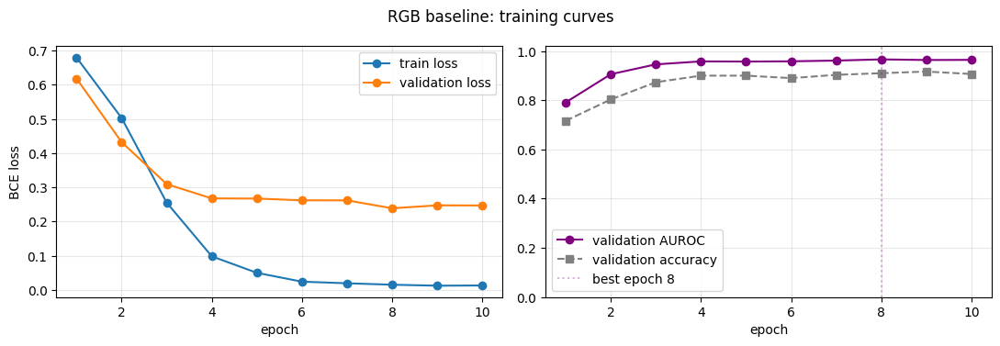

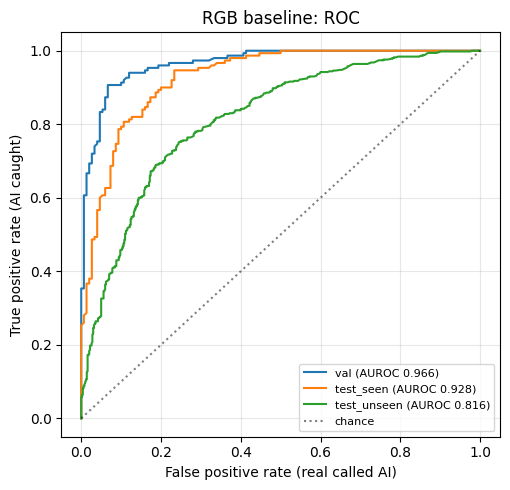

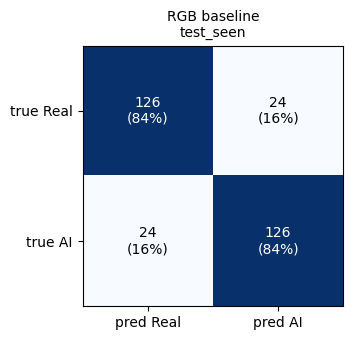

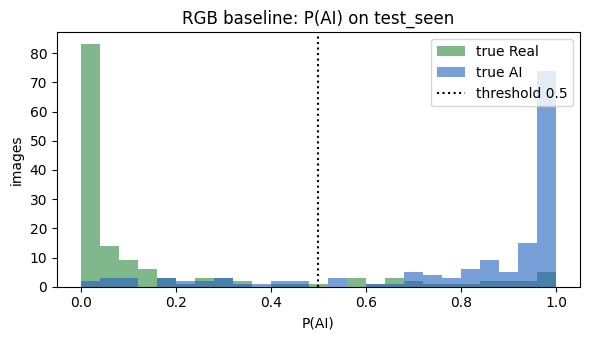

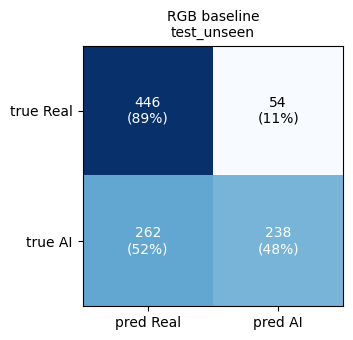

...

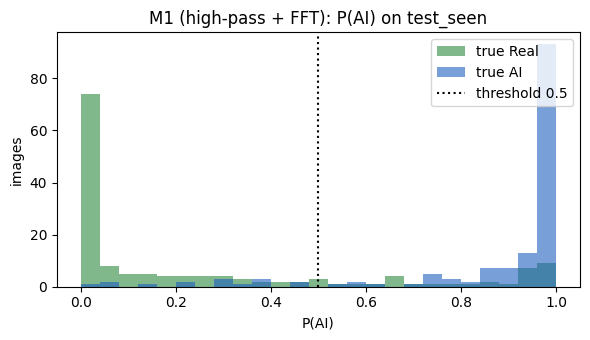

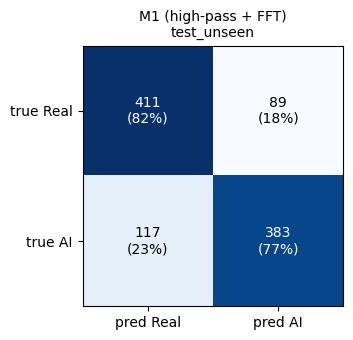

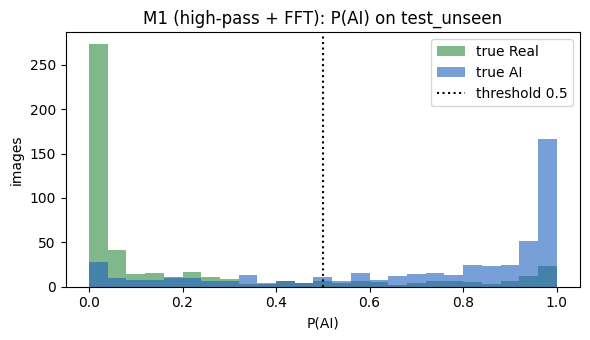

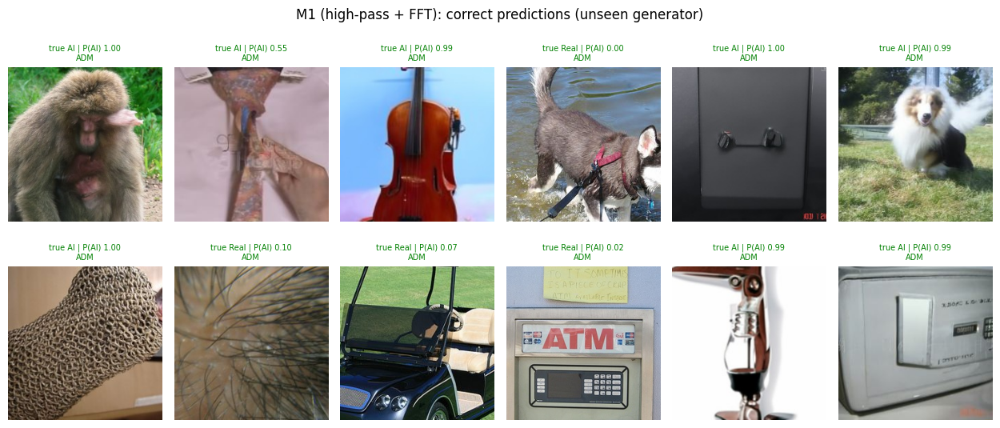

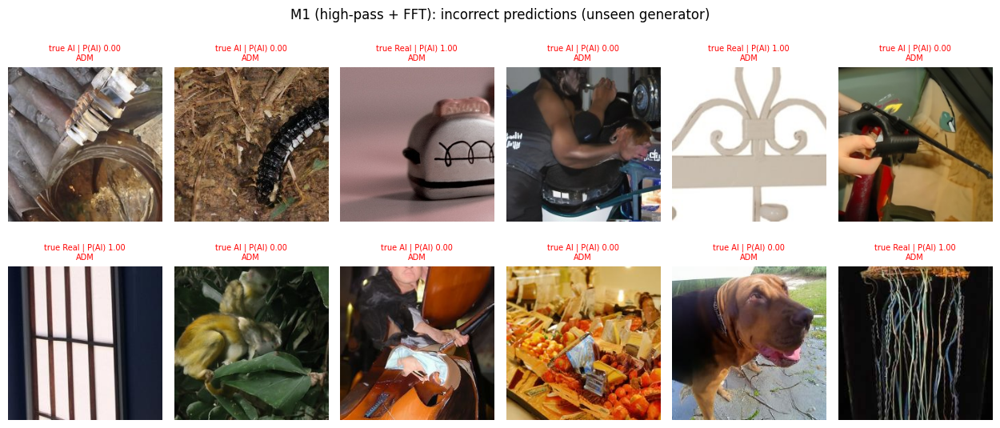

In [53]:
for mode in CONFIG["runs"]["modes"]:
    P = RUN_DIRS[mode] / "plots"
    name = "RGB baseline" if mode == "rgb" else "M1 (high-pass + FFT)"
    h = pd.read_csv(RUN_DIRS[mode] / "history.csv")
    vs_plots.plot_history(h, f"{name}: training curves", P / "history.png")
    vs_plots.plot_roc({s: (PREDS[mode][s]["label"], PREDS[mode][s]["p_ai"]) for s in ("val", "test_seen", "test_unseen")},
                      f"{name}: ROC", P / "roc.png")
    for s in ("test_seen", "test_unseen"):
        vs_plots.plot_confusion(METRICS[mode][s]["confusion_matrix"], f"{name}\n{s}", P / f"confusion_{s}.png")
        vs_plots.plot_score_hist(PREDS[mode][s], f"{name}: P(AI) on {s}", P / f"scores_{s}.png")
    vs_plots.plot_examples(PREDS[mode]["test_unseen"], CACHE["test_unseen"], True,
                           f"{name}: correct predictions (unseen generator)", P / "examples_correct_unseen.png")
    vs_plots.plot_examples(PREDS[mode]["test_unseen"], CACHE["test_unseen"], False,
                           f"{name}: incorrect predictions (unseen generator)", P / "examples_incorrect_unseen.png")

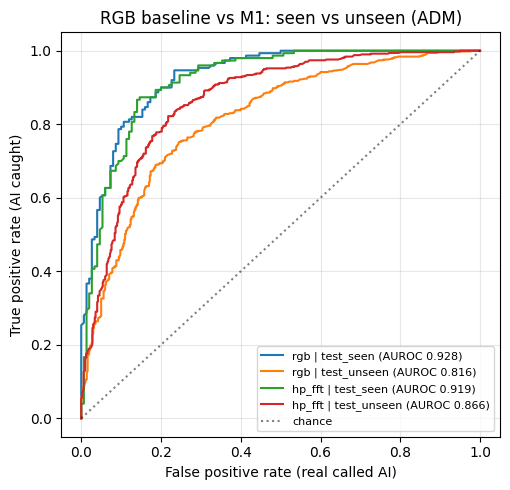

In [54]:
if len(CONFIG["runs"]["modes"]) > 1:
    (RUN_ROOT / "plots").mkdir(exist_ok=True)
    curves = {}
    for mode in CONFIG["runs"]["modes"]:
        for s in ("test_seen", "test_unseen"):
            curves[f"{mode} | {s}"] = (PREDS[mode][s]["label"], PREDS[mode][s]["p_ai"])
    vs_plots.plot_roc(curves, f"RGB baseline vs M1: seen vs unseen ({UNSEEN_GENERATOR})", RUN_ROOT / "plots" / "roc_comparison.png")

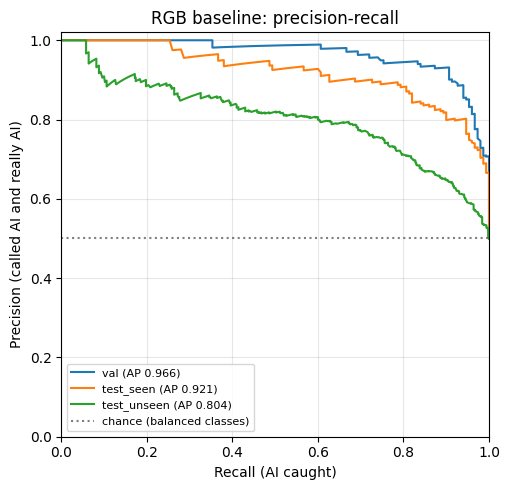

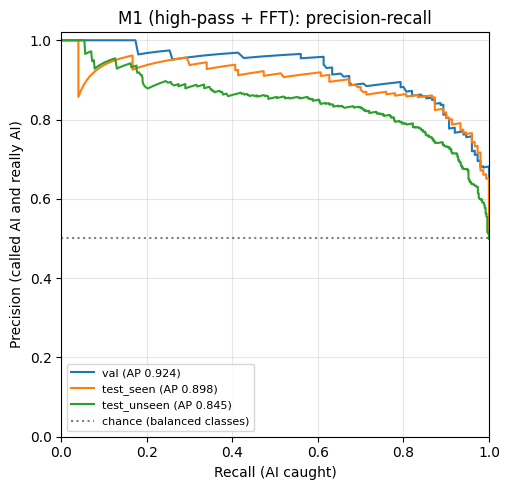

In [55]:
# Precision-recall curves (AI = positive class) for every model and split
from sklearn.metrics import average_precision_score, precision_recall_curve
for mode in CONFIG["runs"]["modes"]:
    name = "RGB baseline" if mode == "rgb" else "M1 (high-pass + FFT)"
    fig, ax = plt.subplots(figsize=(5.2, 5))
    for s in ("val", "test_seen", "test_unseen"):
        y, p = PREDS[mode][s]["label"], PREDS[mode][s]["p_ai"]
        prec, rec, _ = precision_recall_curve(y, p)
        ax.plot(rec, prec, label=f"{s} (AP {average_precision_score(y, p):.3f})")
    ax.axhline(0.5, color="k", ls=":", alpha=.5, label="chance (balanced classes)")
    ax.set_xlabel("Recall (AI caught)"); ax.set_ylabel("Precision (called AI and really AI)")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.set_title(f"{name}: precision-recall"); ax.legend(fontsize=8); ax.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(RUN_DIRS[mode] / "plots" / "pr.png", dpi=120, bbox_inches="tight"); plt.show()

**Expected output:** all the figures listed above, for each model.

## 21 · Checkpoint saving and experiment record
**Purpose:** confirm every required file exists, write a `README.md` for each run, and add one row per model to the project-wide `experiments/experiments_log.csv`, which M2 and Fusion runs will also append to.

```
experiments/<RUN_NAME>/
├── README.md, results_summary.csv/.md, plots/roc_comparison.png, data_plots/
├── rgb/      config.yaml best.pt last.pt history.csv metrics.json predictions_val.csv
│             predictions_test_seen.csv predictions_test_unseen.csv unseen_test_log.json plots/ README.md
└── hp_fft/   (same files)
```

In [56]:
REQUIRED = ["config.yaml", "best.pt", "last.pt", "history.csv", "metrics.json", "predictions_val.csv",
            "predictions_test_seen.csv", "predictions_test_unseen.csv", "plots"]
for mode in CONFIG["runs"]["modes"]:
    d, M = RUN_DIRS[mode], METRICS[mode]
    missing = [f for f in REQUIRED if not (d / f).exists()]
    lines = [f"# {RUN_NAME} / {mode} ({'RGB baseline' if mode == 'rgb' else 'M1: high-pass + FFT ResNet-50'})", "",
             f"- Created: {vs_common.now()}", f"- Split: `{SPLIT_NAME}` (fingerprints {SPLIT_INFO['fingerprints']})",
             f"- Unseen generator: **{UNSEEN_GENERATOR}**; seen: {SPLIT_INFO['seen_generators']}",
             f"- Best epoch (by validation AUROC): {M['best_epoch']}",
             f"- Device: {ENV.get('gpu', ENV['device'])}, torch {ENV['torch']}", "",
             "| split | accuracy | AUROC | precision | recall | F1 |", "|---|---|---|---|---|---|"]
    for s in ("val", "test_seen", "test_unseen"):
        lines.append(f"| {s} | " + " | ".join(f"{M[s][k]:.4f}" for k in vs_metrics.KEYS) + " |")
    lines += ["", f"Generalisation gap (seen - unseen): " + ", ".join(f"{k} {v:+.4f}" for k, v in M["generalization_gap"].items()),
              "", "Files: " + ", ".join(sorted(p.name for p in d.iterdir()))]
    (d / "README.md").write_text("\n".join(lines))
    vs_common.append_csv_row(Path(CONFIG["paths"]["experiments_dir"]) / "experiments_log.csv", {
        "time": vs_common.now(), "run": RUN_NAME, "model": mode, "split_name": SPLIT_NAME, "unseen_generator": UNSEEN_GENERATOR,
        "n_per_class": N_PER_CLASS, "seed": SEED, "best_epoch": M["best_epoch"], "device": ENV.get("gpu", ENV["device"]),
        **{f"val_{k}": M["val"][k] for k in ("accuracy", "auroc")},
        **{f"seen_{k}": M["test_seen"][k] for k in vs_metrics.KEYS},
        **{f"unseen_{k}": M["test_unseen"][k] for k in vs_metrics.KEYS},
        "auroc_gap": M["generalization_gap"]["auroc_gap"], "run_dir": str(d)})
    size = (d / "best.pt").stat().st_size / 1e6
    print(f"{mode:>7}: {'all files present' if not missing else 'MISSING ' + str(missing)}   best.pt {size:.0f} MB   -> {d}")

    rgb: all files present   best.pt 94 MB   -> /content/drive/MyDrive/VeriStamp/experiments/m1_final_n500_unseen_adm/rgb
 hp_fft: all files present   best.pt 94 MB   -> /content/drive/MyDrive/VeriStamp/experiments/m1_final_n500_unseen_adm/hp_fft


**Expected output:** `all files present` for each model, with `best.pt` about 95 MB. `experiments_log.csv` gains one row per model.

## 22 · Final results summary
**Purpose:** one table comparing the **RGB baseline versus M1** and **seen versus unseen** generators, plus the generalisation gap. It is saved as `results_summary.csv` and `.md` in `experiments/<RUN_NAME>/`.

All numbers come from the saved prediction files. Nothing is typed by hand.

In [57]:
rows = []
for mode in CONFIG["runs"]["modes"]:
    M = METRICS[mode]
    for s, label in (("test_seen", "seen generators"), ("test_unseen", f"unseen: {UNSEEN_GENERATOR}")):
        rows.append({"model": "RGB baseline" if mode == "rgb" else ("M1 (high-pass + FFT)" if mode == "hp_fft" else mode),
                     "test set": label, "n": M[s]["n"], **{k: M[s][k] for k in vs_metrics.KEYS}})
RESULTS = pd.DataFrame(rows)
GAPS = pd.DataFrame([{"model": "RGB baseline" if m == "rgb" else ("M1 (high-pass + FFT)" if m == "hp_fft" else m),
                      **{k: METRICS[m]["generalization_gap"][f"{k}_gap"] for k in vs_metrics.KEYS}}
                     for m in CONFIG["runs"]["modes"]])
print("RESULTS (threshold 0.5 for accuracy / precision / recall / F1)")
print(RESULTS.round(4).to_string(index=False))
print("\nGENERALISATION GAP = seen - unseen  (positive = drop on the unseen generator)")
print(GAPS.round(4).to_string(index=False))
RESULTS.to_csv(RUN_ROOT / "results_summary.csv", index=False)
GAPS.to_csv(RUN_ROOT / "generalization_gap.csv", index=False)
md_lines = [f"# {RUN_NAME}: M1 results", "", f"Split `{SPLIT_NAME}`; unseen generator **{UNSEEN_GENERATOR}**; "
            f"{N_PER_CLASS} images per class per generator; seed {SEED}.", "",
            vs_common.df_to_markdown(RESULTS), "", "Generalisation gap (seen - unseen):", "",
            vs_common.df_to_markdown(GAPS)]
(RUN_ROOT / "results_summary.md").write_text("\n".join(md_lines))
(RUN_ROOT / "README.md").write_text("\n".join(md_lines + ["", "Sub-folders: " + ", ".join(CONFIG["runs"]["modes"]) + " (one per model)."]))
print("\nSaved:", RUN_ROOT / "results_summary.csv", "and .md")

RESULTS (threshold 0.5 for accuracy / precision / recall / F1)
               model        test set    n  accuracy  auroc  precision  recall     f1
        RGB baseline seen generators  300    0.8400 0.9277     0.8400   0.840 0.8400
        RGB baseline     unseen: ADM 1000    0.6840 0.8156     0.8151   0.476 0.6010
M1 (high-pass + FFT) seen generators  300    0.8433 0.9188     0.8084   0.900 0.8517
M1 (high-pass + FFT)     unseen: ADM 1000    0.7940 0.8656     0.8114   0.766 0.7881

GENERALISATION GAP = seen - unseen  (positive = drop on the unseen generator)
               model  accuracy  auroc  precision  recall     f1
        RGB baseline    0.1560 0.1121     0.0249   0.364 0.2390
M1 (high-pass + FFT)    0.0493 0.0532    -0.0031   0.134 0.0637

Saved: /content/drive/MyDrive/VeriStamp/experiments/m1_final_n500_unseen_adm/results_summary.csv and .md


**How to read the table (no conclusions until you have real numbers):**
- **AUROC on unseen** is the main RQ1 number for M1.
- **The gap** shows how much each model drops on the unfamiliar generator. Compare the RGB and M1 gaps.
- **This is one of 3 folds, with one seed (42)**: the RQ1 result is the per-fold table plus the mean over the 3 folds (Section 23b). The proposal planned 3k–5k images per class; this uses 500.
- With `N_PER_CLASS = 500`, use the paired intervals of Section 23 rather than the raw difference of two numbers.

## 23 · RGB vs M1 on this fold, and the cross-fold table
**Purpose:** the paired RGB → M1 comparison (same images, 95% bootstrap interval) for this fold, then **23b**: one table with every fold that has results so far (fold 1 = `m1_final_n500`), and the mean over the folds. The earlier runs (`m1_run_001` … `m1_native_crop_equal_jpeg`) are not compared here: they have a different unseen generator.

In [58]:
EXP = Path(CONFIG["paths"]["experiments_dir"])
RUN_ORDER = [RUN_NAME]                     # this fold only (other folds have a different unseen generator)
MODE_NAME = {"rgb": "RGB baseline", "hp_fft": "M1 (high-pass + FFT)"}
EVAL_SPLITS = ("val", "test_seen", "test_unseen")

def load_run(run):
    out = {}
    for mode in ("rgb", "hp_fft"):
        d = EXP / run / mode
        if (d / "metrics.json").exists() and all((d / f"predictions_{s}.csv").exists() for s in EVAL_SPLITS):
            out[mode] = {"metrics": vs_common.load_json(d / "metrics.json"),
                         "preds": {s: pd.read_csv(d / f"predictions_{s}.csv", dtype={"image_id": str}) for s in EVAL_SPLITS}}
    return out

RUNS = {r: load_run(r) for r in RUN_ORDER}
RUNS = {r: v for r, v in RUNS.items() if v}
print("Runs with saved results:", {r: list(v) for r, v in RUNS.items()})
SHARED_UNSEEN = sorted(set.intersection(*[set(m["preds"]["test_unseen"]["image_id"]) for v in RUNS.values() for m in v.values()]))
print(f"Unseen ({UNSEEN_GENERATOR}) test images: {len(SHARED_UNSEEN)}")

def metric_row(run, mode, split, p):
    m = vs_metrics.classification_metrics(p["label"], p["p_ai"])
    lo, hi = vs_native.bootstrap_auroc_ci(p["label"], p["p_ai"], seed=SEED)
    (tn, fp), (fn, tp) = m["confusion_matrix"]
    return {"run": run, "model": MODE_NAME[mode], "split": split, "n": m["n"], "auroc": m["auroc"],
            "auroc_ci_low": lo, "auroc_ci_high": hi, "accuracy": m["accuracy"], "precision": m["precision"],
            "recall_ai_detection": m["recall"], "real_accuracy": m["real_accuracy"], "f1": m["f1"],
            "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "seen_generators": "/".join(sorted(p.loc[p["label"] == 1, "generator"].unique())) if split != "test_unseen" else ""}

rows = []
for run, v in RUNS.items():
    for mode, d in v.items():
        for s in EVAL_SPLITS:
            rows.append(metric_row(run, mode, s, d["preds"][s]))
        rows.append(metric_row(run, mode, "test_unseen_shared", d["preds"]["test_unseen"].query("image_id in @SHARED_UNSEEN")))
COMPARISON = pd.DataFrame(rows)

def paired(pa, pb):
    """Align two prediction tables on image_id; None if they do not contain the same images."""
    if set(pa["image_id"]) != set(pb["image_id"]):
        return None
    m = pa[["image_id", "label", "p_ai"]].merge(pb[["image_id", "p_ai"]], on="image_id", suffixes=("_a", "_b"))
    return vs_native.paired_bootstrap_auroc(m["label"], m["p_ai_a"], m["p_ai_b"], seed=SEED)

PAIRS = []                                 # no between-run comparison: only RGB -> M1 within this fold
prow = []
for a, b, what in PAIRS:
    if a not in RUNS or b not in RUNS:
        print(f"(skipped: {a} -> {b}; {'both runs' if a not in RUNS and b not in RUNS else (a if a not in RUNS else b)} not available yet)")
        continue
    for mode in ("rgb", "hp_fft"):
        if mode not in RUNS[a] or mode not in RUNS[b]:
            continue
        for s in EVAL_SPLITS:
            pa, pb = RUNS[a][mode]["preds"][s], RUNS[b][mode]["preds"][s]
            if s == "test_unseen":
                pa, pb = pa.query("image_id in @SHARED_UNSEEN"), pb.query("image_id in @SHARED_UNSEEN")
            r = paired(pa, pb)
            prow.append({"comparison": f"{a} -> {b}", "effect_of": what, "model": MODE_NAME[mode], "split": s,
                         **(r or {"n": None}), "verdict": vs_native.verdict(r["ci_low"], r["ci_high"]) if r
                         else "not comparable: different images"})
for run, v in RUNS.items():
    if run == "m1_run_001" or not {"rgb", "hp_fft"} <= set(v):
        continue
    for s in EVAL_SPLITS:
        r = paired(v["rgb"]["preds"][s], v["hp_fft"]["preds"][s])
        prow.append({"comparison": f"{run}: RGB -> M1", "effect_of": "high-pass + FFT input instead of RGB",
                     "model": "M1 minus RGB", "split": s, **r, "verdict": vs_native.verdict(r["ci_low"], r["ci_high"])})
PAIR_TABLE = pd.DataFrame(prow)

CMP_DIR = RUN_ROOT / "comparison"; CMP_DIR.mkdir(exist_ok=True)
COMPARISON.to_csv(CMP_DIR / "comparison_results.csv", index=False)
PAIR_TABLE.to_csv(CMP_DIR / "comparison_pairs.csv", index=False)
show = ["run", "model", "split", "n", "auroc", "auroc_ci_low", "auroc_ci_high", "accuracy", "precision",
        "recall_ai_detection", "real_accuracy", "f1", "TN", "FP", "FN", "TP"]
print("\n1. Metrics per run, model and split (threshold 0.5; AUROC with 95% bootstrap interval):")
print(COMPARISON[show].round(3).to_string(index=False))
if len(PAIR_TABLE):
    print("\n2. Differences (B - A) in AUROC, paired on the same images, with 95% interval:")
    print(PAIR_TABLE[["comparison", "model", "split", "n", "auroc_a", "auroc_b", "diff", "ci_low", "ci_high", "verdict"]]
          .round(3).to_string(index=False))

Runs with saved results: {'m1_final_n500_unseen_adm': ['rgb', 'hp_fft']}
Unseen (ADM) test images: 1000

1. Metrics per run, model and split (threshold 0.5; AUROC with 95% bootstrap interval):
                     run                model              split    n  auroc  auroc_ci_low  auroc_ci_high  accuracy  precision  recall_ai_detection  real_accuracy    f1  TN  FP  FN  TP
m1_final_n500_unseen_adm         RGB baseline                val  300  0.966         0.947          0.982     0.910      0.913                0.907          0.913 0.910 137  13  14 136
m1_final_n500_unseen_adm         RGB baseline          test_seen  300  0.928         0.899          0.955     0.840      0.840                0.840          0.840 0.840 126  24  24 126
m1_final_n500_unseen_adm         RGB baseline        test_unseen 1000  0.816         0.789          0.841     0.684      0.815                0.476          0.892 0.601 446  54 262 238
m1_final_n500_unseen_adm         RGB baseline test_unseen_shared 10

3. Shortcut diagnostic (mean P(AI) on val + test_seen; 'upscaled' = enlarged by the old pipeline, or would have been):
                     run                model  real_upscaled_P(AI)  n_upscaled  real_not_upscaled_P(AI)  AI_VQDM_P(AI)  AI_stable_diffusion_v_1_4_P(AI)
m1_final_n500_unseen_adm         RGB baseline                0.414           6                    0.151          0.830                            0.863
m1_final_n500_unseen_adm M1 (high-pass + FFT)                0.649           6                    0.246          0.851                            0.923


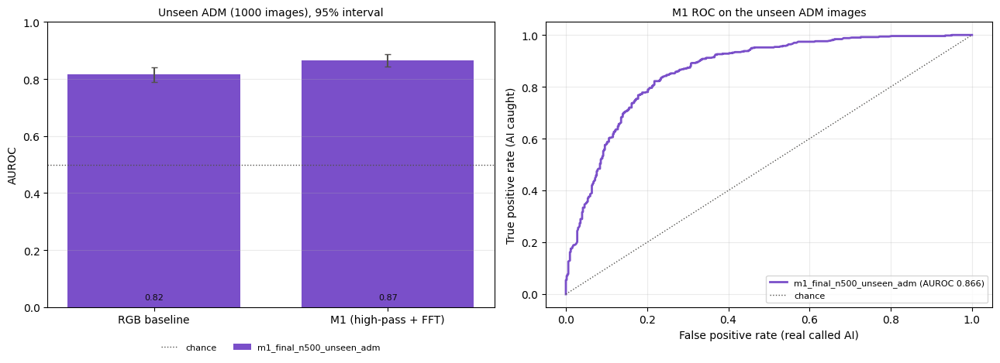


Saved in /content/drive/MyDrive/VeriStamp/experiments/m1_final_n500_unseen_adm/comparison : ['comparison_pairs.csv', 'comparison_plots.png', 'comparison_results.csv', 'comparison_results.md']


In [59]:
# 3. shortcut diagnostic of each run (saved in 17b), and 4. the comparison figure
diag = []
for run, v in RUNS.items():
    for mode in v:
        f = EXP / run / mode / "shortcut_diagnostic.json"
        if f.exists():
            d = vs_common.load_json(f)
            diag.append({"run": run, "model": MODE_NAME[mode], "real_upscaled_P(AI)": d["real_upscaled_mean_p_ai"],
                         "n_upscaled": d["real_upscaled_n"], "real_not_upscaled_P(AI)": d["real_not_upscaled_mean_p_ai"],
                         **{f"AI_{g}_P(AI)": x for g, x in d["ai_mean_p_ai"].items()}})
DIAG = pd.DataFrame(diag).round(3)
print("3. Shortcut diagnostic (mean P(AI) on val + test_seen; 'upscaled' = enlarged by the old pipeline, or would have been):")
print(DIAG.to_string(index=False) if len(DIAG) else "  none saved")

RUN_COLOR = {RUN_NAME: "#7a4fc9"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
shared = COMPARISON[COMPARISON["split"] == "test_unseen_shared"]
models = [MODE_NAME[m] for m in ("rgb", "hp_fft")]
width = 0.8 / max(1, len(RUNS))
for k, run in enumerate(RUNS):
    r = shared[shared["run"] == run].set_index("model").reindex(models)
    x = np.arange(len(models)) + (k - (len(RUNS) - 1) / 2) * width
    ax1.bar(x, r["auroc"], width * 0.92, color=RUN_COLOR[run], label=run,
            yerr=[r["auroc"] - r["auroc_ci_low"], r["auroc_ci_high"] - r["auroc"]], capsize=3, ecolor="#52514e")
    for xi, val in zip(x, r["auroc"]):
        if pd.notna(val):
            ax1.text(xi, 0.02, f"{val:.2f}", ha="center", va="bottom", fontsize=8, color="#0b0b0b")
ax1.axhline(0.5, color="#52514e", ls=":", lw=1, label="chance")
ax1.set_xticks(np.arange(len(models)), models); ax1.set_ylim(0, 1); ax1.set_ylabel("AUROC")
ax1.set_title(f"Unseen {UNSEEN_GENERATOR} ({len(SHARED_UNSEEN)} images), 95% interval", fontsize=10)
ax1.grid(axis="y", alpha=.25); ax1.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
from sklearn.metrics import roc_curve
for run, v in RUNS.items():
    if "hp_fft" in v:
        p = v["hp_fft"]["preds"]["test_unseen"].query("image_id in @SHARED_UNSEEN")
        fpr, tpr, _ = roc_curve(p["label"], p["p_ai"])
        auc = shared.loc[(shared["run"] == run) & (shared["model"] == MODE_NAME["hp_fft"]), "auroc"].iloc[0]
        ax2.plot(fpr, tpr, color=RUN_COLOR[run], lw=2, label=f"{run} (AUROC {auc:.3f})")
ax2.plot([0, 1], [0, 1], color="#52514e", ls=":", lw=1, label="chance")
ax2.set_xlabel("False positive rate (real called AI)"); ax2.set_ylabel("True positive rate (AI caught)")
ax2.set_title(f"M1 ROC on the unseen {UNSEEN_GENERATOR} images", fontsize=10); ax2.grid(alpha=.25); ax2.legend(fontsize=8)
plt.tight_layout(); plt.savefig(CMP_DIR / "comparison_plots.png", dpi=130, bbox_inches="tight"); plt.show()

md = [f"# M1 comparison (written by {RUN_NAME})", "", f"Created {vs_common.now()}. Runs available: {', '.join(RUNS)}.",
      f"Fold {FOLD}: unseen metrics on the {len(SHARED_UNSEEN)} {UNSEEN_GENERATOR} images.", "",
      "## Metrics", "", vs_common.df_to_markdown(COMPARISON[show].round(4)), ""]
if len(PAIR_TABLE):
    md += ["## Paired AUROC differences (B - A, 95% bootstrap interval)", "",
           vs_common.df_to_markdown(PAIR_TABLE[["comparison", "model", "split", "n", "auroc_a", "auroc_b", "diff",
                                                "ci_low", "ci_high", "verdict"]].round(4)), ""]
if len(DIAG):
    md += ["## Shortcut diagnostic (val + test_seen)", "", vs_common.df_to_markdown(DIAG), ""]
md += ["Seen-generator numbers are only compared between runs with the same seen images (see the paired table).",
       "The preprocessing was frozen before fold 1; these results are reported, not used for tuning."]
(CMP_DIR / "comparison_results.md").write_text("\n".join(md))
print("\nSaved in", CMP_DIR, ":", sorted(p.name for p in CMP_DIR.iterdir()))

**How to read it (no conclusion is drawn automatically).**

| What you see in `<run>: RGB -> M1` on `test_unseen` | What it means for this fold |
|---|---|
| interval above 0 | M1 generalises better than RGB to this unseen generator |
| interval contains 0 | no detectable difference at this size |
| interval below 0 | RGB generalises better here: report it honestly |

All of these are valid findings. Expect folds 2 and 3 to differ from fold 1: ADM and VQDM are similar to each other (256 px, ImageNet class-conditional), so holding one out while training on the other is probably easier than holding out Stable Diffusion. Higher AUROCs here do not mean M1 improved.

In [60]:
# 23b · Cross-fold table: every fold with results so far (other folds are only READ)
FOLD_RUNS = {1: (FOLD1_RUN, "stable_diffusion_v_1_4")} | {k: (f["run"], f["unseen"]) for k, f in FOLDS.items()}
rows = []
for k, (run, unseen) in sorted(FOLD_RUNS.items()):
    f = (CMP_DIR if run == RUN_NAME else EXP / run / "comparison") / "comparison_pairs.csv"
    if not f.exists():
        print(f"fold {k} ({run}): no results yet"); continue
    p = pd.read_csv(f)
    p = p[(p["comparison"] == f"{run}: RGB -> M1") & (p["split"] == "test_unseen")]
    if p.empty:
        print(f"fold {k} ({run}): RGB -> M1 row missing"); continue
    r = p.iloc[0]
    rows.append({"fold": k, "run": run, "unseen": unseen, "n": int(r["n"]), "RGB_auroc": r["auroc_a"], "M1_auroc": r["auroc_b"],
                 "M1_minus_RGB": r["diff"], "ci_low": r["ci_low"], "ci_high": r["ci_high"], "verdict": r["verdict"]})
CROSS_FOLD = pd.DataFrame(rows)
print(CROSS_FOLD.round(3).to_string(index=False))
if len(CROSS_FOLD):
    print(f"\nMean over {len(CROSS_FOLD)} fold(s): RGB {CROSS_FOLD['RGB_auroc'].mean():.3f} | M1 {CROSS_FOLD['M1_auroc'].mean():.3f} | "
          f"M1 - RGB {CROSS_FOLD['M1_minus_RGB'].mean():+.3f}  (folds above 0: {(CROSS_FOLD['ci_low'] > 0).sum()}, "
          f"containing 0: {((CROSS_FOLD['ci_low'] <= 0) & (CROSS_FOLD['ci_high'] >= 0)).sum()}, below 0: {(CROSS_FOLD['ci_high'] < 0).sum()})")
    if len(CROSS_FOLD) < 3:
        print("Not all 3 folds have results yet: this mean is NOT the final 3-fold result.")
CROSS_FOLD.to_csv(CMP_DIR / "cross_fold_summary.csv", index=False)
print("Saved", CMP_DIR / "cross_fold_summary.csv")

fold 3 (m1_final_n500_unseen_vqdm): no results yet
 fold                      run                 unseen    n  RGB_auroc  M1_auroc  M1_minus_RGB  ci_low  ci_high                             verdict
    1            m1_final_n500 stable_diffusion_v_1_4 1000      0.680     0.712         0.031   0.001    0.059 higher; the 95% interval excludes 0
    2 m1_final_n500_unseen_adm                    ADM 1000      0.816     0.866         0.050   0.028    0.072 higher; the 95% interval excludes 0

Mean over 2 fold(s): RGB 0.748 | M1 0.789 | M1 - RGB +0.041  (folds above 0: 2, containing 0: 0, below 0: 0)
Not all 3 folds have results yet: this mean is NOT the final 3-fold result.
Saved /content/drive/MyDrive/VeriStamp/experiments/m1_final_n500_unseen_adm/comparison/cross_fold_summary.csv


## 24 · JPEG degradation test (GenImage degradation track, quality 65 and 30)
**Purpose:** do the trained detectors still work when the test image has been JPEG-compressed, as happens when images are shared online? Evaluation only: the checkpoints from Section 15 are **scored**, never retrained.

```
original test image ─► JPEG at quality 65 (or 30), whole image, 4:2:0 ─► decode
                    ─► the SAME frozen preprocessing as always (equal JPEG 75–95, aligned central tile)
                    ─► centre 224 crop ─► best.pt (RGB and M1)
```
- "clean" = the normal test images (they still get the standard 75–95 JPEG step, like every image in this project).
- The same images, labels and crops as Sections 17–18: only the extra compression differs, so clean vs degraded is **paired**.
- Saved: `predictions_<split>_jpeg<q>.csv` in each model folder, and `jpeg_degradation/` with the table, the paired differences and a plot.


In [61]:
DEG = CONFIG["degradation"]
DEG_DIR = RUN_ROOT / "jpeg_degradation"; DEG_DIR.mkdir(exist_ok=True)
DEG_PREDS = {m: {} for m in CONFIG["runs"]["modes"]}
for q in DEG["jpeg_qualities"]:
    for s in DEG["splits"]:
        local = Path(CONFIG["paths"]["cache_local"]) / SPLIT_NAME / f"{s}_native{PCFG['tile_size']}_jpeg{q}.npy"
        meta = vs_m1eval.build_degraded_cache(SPLITS[s], local, PCFG, SEED, q, DEG["subsampling"], CONFIG["data"]["hash_workers"])
        ds = vs_native.NativeCachedDataset(SPLITS[s], local, crop, False, hflip, meta["valid_h"], meta["valid_w"], PCFG["align"])
        loader = vs_preprocess.make_loader(ds, BS, False, NW, SEED)
        for mode in CONFIG["runs"]["modes"]:
            model, _ = load_best(mode)
            pv, _ = vs_train.predict(model, loader, DEVICE, AMP)
            preds = vs_train.predictions_with_meta(pv, SPLITS[s], f"{s}_jpeg{q}", f"{RUN_NAME}/{mode}")
            preds.to_csv(RUN_DIRS[mode] / f"predictions_{s}_jpeg{q}.csv", index=False)
            DEG_PREDS[mode][(s, q)] = preds
            del model
        print(f"JPEG {q:>2} | {s:<11} scored for {CONFIG['runs']['modes']}")

LEVELS = ["clean"] + [f"jpeg{q}" for q in DEG["jpeg_qualities"]]
def deg_preds(mode, s, level):
    return PREDS[mode][s] if level == "clean" else DEG_PREDS[mode][(s, int(level[4:]))]

rows = []
for mode in CONFIG["runs"]["modes"]:
    for s in DEG["splits"]:
        for level in LEVELS:
            p = deg_preds(mode, s, level)
            m = vs_metrics.classification_metrics(p["label"], p["p_ai"])
            lo, hi = vs_native.bootstrap_auroc_ci(p["label"], p["p_ai"], seed=SEED)
            rows.append({"model": MODE_NAME[mode], "split": s, "level": level, "n": m["n"], "auroc": m["auroc"],
                         "auroc_ci_low": lo, "auroc_ci_high": hi, "accuracy": m["accuracy"],
                         "recall_ai_detection": m["recall"], "real_accuracy": m["real_accuracy"]})
DEG_TABLE = pd.DataFrame(rows)

prow = []
for s in DEG["splits"]:
    for level in LEVELS[1:]:
        for mode in CONFIG["runs"]["modes"]:                  # drop caused by compression, same images
            a, b = deg_preds(mode, s, "clean"), deg_preds(mode, s, level)
            r = vs_native.paired_bootstrap_auroc(a["label"], a["p_ai"], b.set_index("image_id").loc[a["image_id"], "p_ai"], seed=SEED)
            prow.append({"comparison": f"clean -> {level}", "model": MODE_NAME[mode], "split": s, **r,
                         "verdict": vs_native.verdict(r["ci_low"], r["ci_high"])})
    for level in LEVELS:                                      # M1 minus RGB at each compression level
        a, b = deg_preds("rgb", s, level), deg_preds("hp_fft", s, level)
        r = vs_native.paired_bootstrap_auroc(a["label"], a["p_ai"], b.set_index("image_id").loc[a["image_id"], "p_ai"], seed=SEED)
        prow.append({"comparison": f"RGB -> M1 at {level}", "model": "M1 minus RGB", "split": s, **r,
                     "verdict": vs_native.verdict(r["ci_low"], r["ci_high"])})
DEG_PAIRS = pd.DataFrame(prow)
DEG_TABLE.to_csv(DEG_DIR / "degradation_results.csv", index=False)
DEG_PAIRS.to_csv(DEG_DIR / "degradation_pairs.csv", index=False)
print("\n1. AUROC (95% interval), accuracy and detection rates at threshold 0.5:")
print(DEG_TABLE.round(3).to_string(index=False))
print("\n2. Paired AUROC differences (B - A, same images, 95% interval):")
print(DEG_PAIRS[["comparison", "model", "split", "n", "auroc_a", "auroc_b", "diff", "ci_low", "ci_high", "verdict"]]
      .round(3).to_string(index=False))


JPEG 65 + native test_seen_native256_jpeg65:   0%|          | 0/300 [00:00<?, ?it/s]

JPEG 65 | test_seen   scored for ['rgb', 'hp_fft']


JPEG 65 + native test_unseen_native256_jpeg65:   0%|          | 0/1000 [00:00<?, ?it/s]

JPEG 65 | test_unseen scored for ['rgb', 'hp_fft']


JPEG 30 + native test_seen_native256_jpeg30:   0%|          | 0/300 [00:00<?, ?it/s]

JPEG 30 | test_seen   scored for ['rgb', 'hp_fft']


JPEG 30 + native test_unseen_native256_jpeg30:   0%|          | 0/1000 [00:00<?, ?it/s]

JPEG 30 | test_unseen scored for ['rgb', 'hp_fft']

1. AUROC (95% interval), accuracy and detection rates at threshold 0.5:
               model       split  level    n  auroc  auroc_ci_low  auroc_ci_high  accuracy  recall_ai_detection  real_accuracy
        RGB baseline   test_seen  clean  300  0.928         0.899          0.955     0.840                0.840          0.840
        RGB baseline   test_seen jpeg65  300  0.921         0.892          0.949     0.843                0.833          0.853
        RGB baseline   test_seen jpeg30  300  0.894         0.859          0.926     0.793                0.760          0.827
        RGB baseline test_unseen  clean 1000  0.816         0.789          0.841     0.684                0.476          0.892
        RGB baseline test_unseen jpeg65 1000  0.778         0.751          0.805     0.675                0.438          0.912
        RGB baseline test_unseen jpeg30 1000  0.745         0.715          0.774     0.639                0.414   

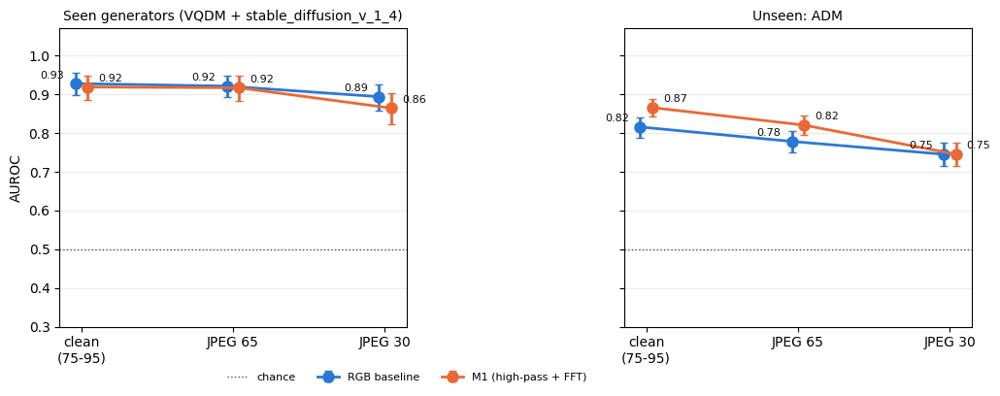

Saved in /content/drive/MyDrive/VeriStamp/experiments/m1_final_n500_unseen_adm/jpeg_degradation : ['degradation_auroc.png', 'degradation_pairs.csv', 'degradation_results.csv']


In [62]:
# Plot: AUROC by compression level, one panel per test set (95% intervals)
MODEL_COLOR = {"RGB baseline": "#2a78d6", "M1 (high-pass + FFT)": "#eb6834"}
x_names = {"clean": "clean\n(75-95)", **{f"jpeg{q}": f"JPEG {q}" for q in DEG["jpeg_qualities"]}}
fig, axes = plt.subplots(1, len(DEG["splits"]), figsize=(5.2 * len(DEG["splits"]), 4.2), sharey=True)
for ax, s in zip(np.atleast_1d(axes), DEG["splits"]):
    for k, (name, color) in enumerate(MODEL_COLOR.items()):
        r = DEG_TABLE[(DEG_TABLE["split"] == s) & (DEG_TABLE["model"] == name)].set_index("level").reindex(LEVELS)
        x = np.arange(len(LEVELS)) + (k - 0.5) * 0.08
        ax.errorbar(x, r["auroc"], yerr=[r["auroc"] - r["auroc_ci_low"], r["auroc_ci_high"] - r["auroc"]],
                    color=color, lw=2, marker="o", ms=8, capsize=3, label=name)
        for xi, v in zip(x, r["auroc"]):
            ax.annotate(f"{v:.2f}", (xi, v), textcoords="offset points", xytext=(8 if k else -26, 4), fontsize=8, color="#0b0b0b")
    ax.axhline(0.5, color="#52514e", ls=":", lw=1, label="chance")
    ax.set_xticks(np.arange(len(LEVELS)), [x_names[l] for l in LEVELS])
    title = f"Seen generators ({' + '.join(ROLES['seen'])})" if s == "test_seen" else f"Unseen: {UNSEEN_GENERATOR}"
    ax.set_title(title, fontsize=10); ax.set_ylim(0.3, 1.07); ax.grid(axis="y", alpha=.25)
np.atleast_1d(axes)[0].set_ylabel("AUROC")
np.atleast_1d(axes)[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5 * len(DEG["splits"]), -0.12),
                              ncol=3, frameon=False)
plt.tight_layout(); plt.savefig(DEG_DIR / "degradation_auroc.png", dpi=130, bbox_inches="tight"); plt.show()
print("Saved in", DEG_DIR, ":", sorted(p.name for p in DEG_DIR.iterdir()))


**Expected output:** progress bars for 4 degraded caches (2 qualities × 2 test sets), then two tables and a figure.

**How to read it:**
- `clean -> jpeg65 / jpeg30`: how much each model **loses** under compression (negative = drop). A drop is expected, especially at 30: compression removes exactly the fine high-frequency detail that M1 reads.
- `RGB -> M1 at <level>`: whether M1's advantage (or disadvantage) survives compression.
- Recall vs real accuracy: compression can push **all** images towards one class (for example, everything looks "Real"). AUROC may hold up while accuracy at 0.5 falls; both are reported.

## 25 · Grad-CAM: where does each model look?
**Purpose:** show which parts of the 224×224 crop raise the score of the predicted class, for M1 and, for comparison, the RGB baseline on the **same** images. Evaluation only.

- Layer: the last ResNet block (`layer4`, a 7×7 grid), enlarged to 224×224. Red = more influence. Each map is scaled 0–1 on its own, so compare **where**, not how strong.
- Explained score: the predicted class (+logit if predicted AI, −logit if predicted Real).
- Images are chosen automatically from M1's predictions on the clean test sets, 4 per group: seen AI caught, seen Real correct, unseen AI caught, unseen AI **missed**, and unseen Real wrongly called AI. Most confident first; ties by image ID.
- **Average maps** over up to 64 images per group show systematic patterns (for example attention on borders or a regular grid would be suspicious).
- Grad-CAM is a rough, qualitative tool. It does not prove *why* a model decides; it shows where the evidence it used is located.


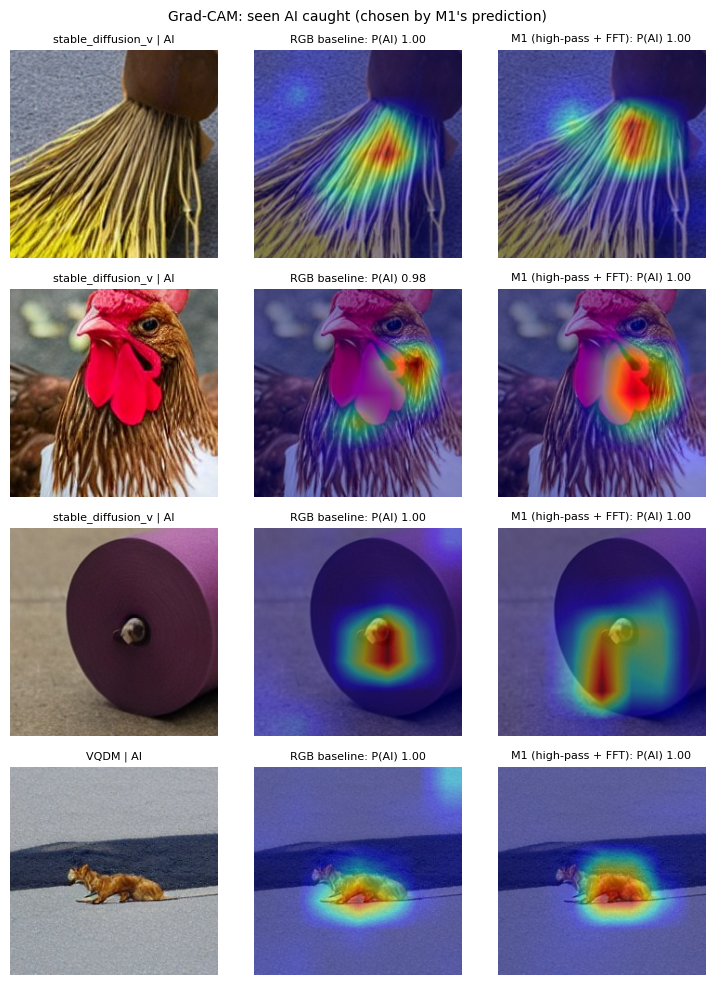

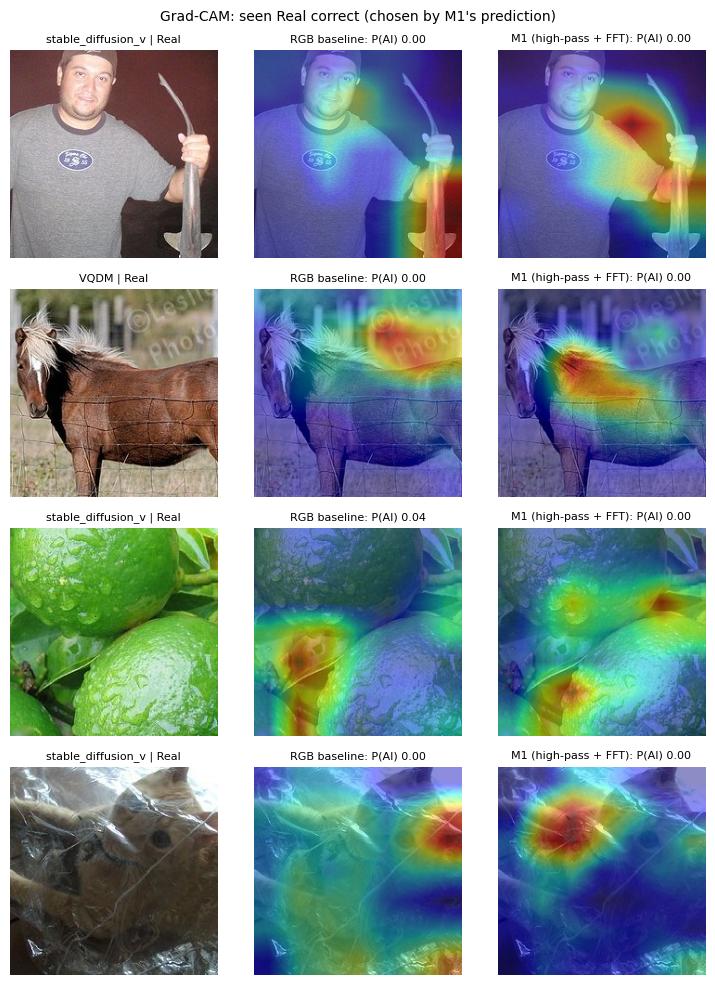

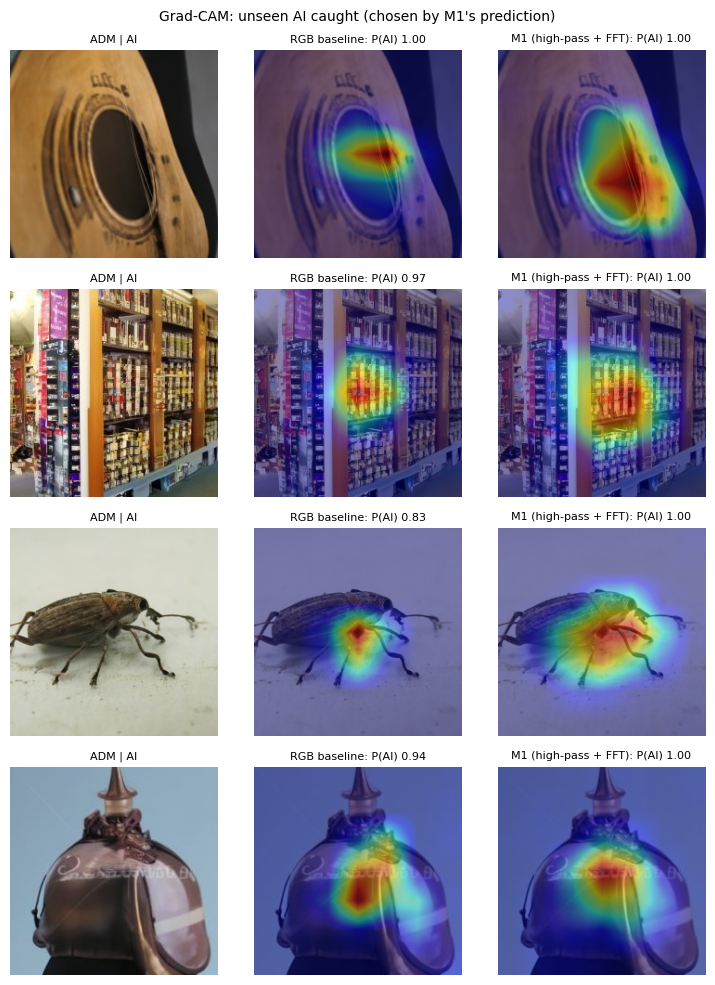

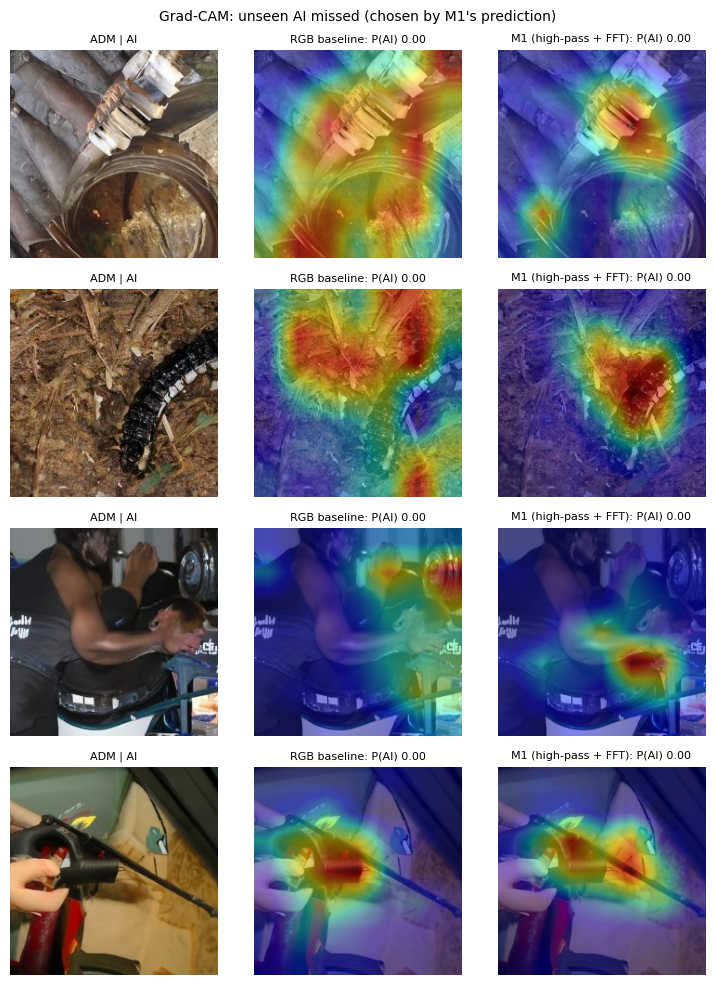

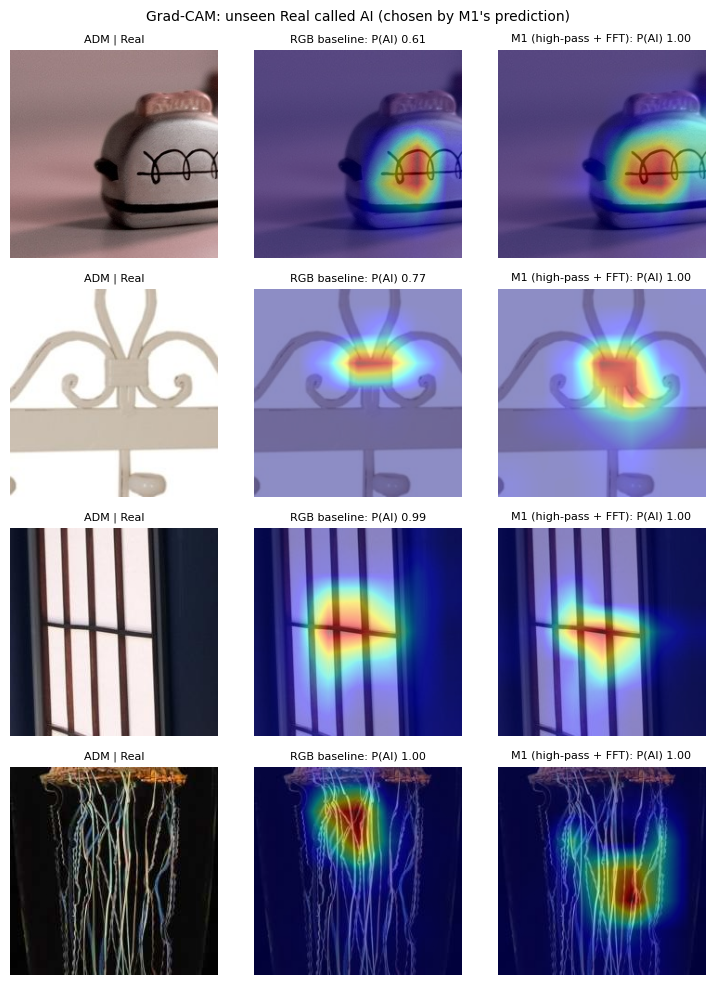

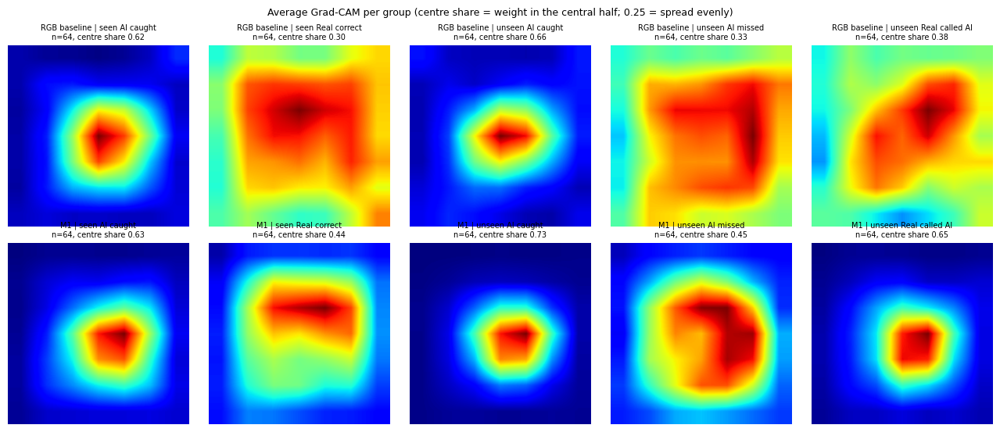

                group                model  n  centre_share
       seen AI caught         RGB baseline 64         0.624
       seen AI caught M1 (high-pass + FFT) 64         0.626
    seen Real correct         RGB baseline 64         0.300
    seen Real correct M1 (high-pass + FFT) 64         0.436
     unseen AI caught         RGB baseline 64         0.658
     unseen AI caught M1 (high-pass + FFT) 64         0.733
     unseen AI missed         RGB baseline 64         0.332
     unseen AI missed M1 (high-pass + FFT) 64         0.449
unseen Real called AI         RGB baseline 64         0.383
unseen Real called AI M1 (high-pass + FFT) 64         0.650

Saved in /content/drive/MyDrive/VeriStamp/experiments/m1_final_n500_unseen_adm/gradcam : ['gradcam_average.csv', 'gradcam_average.png', 'gradcam_images.csv', 'gradcam_seen_AI_caught.png', 'gradcam_seen_Real_correct.png', 'gradcam_unseen_AI_caught.png', 'gradcam_unseen_AI_missed.png', 'gradcam_unseen_Real_called_AI.png']


In [63]:
GC = CONFIG["gradcam"]
GC_DIR = RUN_ROOT / "gradcam"; GC_DIR.mkdir(exist_ok=True)
m1p = {s: PREDS["hp_fft"][s] for s in ("test_seen", "test_unseen")}
GROUPS = {   # name: (split, rows of M1's predictions, sort by p_ai descending?)
    "seen AI caught": ("test_seen", lambda p: p[(p.label == 1) & (p.pred == 1)], True),
    "seen Real correct": ("test_seen", lambda p: p[(p.label == 0) & (p.pred == 0)], False),
    "unseen AI caught": ("test_unseen", lambda p: p[(p.label == 1) & (p.pred == 1)], True),
    "unseen AI missed": ("test_unseen", lambda p: p[(p.label == 1) & (p.pred == 0)], False),
    "unseen Real called AI": ("test_unseen", lambda p: p[(p.label == 0) & (p.pred == 1)], True),
}
CAM_MODELS = {mode: load_best(mode)[0].float() for mode in CONFIG["runs"]["modes"]}
CAMS = {mode: vs_m1eval.GradCAM(m) for mode, m in CAM_MODELS.items()}

def cams_for(split, cache_idx):
    x = torch.stack([DATASETS[split][int(i)]["x"] for i in cache_idx]).to(DEVICE)
    out = {}
    for mode, g in CAMS.items():
        cam, p = [], []
        for k in range(0, len(x), 16):
            c, pp = g(x[k:k + 16]); cam.append(c); p.append(pp)
        out[mode] = (np.concatenate(cam), np.concatenate(p))
    return x.permute(0, 2, 3, 1).cpu().numpy(), out

rows, AVG = [], {}
for name, (split, pick, desc) in GROUPS.items():
    sel = pick(m1p[split]).copy()
    sel["conf"] = sel["p_ai"] if desc else 1 - sel["p_ai"]
    sel = sel.sort_values(["conf", "image_id"], ascending=[False, True])
    if sel.empty:
        print(f"{name}: no images in this group"); continue
    imgs, out = cams_for(split, sel["cache_index"].head(GC["n_per_group"]))
    _, avg_out = cams_for(split, sel["cache_index"].head(GC["n_average"]))
    AVG[name] = {mode: (avg_out[mode][0].mean(0), vs_m1eval.cam_centre_share(avg_out[mode][0]).mean(), len(avg_out[mode][0]))
                 for mode in CAMS}
    n = len(imgs)
    fig, axes = plt.subplots(n, 3, figsize=(7.5, 2.5 * n), squeeze=False)
    for r in range(n):
        row = sel.iloc[r]
        axes[r, 0].imshow(imgs[r]); axes[r, 0].set_title(f"{row.generator[:18]} | {'AI' if row.label else 'Real'}", fontsize=8)
        for c, mode in enumerate(CAMS, start=1):
            axes[r, c].imshow(imgs[r]); axes[r, c].imshow(out[mode][0][r], cmap="jet", alpha=0.45, vmin=0, vmax=1)
            axes[r, c].set_title(f"{MODE_NAME[mode]}: P(AI) {out[mode][1][r]:.2f}", fontsize=8)
        rows += [{"group": name, "split": split, "image_id": row.image_id, "generator": row.generator, "label": int(row.label),
                  **{f"p_ai_{mode}": float(out[mode][1][r]) for mode in CAMS}}]
    for a in axes.ravel():
        a.axis("off")
    fig.suptitle(f"Grad-CAM: {name} (chosen by M1's prediction)", fontsize=10)
    plt.tight_layout(); fname = GC_DIR / f"gradcam_{name.replace(' ', '_')}.png"
    plt.savefig(fname, dpi=110, bbox_inches="tight"); plt.show()

GC_IMAGES = pd.DataFrame(rows)
GC_IMAGES.to_csv(GC_DIR / "gradcam_images.csv", index=False)
fig, axes = plt.subplots(len(CAMS), len(AVG), figsize=(2.6 * len(AVG), 2.8 * len(CAMS)), squeeze=False)
avg_rows = []
for c, (name, d) in enumerate(AVG.items()):
    for r, mode in enumerate(CAMS):
        cam, centre, n = d[mode]
        axes[r, c].imshow(cam, cmap="jet", vmin=0, vmax=max(cam.max(), 1e-8)); axes[r, c].axis("off")
        axes[r, c].set_title(f"{MODE_NAME[mode].split(' (')[0]} | {name}\nn={n}, centre share {centre:.2f}", fontsize=7)
        avg_rows.append({"group": name, "model": MODE_NAME[mode], "n": n, "centre_share": float(centre)})
fig.suptitle("Average Grad-CAM per group (centre share = weight in the central half; 0.25 = spread evenly)", fontsize=9)
plt.tight_layout(); plt.savefig(GC_DIR / "gradcam_average.png", dpi=110, bbox_inches="tight"); plt.show()
GC_AVG = pd.DataFrame(avg_rows)
GC_AVG.to_csv(GC_DIR / "gradcam_average.csv", index=False)
for g in CAMS.values():
    g.remove()
del CAM_MODELS, CAMS
print(GC_AVG.round(3).to_string(index=False))
print("\nSaved in", GC_DIR, ":", sorted(p.name for p in GC_DIR.iterdir()))


**Expected output:** one figure per group (rows = images; columns = the crop, RGB Grad-CAM, M1 Grad-CAM, each with P(AI)), then the average maps and a small table.

**How to read it (qualitative):**
- Attention on **object content** (faces, animals) suggests semantic cues; attention spread over **textures and background** fits the idea that M1 reads fine detail.
- Attention concentrated on **borders, corners or a regular grid** would be suspicious (a processing trace rather than image content).
- For `unseen AI missed`: compare where M1 looks with the `seen AI caught` maps.

## 26 · M1 final summary
Collects the final numbers in one place: `M1_FINAL_SUMMARY.md` and `m1_final_summary.json` in the run folder. Nothing new is computed except what is printed here from the saved tables.


In [64]:
pair = PAIR_TABLE[PAIR_TABLE["comparison"] == f"{RUN_NAME}: RGB -> M1"]
summary = {
    "run": RUN_NAME, "fold": FOLD, "created": vs_common.now(), "split": SPLIT_NAME, "split_fingerprints": SPLIT_INFO["fingerprints"],
    "seen_generators": SPLIT_INFO["seen_generators"], "unseen_generator": UNSEEN_GENERATOR,
    "n_per_class": N_PER_CLASS, "seed": SEED, "preprocessing": PCFG,
    "images": {s: int(len(SPLITS[s])) for s in vs_genimage.SPLITS},
    "best_epoch": {m: METRICS[m]["best_epoch"] for m in CONFIG["runs"]["modes"]},
    "metrics": {m: {s: {k: METRICS[m][s][k] for k in vs_metrics.KEYS} for s in ("val", "test_seen", "test_unseen")}
                for m in CONFIG["runs"]["modes"]},
    "generalization_gap": {m: METRICS[m]["generalization_gap"] for m in CONFIG["runs"]["modes"]},
    "rgb_vs_m1_paired": pair[["split", "auroc_a", "auroc_b", "diff", "ci_low", "ci_high", "verdict"]].to_dict("records"),
    "jpeg_degradation": DEG_TABLE.to_dict("records"),
    "jpeg_degradation_pairs": DEG_PAIRS[["comparison", "model", "split", "auroc_a", "auroc_b", "diff", "ci_low", "ci_high", "verdict"]].to_dict("records"),
    "gradcam_centre_share": GC_AVG.to_dict("records"),
    "cross_fold_so_far": CROSS_FOLD.to_dict("records"),
    "limitations": [f"fold {FOLD} of 3 (unseen {UNSEEN_GENERATOR}); see the cross-fold table", "one seed (42)",
                    "500 images per class per generator (proposal: 3k-5k)",
                    "crop coverage differs by source (8c); objects appear at different scales",
                    "Real photos: P(AI) vs original JPEG quality is checked in 17c"],
}
vs_common.save_json(summary, RUN_ROOT / "m1_final_summary.json")

lines = [f"# M1 final summary ({RUN_NAME}, fold {FOLD} of 3)", "",
         f"- Created {summary['created']}. Split `{SPLIT_NAME}`.",
         f"- Seen: {', '.join(summary['seen_generators'])}. Unseen (test only): **{UNSEEN_GENERATOR}**.",
         f"- {N_PER_CLASS} images per class per generator; seed {SEED}; images: {summary['images']}.",
         "- Preprocessing (frozen): native 224 crop, nothing enlarged, equal JPEG 75-95 (4:2:0) for Real and AI.", "",
         "## Clean test results (threshold 0.5)", "", vs_common.df_to_markdown(RESULTS), "",
         "## RGB vs M1, paired on the same images (AUROC, 95% bootstrap interval)", "",
         vs_common.df_to_markdown(pair[["split", "n", "auroc_a", "auroc_b", "diff", "ci_low", "ci_high", "verdict"]]
                                  .rename(columns={"auroc_a": "RGB", "auroc_b": "M1"}).round(4)), "",
         "## JPEG degradation (AUROC with 95% interval)", "",
         vs_common.df_to_markdown(DEG_TABLE[["model", "split", "level", "n", "auroc", "auroc_ci_low", "auroc_ci_high",
                                             "accuracy", "recall_ai_detection", "real_accuracy"]].round(4)), "",
         vs_common.df_to_markdown(DEG_PAIRS[["comparison", "model", "split", "diff", "ci_low", "ci_high", "verdict"]].round(4)), "",
         "## Grad-CAM", "", "Figures in `gradcam/`. Average centre share (0.25 = spread evenly):", "",
         vs_common.df_to_markdown(GC_AVG.round(3)), "",
         "## Cross-fold table (folds with results so far)", "", vs_common.df_to_markdown(CROSS_FOLD.round(4)), "",
         "## Limitations", ""] + [f"- {l}" for l in summary["limitations"]] + ["",
         "The preprocessing was frozen before fold 1; the test sets were only reported, never used for tuning."]
(RUN_ROOT / "M1_FINAL_SUMMARY.md").write_text("\n".join(lines))
print("\n".join(lines))
print("\nSaved", RUN_ROOT / "M1_FINAL_SUMMARY.md", "and m1_final_summary.json")


# M1 final summary (m1_final_n500_unseen_adm, fold 2 of 3)

- Created 2026-11-22T00:58:54. Split `genimage_seen-VQDM-stable_diffusion_v_1_4_unseen-ADM_min224_n500_seed42__m1_final_n500_unseen_adm`.
- Seen: VQDM, stable_diffusion_v_1_4. Unseen (test only): **ADM**.
- 500 images per class per generator; seed 42; images: {'train': 1400, 'val': 300, 'test_seen': 300, 'test_unseen': 1000}.
- Preprocessing (frozen): native 224 crop, nothing enlarged, equal JPEG 75-95 (4:2:0) for Real and AI.

## Clean test results (threshold 0.5)

| model | test set | n | accuracy | auroc | precision | recall | f1 |
|---|---|---|---|---|---|---|---|
| RGB baseline | seen generators | 300 | 0.8400 | 0.9277 | 0.8400 | 0.8400 | 0.8400 |
| RGB baseline | unseen: ADM | 1000 | 0.6840 | 0.8156 | 0.8151 | 0.4760 | 0.6010 |
| M1 (high-pass + FFT) | seen generators | 300 | 0.8433 | 0.9188 | 0.8084 | 0.9000 | 0.8517 |
| M1 (high-pass + FFT) | unseen: ADM | 1000 | 0.7940 | 0.8656 | 0.8114 | 0.7660 | 0.7881 |

## RGB vs 

## 27 · Final artifact verification
Checks this run against every promise of the plan, and saves `final_verification.json` in `experiments/<EXPERIMENT>/`.

In [65]:
checks = []
def add(name, ok, detail="", level="FAIL"):
    checks.append({"check": name, "result": ("PASS" if ok else level) if ok is not None else "N/A", "detail": detail})

add("Same dataset folder as fold 1 (read only)", Path(FOLD1_INFO["data_root"]).resolve() == Path(DATA_ROOT).resolve(),
    f"{DATA_ROOT}")
add(f"Unseen generator is the FOLD {FOLD} choice", UNSEEN_GENERATOR == FOLD_UNSEEN, UNSEEN_GENERATOR)
add("Experiment folder is new", RUN_NAME not in PROTECTED_RUNS, str(RUN_ROOT))
gens_used = sorted(MANIFEST.loc[MANIFEST["split"].isin(vs_genimage.SPLITS), "generator"].unique())
add("BigGAN not used", not any("biggan" in g.lower() for g in gens_used), str(gens_used))
trv = MANIFEST[MANIFEST["split"].isin(["train", "val"])]
add(f"{UNSEEN_GENERATOR} absent from train and val", not (trv["generator"] == UNSEEN_GENERATOR).any(),
    f"{int((trv['generator'] == UNSEEN_GENERATOR).sum())} rows")
if NATIVE:
    m = {k: sum((CACHE_META[s][k] for s in vs_genimage.SPLITS), []) for k in ("enlarged", "decoded_same_size", "orig_w", "orig_h")}
    ok = not any(m["enlarged"]) and all(m["decoded_same_size"]) and min(m["orig_w"] + m["orig_h"]) >= MIN_SIDE
    add("No image enlarged before native cropping", ok, f"{len(m['enlarged'])} images, smallest side {min(m['orig_w'] + m['orig_h'])} px")
else:
    add("No image enlarged before native cropping", None, "control run uses the old resize pipeline by design")
add("Real and AI identical JPEG preprocessing", not (JPEG_CHECKS["result"] == "FAIL").any(),
    "; ".join(f"{r.check}: {r.result}" for r in JPEG_CHECKS.itertuples()))
if REF_UNSEEN_IDS:
    usable = set(REF_UNSEEN_IDS) - set(MISSING_REF.loc[MISSING_REF["reason"] == "excluded_too_small", "image_id"])
    inside = usable <= set(SPLITS["test_unseen"]["image_id"])
    add(f"Every usable {REFERENCE_RUN} unseen image in test_unseen", inside,
        f"{len(usable)} usable of {len(REF_UNSEEN_IDS)}; test_unseen has {len(SPLITS['test_unseen'])} images")
deg_files = [RUN_DIRS[m] / f"predictions_{s}_jpeg{q}.csv" for m in CONFIG["runs"]["modes"]
             for s in CONFIG["degradation"]["splits"] for q in CONFIG["degradation"]["jpeg_qualities"]]
add("JPEG degradation predictions saved (both models, 65 and 30)", all(f.exists() for f in deg_files)
    and (RUN_ROOT / "jpeg_degradation" / "degradation_results.csv").exists(), f"{sum(f.exists() for f in deg_files)} of {len(deg_files)} files")
gc_files = sorted((RUN_ROOT / "gradcam").glob("gradcam_*.png"))
add("Grad-CAM figures saved", len(gc_files) >= 2 and (RUN_ROOT / "gradcam" / "gradcam_images.csv").exists(), f"{len(gc_files)} figures")
add("M1 final summary saved", (RUN_ROOT / "M1_FINAL_SUMMARY.md").exists() and (RUN_ROOT / "m1_final_summary.json").exists(),
    str(RUN_ROOT / "M1_FINAL_SUMMARY.md"))
after = vs_native.snapshot(PROTECTED_DIRS)
diff = vs_native.compare_snapshots({k: tuple(v) for k, v in PROTECTED_BEFORE.items()}, after)
add("Fold 1, earlier experiments, splits, caches and dataset untouched", not (diff["removed"] or diff["changed"] or diff["added"]),
    f"{diff['files_before']} files; removed {len(diff['removed'])}, changed {len(diff['changed'])}, added {len(diff['added'])}")
missing = {mode: [f for f in REQUIRED if not (RUN_DIRS[mode] / f).exists()] for mode in CONFIG["runs"]["modes"]}
add("All run files present (both models)", not any(missing.values()), str({k: v or "ok" for k, v in missing.items()}))

FINAL = pd.DataFrame(checks)
print(FINAL.to_string(index=False))
vs_common.save_json({"created": vs_common.now(), "run": RUN_NAME, "checks": checks,
                     "protected_diff": {k: v[:20] if isinstance(v, list) else v for k, v in diff.items()}},
                    RUN_ROOT / "final_verification.json")
print("\nSaved", RUN_ROOT / "final_verification.json")
print("ALL CHECKS PASSED" if not (FINAL["result"] == "FAIL").any() else "SOME CHECKS FAILED: see the table above.")

                                                            check result                                                                                                                                                                                                                                detail
                        Same dataset folder as fold 1 (read only)   PASS                                                                                                                                                                                  /content/drive/MyDrive/Datasets/GenImage_native_n500
                            Unseen generator is the FOLD 2 choice   PASS                                                                                                                                                                                                                                   ADM
                                         Experiment folder is new   PASS                   

**Expected output:** every row PASS.